<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: ERICK FRANCISCO MACHADO

COLAB: [Aqui](https://colab.research.google.com/drive/1MSQSzwaWA-FhhV68RP0NuKkxotozL_gb?usp=sharing)

GITHUB: [Aqui](https://github.com/erickmachadodub/UWine_TCC.git)

<center>

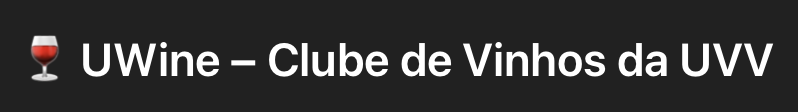

<center>

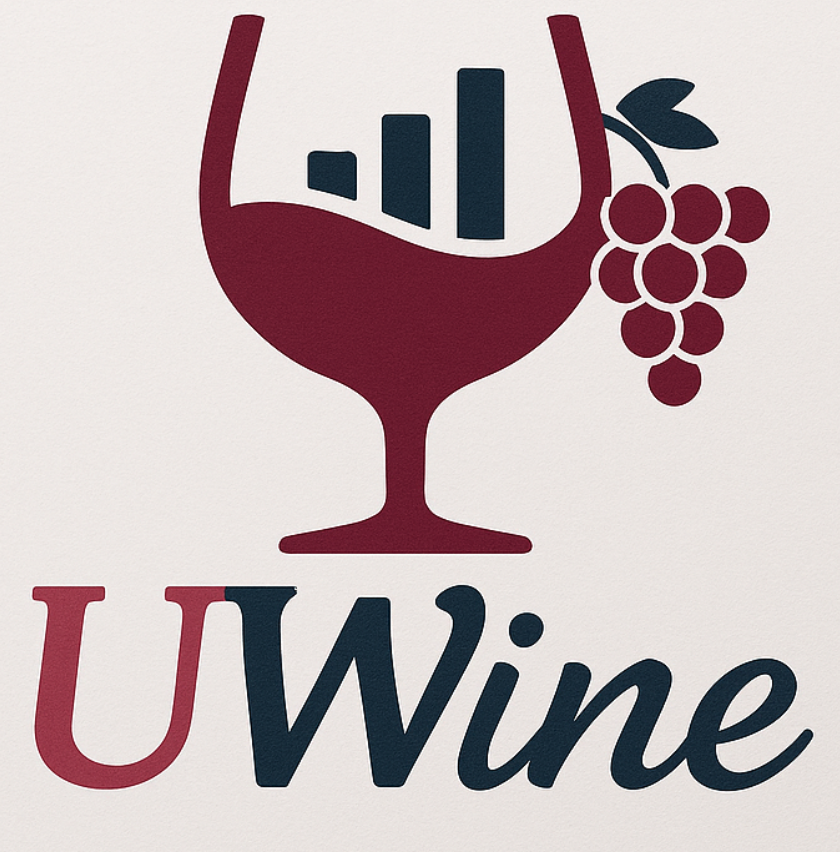

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [ ]:
# Estruturacao dos Dados: NDArray / Pandas
import pandas as pd
import numpy as np

# Inferencia Estatistica
import scipy.stats as stats
from scipy.stats import bootstrap

# Visualizacao dos Dados
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# load do TABLE 15 aqui:
from google.colab import drive
drive.mount('/content/drive')

CAMINHO_DADOS = "/content/drive/MyDrive/table15.csv"
table = pd.read_csv(CAMINHO_DADOS, index_col=0)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
table.head()

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,8280696,SUDESTE,MASCULINO,SOLTEIRO,1,16072.73,Entrega foi boa e rápida na UVVine,68.680,12.793772,2.633767,...,1.795519,2.319789,0.240472,1.330073,-0.064765,1.072148,1.079805,525.241692,PRIME,805.63
1,5608537,SUDESTE,MASCULINO,CASADO,0,3232.27,"Experiência regular, não atendeu a política de...",68.680,13.423075,4.088092,...,1.078118,2.238278,0.193774,1.053418,6.839390,1.096632,3.437159,529.479942,ESSENTIAL,195.93
2,2937609,SUDESTE,MASCULINO,SOLTEIRO,1,17275.53,Funcionou bem e me atendeu no prazo certo a UV...,68.680,11.521520,3.385091,...,2.232112,0.241930,0.371743,2.116762,1.872774,1.214197,3.631255,288.610853,PRIME,1384.03
3,5275399,SUL,MASCULINO,CASADO,3,7813.86,Foi indiferente minha experiência com a UVVine,68.680,13.546670,0.285701,...,2.166152,1.273382,0.286479,0.917310,2.444238,1.167041,2.814182,-34.111232,VIP,1017.79
4,1230503,SUDESTE,MASCULINO,CASADO,1,27885.50,Funcionou bem e me atendeu no prazo certo a UV...,76.659,12.192258,3.657386,...,2.079802,1.086254,0.402777,1.177515,10.291794,0.906324,3.141143,860.184850,PRIME,3348.25


In [ ]:
table.shape

(1120000, 23)

In [ ]:
display(table.head())

n_linhas, n_colunas = table.shape
print(f"Dimensão da base: {n_linhas:,} linhas e {n_colunas} colunas.")

table.info()

valores_nulos = table.isna().sum().sort_values(ascending=False)
valores_nulos = valores_nulos[valores_nulos > 0]

if len(valores_nulos) > 0:
    display(valores_nulos)
else:
    print("Não foram identificados valores ausentes na base de dados.")

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,8280696,SUDESTE,MASCULINO,SOLTEIRO,1,16072.73,Entrega foi boa e rápida na UVVine,68.680,12.793772,2.633767,...,1.795519,2.319789,0.240472,1.330073,-0.064765,1.072148,1.079805,525.241692,PRIME,805.63
1,5608537,SUDESTE,MASCULINO,CASADO,0,3232.27,"Experiência regular, não atendeu a política de...",68.680,13.423075,4.088092,...,1.078118,2.238278,0.193774,1.053418,6.839390,1.096632,3.437159,529.479942,ESSENTIAL,195.93
2,2937609,SUDESTE,MASCULINO,SOLTEIRO,1,17275.53,Funcionou bem e me atendeu no prazo certo a UV...,68.680,11.521520,3.385091,...,2.232112,0.241930,0.371743,2.116762,1.872774,1.214197,3.631255,288.610853,PRIME,1384.03
3,5275399,SUL,MASCULINO,CASADO,3,7813.86,Foi indiferente minha experiência com a UVVine,68.680,13.546670,0.285701,...,2.166152,1.273382,0.286479,0.917310,2.444238,1.167041,2.814182,-34.111232,VIP,1017.79
4,1230503,SUDESTE,MASCULINO,CASADO,1,27885.50,Funcionou bem e me atendeu no prazo certo a UV...,76.659,12.192258,3.657386,...,2.079802,1.086254,0.402777,1.177515,10.291794,0.906324,3.141143,860.184850,PRIME,3348.25


Dimensão da base: 1,120,000 linhas e 23 colunas.
<class 'pandas.core.frame.DataFrame'>
Index: 1120000 entries, 0 to 1119999
Data columns (total 23 columns):
 #   Column                              Non-Null Count    Dtype  
---  ------                              --------------    -----  
 0   NOTA FISCAL                         1120000 non-null  int64  
 1   REGIÃO                              1120000 non-null  object 
 2   SEXO                                1120000 non-null  object 
 3   ESTADO CIVIL                        1120000 non-null  object 
 4   DEPENDENTES                         1120000 non-null  int64  
 5   RENDA BRUTO (R$)                    1120000 non-null  float64
 6   OPINIÃO DO CLIENTE                  1120000 non-null  object 
 7   NOTA DE SATISFAÇÃO (%)              1120000 non-null  float64
 8   MEAN: alcohol                       1120000 non-null  float64
 9   MEAN: malic_acid                    1120000 non-null  float64
 10  MEAN: ash                         

In [ ]:
qualitativas = ["REGIÃO", "SEXO", "ESTADO CIVIL", "OPINIÃO DO CLIENTE", "TIPO DA CONTA"]

quantitativas = [
    "DEPENDENTES",
    "RENDA BRUTO (R$)",
    "NOTA DE SATISFAÇÃO (%)",
    "TOTAL (R$)",
    "MEAN: alcohol",
    "MEAN: malic_acid",
    "MEAN: ash",
    "MEAN: alcalinity_of_ash",
    "MEAN: magnesium",
    "MEAN: total_phenols",
    "MEAN: flavanoids",
    "MEAN: nonflavanoid_phenols",
    "MEAN: proanthocyanins",
    "MEAN: color_intensity",
    "MEAN: hue",
    "MEAN: od280/od315_of_diluted_wines",
    "MEAN: proline",
]

In [ ]:
RESULTADOS = {}

def calcular_tamanho_amostra_proporcao(N, z=1.96, p=0.5, e=0.05):
    """Calcula o tamanho mínimo da amostra para população finita e infinita."""
    numerador = (z ** 2) * p * (1 - p)
    denominador = e ** 2
    n = numerador / denominador

    n_ajustado = n / (1 + (n / N))
    return int(np.ceil(n)), int(np.ceil(n_ajustado))

In [ ]:
# Padrão dos gráficos (Paleta Moderna / Profissional)
PLOT_COLORS = {
    "main_line": "#1f77b4",
    "ref_line": "#ff7f0e",
    "ideal_pt": "#2ca02c",
    "zero": "#d62728",
    "ci": "#9467bd",
    "li": "#e377c2",
    "ls": "#17becf",
    "hist": "#4c72b0",
    "kde": "#dd8452",
}

# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

O objetivo aqui é determinar o tamanho de amostra necessário para refletir com precisão a população, com base na margem de erro e no nível de confiança desejados. Em seguida, avaliamos o comportamento dos dados (checando outliers e rodando testes estatísticos) para dar suporte técnico às análises seguintes.

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Para achar o tamanho ideal da amostra, analisamos a estabilização do erro-padrão da média para a variável TOTAL (R$). Fazemos isso simulando vários tamanhos de amostra e identificando o menor (n) que garanta um erro-padrão estimado menor ou igual ao erro-padrão médio.

In [ ]:
def AtividadeA1_1():
    y = table["TOTAL (R$)"].dropna()
    N = len(y)

    tamanhos = np.arange(100, 200_100, 100)
    erros_padrao = np.zeros(len(tamanhos), dtype=float)

    rng = np.random.default_rng(42)
    R_pequeno = 15
    R_grande = 3

    for idx, n in enumerate(tamanhos):
        R = R_pequeno if n <= 50_000 else R_grande
        se_rep = []

        for _ in range(R):
            seed = int(rng.integers(0, 1_000_000_000))
            amostra = y.sample(n=n, replace=False, random_state=seed)
            se_rep.append(amostra.std(ddof=1) / np.sqrt(n))

        erros_padrao[idx] = np.mean(se_rep)

    se_medio = float(erros_padrao.mean())
    media_total = float(y.mean())

    ic_inf = media_total - 1.96 * se_medio
    ic_sup = media_total + 1.96 * se_medio

    idx_ideal = int(np.where(erros_padrao <= se_medio)[0][0])
    n_ideal = int(tamanhos[idx_ideal])
    se_ideal = float(erros_padrao[idx_ideal])

    RESULTADOS["A1.1"] = {
        "N": int(N),
        "media_total": media_total,
        "se_medio": se_medio,
        "ic_95": (float(ic_inf), float(ic_sup)),
        "tamanho_ideal": n_ideal,
        "tamanhos": tamanhos,
        "erros_padrao": erros_padrao,
        "se_ideal": se_ideal,
    }

    print(f"População disponível (N): {N:,}")
    print(f"Média de TOTAL (R$): {media_total:.2f}")
    print(f"Erro-padrão-médio: {se_medio:.6f}")
    print(f"IC 95% da média: [{ic_inf:.2f}, {ic_sup:.2f}]")
    print(f"Tamanho ideal da amostra: {n_ideal:,}")

In [ ]:
def AtividadeA1_1_grupos():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    resultados_grupos = []

    rng = np.random.default_rng(42)

    for grupo in grupos_alvo:
        df_grupo = table[table["TIPO DA CONTA"] == grupo].copy()
        y = df_grupo["TOTAL (R$)"].dropna()
        N = len(y)

        tamanhos = np.arange(100, min(N, 200000) + 1, 100)
        erros_padrao = np.zeros(len(tamanhos), dtype=float)

        R_pequeno = 15
        R_grande = 3

        for idx, n in enumerate(tamanhos):
            R = R_pequeno if n <= 50000 else R_grande
            se_rep = []

            for _ in range(R):
                seed = int(rng.integers(0, 1_000_000_000))
                amostra = y.sample(n=n, replace=False, random_state=seed)
                se_rep.append(amostra.std(ddof=1) / np.sqrt(n))

            erros_padrao[idx] = np.mean(se_rep)

        se_medio = float(erros_padrao.mean())
        media_total = float(y.mean())

        ic_inf = media_total - 1.96 * se_medio
        ic_sup = media_total + 1.96 * se_medio

        idx_ideal = int(np.where(erros_padrao <= se_medio)[0][0])
        n_ideal = int(tamanhos[idx_ideal])
        se_ideal = float(erros_padrao[idx_ideal])

        resultados_grupos.append({
            "grupo": grupo,
            "N": int(N),
            "media_total": media_total,
            "se_medio": se_medio,
            "ic_inf": float(ic_inf),
            "ic_sup": float(ic_sup),
            "tamanho_ideal": n_ideal,
            "se_ideal": se_ideal,
            "tamanhos": tamanhos,
            "erros_padrao": erros_padrao,
        })

    RESULTADOS["A1.1_grupos"] = resultados_grupos

    print("Análise da amostragem por grupos concluída.")
    print(f"Grupos analisados: {', '.join([r['grupo'] for r in resultados_grupos])}")

In [ ]:
AtividadeA1_1()
resultado = RESULTADOS["A1.1"]

População disponível (N): 1,120,000
Média de TOTAL (R$): 810.27
Erro-padrão-médio: 3.674712
IC 95% da média: [803.07, 817.47]
Tamanho ideal da amostra: 51,400


In [ ]:
AtividadeA1_1_grupos()
resultado_grupos = RESULTADOS["A1.1_grupos"]

Análise da amostragem por grupos concluída.
Grupos analisados: ESSENTIAL, PRIME, VIP


In [ ]:
resumo_grupos = pd.DataFrame([
    {
        "Grupo": r["grupo"],
        "N_grupo": r["N"],
        "Média TOTAL (R$)": r["media_total"],
        "SE médio": r["se_medio"],
        "IC95% inferior": r["ic_inf"],
        "IC95% superior": r["ic_sup"],
        "Tamanho ideal": r["tamanho_ideal"],
    }
    for r in resultado_grupos
])

display(resumo_grupos.round(4))

,Grupo,N_grupo,Média TOTAL (R$),SE médio,IC95% inferior,IC95% superior,Tamanho ideal
0,ESSENTIAL,683501,403.8689,1.3145,401.2925,406.4454,50900
1,PRIME,183226,2192.3250,4.8290,2182.8602,2201.7899,47500
2,VIP,253273,907.1823,2.0027,903.2570,911.1077,51500


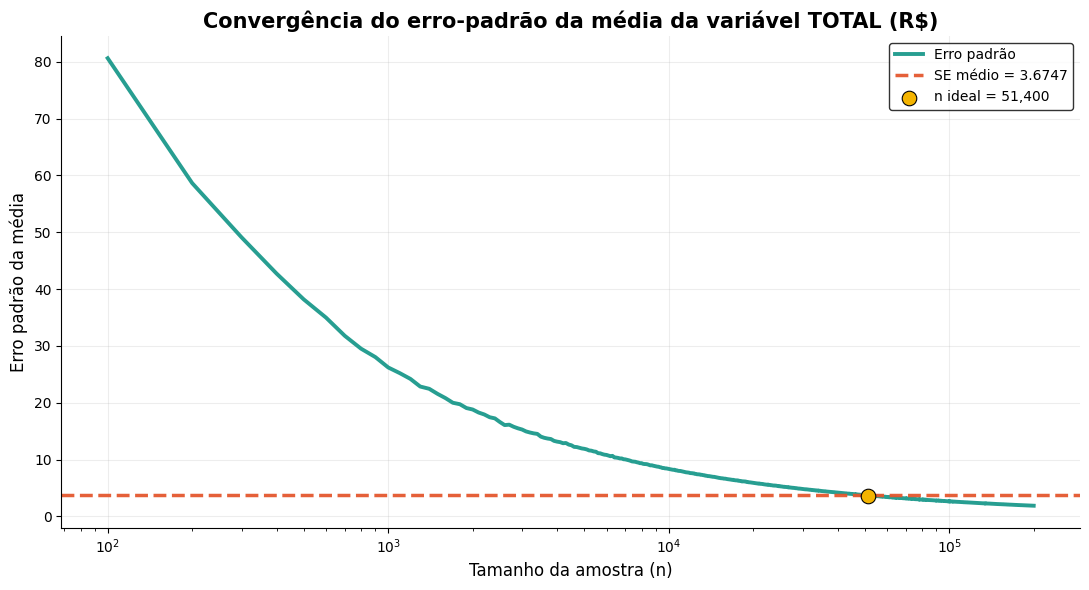

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (linha principal)
    "ref_line":  "#E4572E",   # laranja avermelhado (linha de referência)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (ponto ideal)
}

plt.figure(figsize=(11, 6))
plt.plot(
    resultado["tamanhos"],
    resultado["erros_padrao"],
    color=PLOT_COLORS["main_line"],
    linewidth=2.8,
    alpha=0.95,
    label="Erro padrão",
)
plt.axhline(
    resultado["se_medio"],
    color=PLOT_COLORS["ref_line"],
    linestyle="--",
    linewidth=2.5,
    alpha=0.95,
    label=f'SE médio = {resultado["se_medio"]:.4f}',
)
plt.scatter(
    resultado["tamanho_ideal"],
    resultado["se_ideal"],
    color=PLOT_COLORS["ideal_pt"],
    s=110,
    zorder=6,
    edgecolor="black",
    linewidth=0.8,
    label=f'n ideal = {resultado["tamanho_ideal"]:,}',
)
plt.title("Convergência do erro-padrão da média da variável TOTAL (R$)", fontsize=15, fontweight="bold")
plt.xlabel("Tamanho da amostra (n)", fontsize=12)
plt.xscale("log")
plt.ylabel("Erro padrão da média", fontsize=12)
plt.grid(alpha=0.22)
plt.legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()

Os resultados mostram que o erro-padrão da média cai à medida que a amostra aumenta, estabilizando de forma progressiva ao longo das simulações. Aplicando o critério $SE(n) \le SE\text{ médio}$, chegamos ao tamanho ideal de $n = 51.400$, que será o valor adotado nas próximas etapas do estudo.

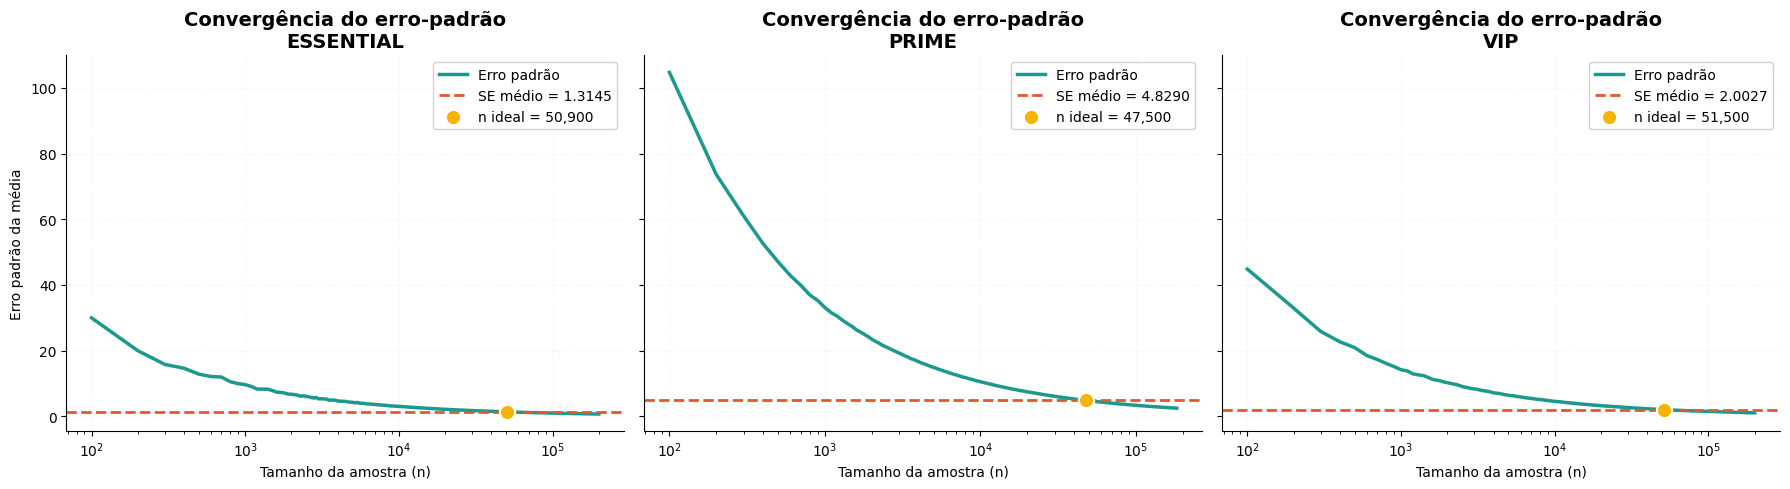

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (linha principal)
    "ref_line":  "#E4572E",   # laranja avermelhado (linha de referência)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (ponto ideal)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, r in zip(axes, resultado_grupos):
    ax.plot(
        r["tamanhos"],
        r["erros_padrao"],
        color=PLOT_COLORS["main_line"],
        linewidth=2.5,
        label="Erro padrão"
    )

    ax.axhline(
        r["se_medio"],
        color=PLOT_COLORS["ref_line"],
        linestyle="--",
        linewidth=2,
        label=f'SE médio = {r["se_medio"]:.4f}'
    )

    ax.scatter(
        r["tamanho_ideal"],
        r["se_ideal"],
        color=PLOT_COLORS["ideal_pt"],
        s=120,
        edgecolor="white",  # Borda branca destaca melhor o ponto
        linewidth=1.5,
        zorder=5,
        label=f'n ideal = {r["tamanho_ideal"]:,}'
    )

    ax.set_title(f'Convergência do erro-padrão\n{r["grupo"]}', fontsize=14, fontweight="bold")
    ax.set_xlabel("Tamanho da amostra (n)")
    ax.set_xscale("log")
    ax.grid(True, alpha=0.15, linestyle=":")
    ax.legend(frameon=True, facecolor="white", framealpha=0.9, edgecolor="#cccccc")

axes[0].set_ylabel("Erro padrão da média")
plt.tight_layout()
sns.despine()
plt.show()

Os gráficos por grupo mostram que o erro-padrão da média da variável `TOTAL (R$)` apresenta o mesmo comportamento de convergência observado na análise global em ESSENTIAL, PRIME e VIP. Em todos os segmentos, o erro-padrão cai de forma acentuada nas amostras menores, entre 100 e 1.000 observações, e se estabiliza a partir de aproximadamente 10.000, quando a curva passa a ficar próxima da linha do SE médio. O grupo PRIME apresentou a maior variabilidade inicial, com erro-padrão acima de 100 nas menores amostras e SE médio de 4,8290, o que indica maior dispersão dos valores de `TOTAL (R$)` nesse segmento. Já ESSENTIAL teve o menor SE médio (1,3145) e VIP ficou em posição intermediária (2,0027). O tamanho ideal da amostra ficou entre 47.500 e 51.500 observações (50.900 em ESSENTIAL, 47.500 em PRIME e 51.500 em VIP), faixa em que o ganho de precisão por observação adicional se torna marginal. Dessa forma, conclui-se que a estabilização do erro-padrão também ocorre de forma consistente dentro de cada segmento, sustentando a representatividade estatística da variável `TOTAL (R$)` tanto no nível global quanto no nível estratificado.

###Atividade A1.2: Analisar os outliers

Nesta etapa, analisam-se as variáveis numéricas para identificar concentração excessiva de valores, extremos e problemas de qualidade dos dados. Em variáveis monetárias, valores altos podem representar clientes de maior valor e não devem ser tratados automaticamente como erro, enquanto valores negativos são incompatíveis com a natureza das variáveis e devem ser tratados como inconsistências. O foco é distinguir extremos plausíveis de negócio de registros inconsistentes, preservando a informação relevante para as análises estratificadas posteriores.

In [ ]:
serie = table["NOTA DE SATISFAÇÃO (%)"]

resumo = serie.describe().to_frame(name="Valor")
frequencias = serie.value_counts().head(10).to_frame(name="Frequência")
proporcoes = (serie.value_counts(normalize=True).head(10) * 100).to_frame(name="Percentual (%)")

display(resumo)
print(f"Quantidade de valores únicos: {serie.nunique():,}")
display(frequencias)
display(proporcoes.round(3))

,Valor
count,1.120000e+06
mean,6.900971e+01
std,1.473340e+00
min,6.868000e+01
25%,6.868000e+01
50%,6.868000e+01
75%,6.868000e+01
max,9.261700e+01


Quantidade de valores únicos: 212


,Frequência
NOTA DE SATISFAÇÃO (%),
68.680,1036840
68.882,1261
68.983,1241
69.286,1240
69.084,1224
70.599,1223
69.690,1220
69.185,1208
69.488,1207


,Percentual (%)
NOTA DE SATISFAÇÃO (%),
68.680,92.575
68.882,0.113
68.983,0.111
69.286,0.111
69.084,0.109
70.599,0.109
69.690,0.109
69.185,0.108
69.488,0.108


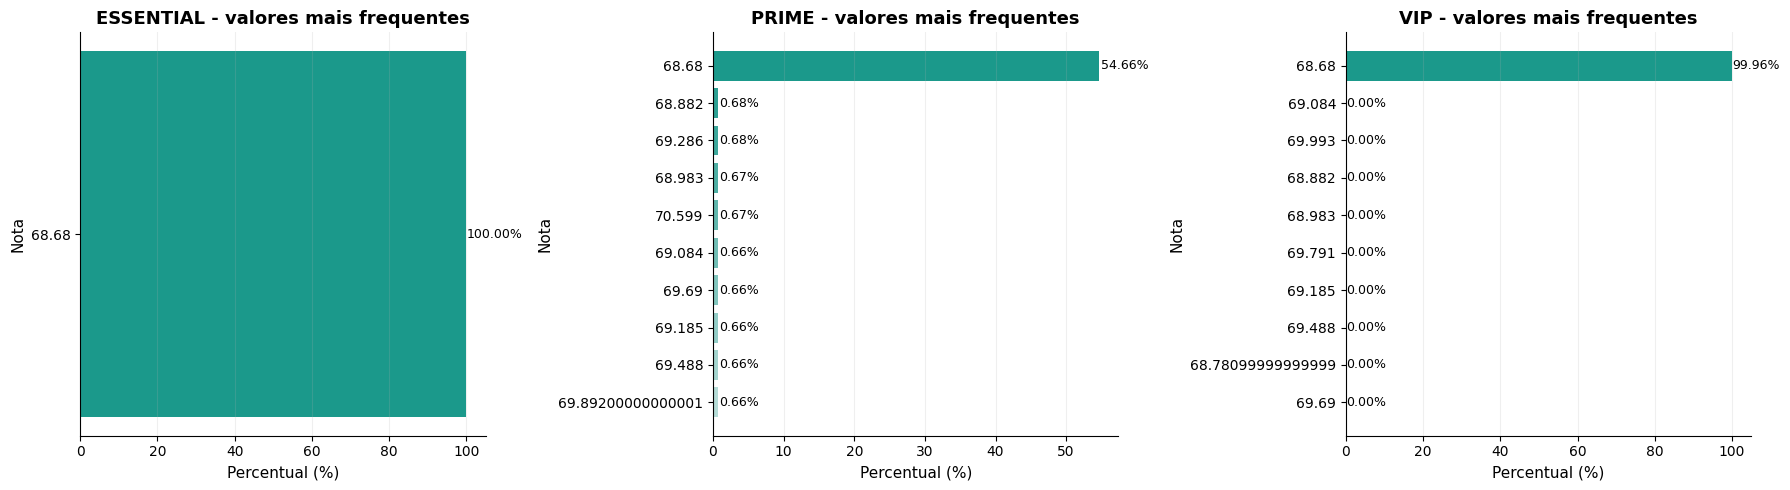

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (linha principal)
    "ref_line":  "#E4572E",   # laranja avermelhado (linha de referência)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (ponto ideal)
}

grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)

for ax, grupo in zip(axes, grupos_alvo):
    serie_grupo = table.loc[table["TIPO DA CONTA"] == grupo, "NOTA DE SATISFAÇÃO (%)"].dropna()
    top_valores = (serie_grupo.value_counts(normalize=True).head(10) * 100).sort_values()

    # Degradê do verde-azulado: barras menores mais claras, maiores mais escuras
    cores = sns.light_palette(PLOT_COLORS["main_line"], n_colors=len(top_valores) + 3)[3:]

    bars = ax.barh(
        top_valores.index.astype(str),
        top_valores.values,
        color=cores
    )

    ax.set_title(f"{grupo} - valores mais frequentes", fontsize=13, fontweight="bold")
    ax.set_xlabel("Percentual (%)", fontsize=11)
    ax.set_ylabel("Nota", fontsize=11)
    ax.grid(axis="x", alpha=0.20)

    for bar in bars:
        largura = bar.get_width()
        ax.text(
            largura + 0.2,
            bar.get_y() + bar.get_height() / 2,
            f"{largura:.2f}%",
            va="center",
            fontsize=9
        )

plt.tight_layout()
sns.despine()
plt.show()

In [ ]:
def diagnosticar_variavel_numerica(dados, coluna):
    serie = pd.to_numeric(dados[coluna], errors="coerce")

    negativos = int((serie < 0).sum())
    perc_negativos = float((negativos / len(serie.dropna())) * 100) if len(serie.dropna()) > 0 else 0.0

    serie_valid = serie[serie >= 0].dropna()

    q1 = float(serie_valid.quantile(0.25))
    q3 = float(serie_valid.quantile(0.75))
    iqr = float(q3 - q1)

    li = float(q1 - 1.5 * iqr)
    ls = float(q3 + 1.5 * iqr)

    extremos_altos = int((serie_valid > ls).sum())
    extremos_baixos = int((serie_valid < li).sum())

    return {
        "N válidos": int(len(serie_valid)),
        "Negativos": negativos,
        "% negativos": perc_negativos,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "LI": li,
        "LS": ls,
        "Extremos baixos": extremos_baixos,
        "Extremos altos": extremos_altos,
    }


In [ ]:
def AtividadeA1_2():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    variaveis = ["RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)", "TOTAL (R$)"]

    resumo = []
    table_limpa = table.copy()

    for var in variaveis:
        table_limpa[var] = pd.to_numeric(table_limpa[var], errors="coerce")
        table_limpa.loc[table_limpa[var] < 0, var] = np.nan

    for grupo in grupos_alvo:
        df_grupo = table_limpa[table_limpa["TIPO DA CONTA"] == grupo].copy()

        for var in variaveis:
            info = diagnosticar_variavel_numerica(df_grupo, var)

            resumo.append({
                "Grupo": grupo,
                "Variável": var,
                **info
            })

    resumo_df = pd.DataFrame(resumo)

    RESULTADOS["A1.2"] = {
        "resumo": resumo_df,
        "table_limpa": table_limpa,
    }

    print("=-=-=-=-Análise de outliers e qualidade dos dados=-=-=-=-.")
    print(f"Grupos analisados: {', '.join(grupos_alvo)}")
    print("Valores negativos foram tratados como problema de qualidade.")
    print("Valores extremos altos foram mantidos para preservar sinal de negócio.")

In [ ]:
AtividadeA1_2()

resultado = RESULTADOS["A1.2"]

resumo_exibicao = resultado["resumo"].copy()
resumo_exibicao[["% negativos", "Q1", "Q3", "IQR", "LI", "LS"]] = (
    resumo_exibicao[["% negativos", "Q1", "Q3", "IQR", "LI", "LS"]].round(2)
)

display(resumo_exibicao)

=-=-=-=-Análise de outliers e qualidade dos dados=-=-=-=-.
Grupos analisados: ESSENTIAL, PRIME, VIP
Valores negativos foram tratados como problema de qualidade.
Valores extremos altos foram mantidos para preservar sinal de negócio.


,Grupo,Variável,N válidos,Negativos,% negativos,Q1,Q3,IQR,LI,LS,Extremos baixos,Extremos altos
0,ESSENTIAL,RENDA BRUTO (R$),683501,0,0.0,3197.49,3317.24,119.75,3017.86,3496.86,3847,31416
1,ESSENTIAL,NOTA DE SATISFAÇÃO (%),683501,0,0.0,68.68,68.68,0.00,68.68,68.68,0,0
2,ESSENTIAL,TOTAL (R$),683501,0,0.0,237.65,494.90,257.25,-148.22,880.78,0,19740
3,PRIME,RENDA BRUTO (R$),183226,0,0.0,18749.63,23024.47,4274.83,12337.39,29436.72,17795,166
4,PRIME,NOTA DE SATISFAÇÃO (%),183226,0,0.0,68.68,72.01,3.33,63.68,77.01,0,11036
5,PRIME,TOTAL (R$),183226,0,0.0,1313.85,3017.84,1703.99,-1242.13,5573.82,0,0
6,VIP,RENDA BRUTO (R$),253273,0,0.0,7555.21,8002.71,447.50,6883.96,8673.96,8987,21532
7,VIP,NOTA DE SATISFAÇÃO (%),253273,0,0.0,68.68,68.68,0.00,68.68,68.68,0,94
8,VIP,TOTAL (R$),253273,0,0.0,559.82,1176.74,616.92,-365.56,2102.12,0,5761


In [ ]:
nota_grupo = (
    table.groupby("TIPO DA CONTA")["NOTA DE SATISFAÇÃO (%)"]
    .agg(
        n="count",
        n_unicos="nunique",
        media="mean",
        dp="std",
        minimo="min",
        q1=lambda s: s.quantile(0.25),
        mediana="median",
        q3=lambda s: s.quantile(0.75),
        maximo="max",
    )
    .reset_index()
)

moda_grupo = (
    table.groupby("TIPO DA CONTA")["NOTA DE SATISFAÇÃO (%)"]
    .agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
    .reset_index(name="percentual_moda")
)

nota_grupo = nota_grupo.merge(moda_grupo, on="TIPO DA CONTA", how="left")
display(nota_grupo.round(4))

,TIPO DA CONTA,n,n_unicos,media,dp,minimo,q1,mediana,q3,maximo,percentual_moda
0,ESSENTIAL,683501,1,68.6800,0.0000,68.68,68.68,68.68,68.680,68.680,100.0000
1,PRIME,183226,212,70.6944,3.1419,68.68,68.68,68.68,72.013,92.617,54.6647
2,VIP,253273,42,68.6807,0.0525,68.68,68.68,68.68,68.680,76.558,99.9629


In [ ]:
COLUNA_GRUPO = "TIPO DA CONTA"
COLUNA_VALOR = "NOTA DE SATISFAÇÃO (%)"
GRUPOS = ["ESSENTIAL", "PRIME", "VIP"]
TOP_N = 10
COR = "#1B998B"

def top_valores(df, grupo, coluna=COLUNA_VALOR, coluna_grupo=COLUNA_GRUPO, n=TOP_N):
    serie = df.loc[df[coluna_grupo] == grupo, coluna].dropna()
    contagem = serie.value_counts()
    tabela = pd.DataFrame({
        "Contagem": contagem,
        "Percentual (%)": contagem / len(serie) * 100,
    }).head(n)
    tabela["Acumulado (%)"] = tabela["Percentual (%)"].cumsum()
    tabela.index.name = "Nota"
    return tabela, len(serie)

for grupo in GRUPOS:
    tabela, total = top_valores(table, grupo)
    print(f"\nGrupo: {grupo} | Registros válidos: {total:,}".replace(",", "."))
    display(
        tabela.style
        .format({"Contagem": "{:,.0f}", "Percentual (%)": "{:.2f}", "Acumulado (%)": "{:.2f}"})
        .background_gradient(subset=["Percentual (%)"], cmap=sns.light_palette(COR, as_cmap=True))
    )


Grupo: ESSENTIAL | Registros válidos: 683.501


,Contagem,Percentual (%),Acumulado (%)
Nota,,,
68.680000,"683,501",100.00,100.00



Grupo: PRIME | Registros válidos: 183.226


,Contagem,Percentual (%),Acumulado (%)
Nota,,,
68.680000,"100,160",54.66,54.66
68.882000,"1,255",0.68,55.35
69.286000,"1,239",0.68,56.03
68.983000,"1,236",0.67,56.70
70.599000,"1,221",0.67,57.37
69.690000,"1,217",0.66,58.03
69.084000,"1,217",0.66,58.70
69.185000,"1,204",0.66,59.35
69.488000,"1,203",0.66,60.01



Grupo: VIP | Registros válidos: 253.273


,Contagem,Percentual (%),Acumulado (%)
Nota,,,
68.680000,"253,179",99.96,99.96
69.993000,7,0.00,99.97
69.084000,7,0.00,99.97
68.882000,6,0.00,99.97
68.983000,5,0.00,99.97
69.488000,4,0.00,99.97
68.781000,4,0.00,99.98
69.185000,4,0.00,99.98
69.791000,4,0.00,99.98


In [ ]:
COLUNA_GRUPO = "TIPO DA CONTA"
COLUNA_OPINIAO = "OPINIÃO DO CLIENTE"
COLUNA_NOTA = "NOTA DE SATISFAÇÃO (%)"
TOP_N = 10
COR = "#1B998B"

coerencia = (
    table.groupby([COLUNA_GRUPO, COLUNA_OPINIAO], observed=True)[COLUNA_NOTA]
    .agg(
        Registros="size",        # inclui notas nulas
        Notas_validas="count",   # só notas preenchidas
        Media="mean",
        Mediana="median",
        Desvio_padrao="std",
        Minimo="min",
        Maximo="max",
        Notas_distintas="nunique",
    )
    .reset_index()
)

# Percentual de cada opinião dentro do respectivo tipo de conta
coerencia["% no grupo"] = (
    coerencia["Registros"] / coerencia.groupby(COLUNA_GRUPO)["Registros"].transform("sum") * 100
)

coerencia = coerencia.sort_values([COLUNA_GRUPO, "Registros"], ascending=[True, False])

for grupo, tabela in coerencia.groupby(COLUNA_GRUPO, sort=False):
    print(f"\nGrupo: {grupo}")
    display(
        tabela.drop(columns=COLUNA_GRUPO)
        .head(TOP_N)
        .set_index(COLUNA_OPINIAO)
        .style
        .format({
            "Registros": "{:,.0f}", "Notas_validas": "{:,.0f}",
            "Media": "{:.2f}", "Mediana": "{:.2f}", "Desvio_padrao": "{:.2f}",
            "Minimo": "{:.2f}", "Maximo": "{:.2f}", "% no grupo": "{:.2f}",
        })
        .background_gradient(subset=["% no grupo"], cmap=sns.light_palette(COR, as_cmap=True))
    )


Grupo: ESSENTIAL


,Registros,Notas_validas,Media,Mediana,Desvio_padrao,Minimo,Maximo,Notas_distintas,% no grupo
OPINIÃO DO CLIENTE,,,,,,,,,
Entrega foi boa e rápida na UVVine,"105,579","105,579",68.68,68.68,0.00,68.68,68.68,1,15.45
Funcionou bem e me atendeu no prazo certo a UVVine,"105,452","105,452",68.68,68.68,0.00,68.68,68.68,1,15.43
Fiquei satisfeito com o serviço da UVVine,"105,288","105,288",68.68,68.68,0.00,68.68,68.68,1,15.40
"Serviço eficiente, recomendo o clube: UVVine","104,858","104,858",68.68,68.68,0.00,68.68,68.68,1,15.34
Gostei do atendimento prestado pela UVVine,"104,822","104,822",68.68,68.68,0.00,68.68,68.68,1,15.34
Nada digno de nota com a UVVine,"20,751","20,751",68.68,68.68,0.00,68.68,68.68,1,3.04
Foi indiferente minha experiência com a UVVine,"20,639","20,639",68.68,68.68,0.00,68.68,68.68,1,3.02
Não tenho muito a dizer sobre a UVVine,"20,570","20,570",68.68,68.68,0.00,68.68,68.68,1,3.01
"Compro exponenciamente, opinião neutra sobre UVVine","20,491","20,491",68.68,68.68,0.00,68.68,68.68,1,3.00



Grupo: PRIME


,Registros,Notas_validas,Media,Mediana,Desvio_padrao,Minimo,Maximo,Notas_distintas,% no grupo
OPINIÃO DO CLIENTE,,,,,,,,,
Gostei do atendimento prestado pela UVVine,"28,484","28,484",70.73,68.68,3.18,68.68,92.21,188,15.55
Fiquei satisfeito com o serviço da UVVine,"28,390","28,390",70.70,68.68,3.16,68.68,91.10,187,15.49
"Serviço eficiente, recomendo o clube: UVVine","28,219","28,219",70.66,68.68,3.09,68.68,89.99,184,15.40
Entrega foi boa e rápida na UVVine,"28,165","28,165",70.70,68.68,3.14,68.68,89.49,182,15.37
Funcionou bem e me atendeu no prazo certo a UVVine,"28,147","28,147",70.69,68.68,3.15,68.68,89.28,184,15.36
Nada digno de nota com a UVVine,"5,531","5,531",70.71,68.68,3.14,68.68,87.06,159,3.02
Foi indiferente minha experiência com a UVVine,"5,487","5,487",70.64,68.68,3.09,68.68,87.97,157,2.99
Sem opinião formada sobre a UVVine,"5,485","5,485",70.71,68.68,3.14,68.68,88.98,159,2.99
"Compro exponenciamente, opinião neutra sobre UVVine","5,410","5,410",70.75,68.68,3.24,68.68,87.87,158,2.95



Grupo: VIP


,Registros,Notas_validas,Media,Mediana,Desvio_padrao,Minimo,Maximo,Notas_distintas,% no grupo
OPINIÃO DO CLIENTE,,,,,,,,,
"Serviço eficiente, recomendo o clube: UVVine","39,161","39,161",68.68,68.68,0.06,68.68,75.45,16,15.46
Entrega foi boa e rápida na UVVine,"39,074","39,074",68.68,68.68,0.04,68.68,73.22,12,15.43
Funcionou bem e me atendeu no prazo certo a UVVine,"39,040","39,040",68.68,68.68,0.07,68.68,75.95,17,15.41
Gostei do atendimento prestado pela UVVine,"38,876","38,876",68.68,68.68,0.05,68.68,75.35,9,15.35
Fiquei satisfeito com o serviço da UVVine,"38,845","38,845",68.68,68.68,0.05,68.68,75.95,9,15.34
Não tenho muito a dizer sobre a UVVine,"7,603","7,603",68.68,68.68,0.00,68.68,68.78,2,3.00
Nada digno de nota com a UVVine,"7,577","7,577",68.68,68.68,0.05,68.68,71.61,7,2.99
Sem opinião formada sobre a UVVine,"7,567","7,567",68.68,68.68,0.09,68.68,76.56,5,2.99
Foi indiferente minha experiência com a UVVine,"7,547","7,547",68.68,68.68,0.05,68.68,72.72,4,2.98


In [ ]:
colunas_numericas = ["RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)", "TOTAL (R$)"]

negativos_df = pd.DataFrame([
    {
        "Variável": col,
        "Qtd negativos": int((pd.to_numeric(table[col], errors="coerce") < 0).sum()),
        "% negativos": float(((pd.to_numeric(table[col], errors="coerce") < 0).sum() / len(table)) * 100)
    }
    for col in colunas_numericas
])

display(negativos_df.round(4))

,Variável,Qtd negativos,% negativos
0,RENDA BRUTO (R$),0,0.0
1,NOTA DE SATISFAÇÃO (%),0,0.0
2,TOTAL (R$),0,0.0


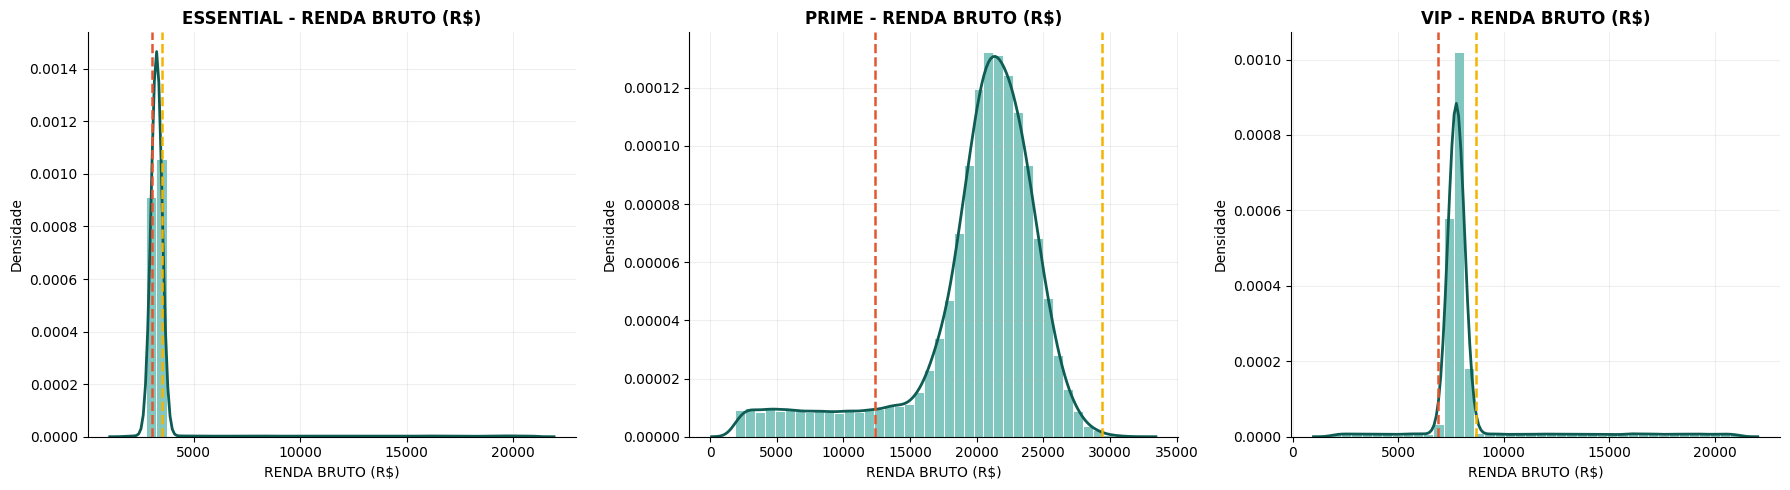

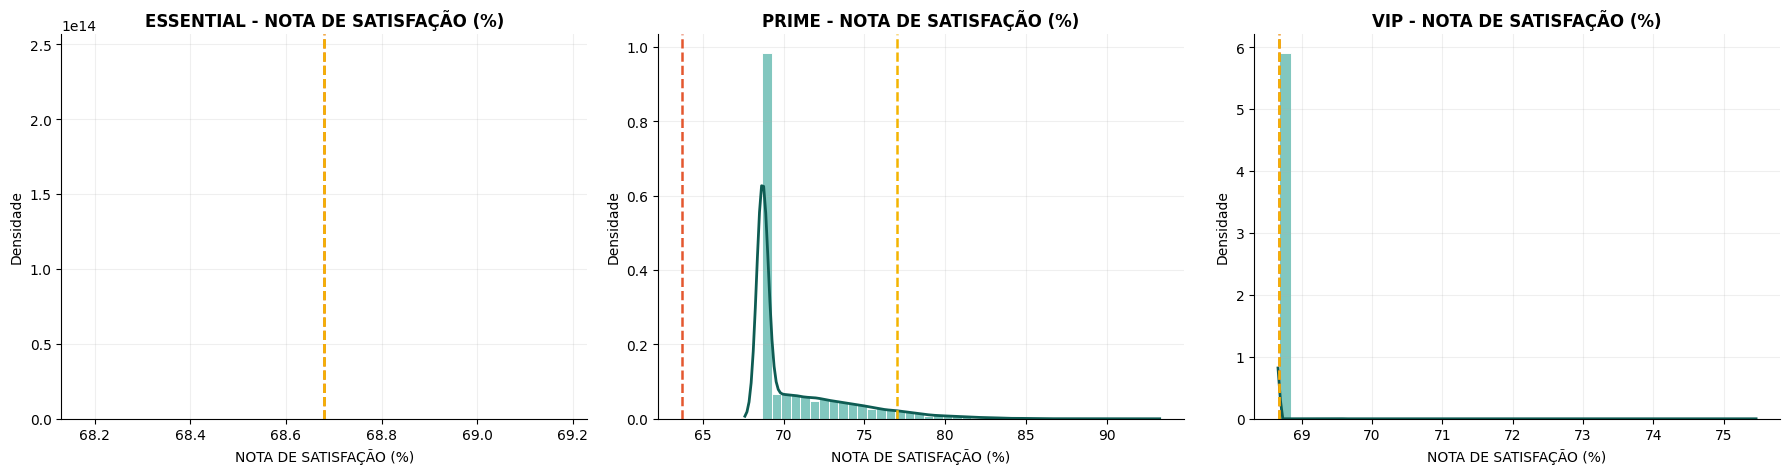

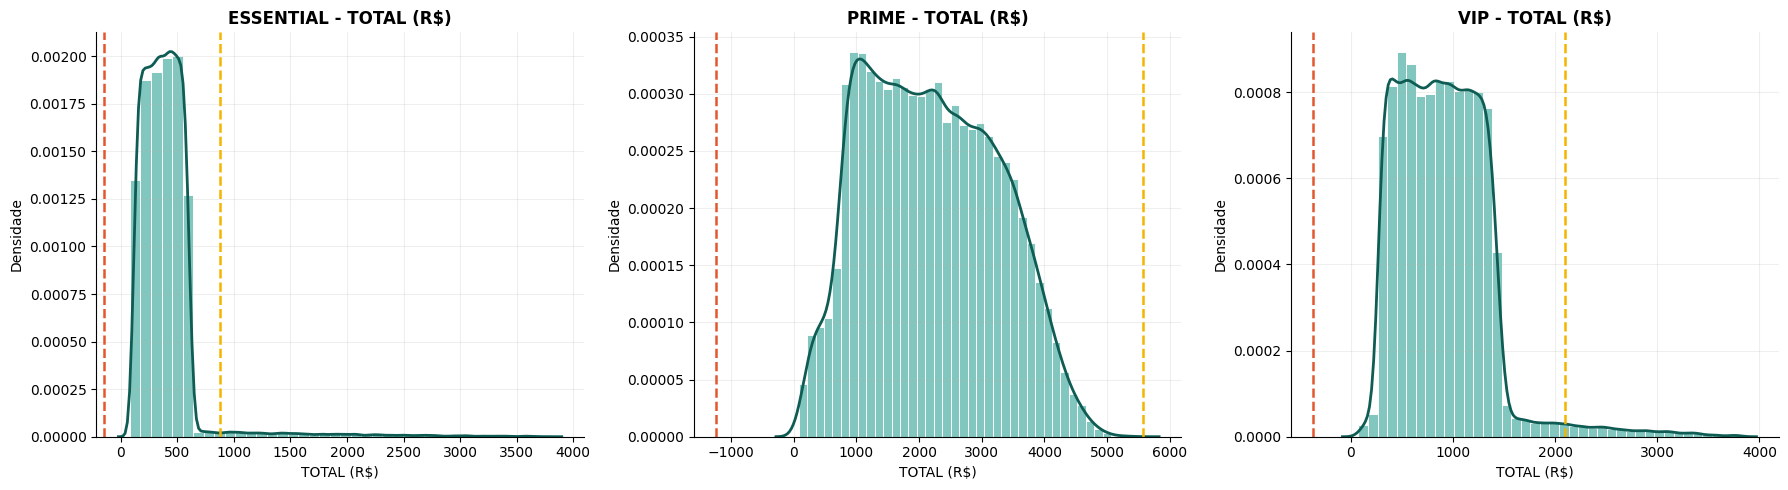

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (histograma)
    "ref_line":  "#E4572E",   # laranja avermelhado (LI)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (LS)
    "kde_line":  "#0E5C53",   # verde-azulado escuro (curva KDE)
}

variaveis = ["RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)", "TOTAL (R$)"]
grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]

for var in variaveis:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

    for ax, grupo in zip(axes, grupos_alvo):
        df_grupo = resultado["table_limpa"][resultado["table_limpa"]["TIPO DA CONTA"] == grupo].copy()
        serie_plot = df_grupo[var].dropna()

        if len(serie_plot) > 50000:
            serie_plot = serie_plot.sample(50000, random_state=42)

        info = (
            resultado["resumo"]
            .query("Grupo == @grupo and Variável == @var")
            .iloc[0]
        )

        sns.histplot(
            serie_plot,
            bins=40,
            stat="density",
            color=PLOT_COLORS["main_line"],
            edgecolor="white",
            alpha=0.55,
            ax=ax
        )

        sns.kdeplot(
            serie_plot,
            color=PLOT_COLORS["kde_line"],
            linewidth=2.0,
            ax=ax
        )

        ax.axvline(info["LI"], color=PLOT_COLORS["ref_line"], linestyle="--", linewidth=1.8, label="LI")
        ax.axvline(info["LS"], color=PLOT_COLORS["ideal_pt"], linestyle="--", linewidth=1.8, label="LS")
        ax.set_title(f"{grupo} - {var}", fontsize=12, fontweight="bold")
        ax.set_xlabel(var, fontsize=10)
        ax.set_ylabel("Densidade", fontsize=10)
        ax.grid(alpha=0.20)

    plt.tight_layout()
    sns.despine()
    plt.show()

A análise das variáveis monetárias mostrou perfis distintos entre os grupos. Em `RENDA BRUTO (R$)`, ESSENTIAL se concentra entre cerca de 3.000 e 3.500, com cauda direita muito rala que chega a cerca de 22.000, e tem 31.416 extremos altos (4,60%) e 3.847 baixos (0,56%). Em VIP, a concentração fica entre 7.500 e 8.000, com 21.532 extremos altos (8,50%) e 8.987 baixos (3,55%). PRIME é o grupo mais disperso: os limites do critério do IQR ficam em 12.337,39 e 29.436,72 e predominam os extremos baixos (17.795, ou 9,71%, contra apenas 166 altos), reflexo da cauda à esquerda observada no gráfico.

Em `TOTAL (R$)`, ESSENTIAL e VIP concentram a maior parte dos valores em faixas curtas (cerca de 100 a 600 e de 300 a 1.500) e têm cauda direita longa, que chega a cerca de 4.000, enquanto PRIME se distribui de forma ampla, até cerca de 5.800. Como os limites inferiores são negativos nos três grupos, não há extremos baixos. Os extremos altos aparecem em ESSENTIAL (19.740, ou 2,89%) e em VIP (5.761, ou 2,27%), e PRIME não tem extremos. Como esses valores podem representar clientes de maior valor, foram mantidos na base, e não houve valores negativos em nenhuma das três variáveis.

A NOTA DE SATISFAÇÃO (%) apresentou forte concentração em 68,68, valor presente em 92,575% dos registros da base. Em ESSENTIAL, todos os registros têm essa nota, e em VIP ela responde por 99,96% das observações (desvio padrão de 0,0525, com apenas 94 extremos altos). Apenas PRIME apresenta variação relevante, com média de 70,6944, desvio padrão de 3,1419 e 11.036 extremos altos (6,02%). Como o IQR é zero em ESSENTIAL e em VIP, os limites LI e LS coincidem com 68,68 e o critério perde o sentido nesses grupos.

Contudo, a nota não acompanha a opinião registrada. Entre as dez opiniões mais frequentes, ESSENTIAL tem a mesma nota (68,68) em todas, VIP varia no máximo de 68,68 a 76,56, e em PRIME as médias ficam entre 70,64 e 70,75 independentemente de a opinião ser positiva ou neutra. Dessa forma, a variável tem pouca utilidade como medida contínua de satisfação, e as análises seguintes usarão OPINIÃO DO CLIENTE.

###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

Na parte de hipóteses, aplicam-se testes para analisar o comportamento estatístico da variável TOTAL (R\$) e confirmar a estabilidade da amostragem estratificada nos grupos ESSENTIAL, PRIME e VIP.

A validação é feita separadamente em cada grupo, usando o tamanho ideal de amostra definido na Atividade A1.1. Em cada segmento, o processo gera reamostragens sucessivas, divide cada uma em train, validation e test, e aceita somente as rodadas em que as três partições ficam dentro do intervalo de confiança de referência da média do grupo.

Como complemento, o teste de Shapiro-Wilk é aplicado a amostras controladas para verificar a normalidade, e o bootstrap é usado para medir a estabilidade da diferença entre a média amostral e a média populacional de cada grupo. Assim, a etapa busca confirmar se a amostragem escolhida se mantém estatisticamente consistente quando o procedimento é repetido várias vezes.

In [ ]:
from scipy.stats import shapiro

def AtividadeA1_3(alpha=0.05, z_95=1.96, B=2000, n_rodadas_validas=20, max_tentativas=200, random_state=42):
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]

    if "A1.1_grupos" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.1 por grupos antes desta etapa.")

    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()

    mapa_n_ideal = {
        item["grupo"]: int(item["tamanho_ideal"])
        for item in RESULTADOS["A1.1_grupos"]
    }

    rng = np.random.default_rng(random_state)
    resultados_grupos = []

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()
        y_full = pd.to_numeric(df_grupo["TOTAL (R$)"], errors="coerce").dropna()

        N = len(y_full)
        n_ideal = mapa_n_ideal.get(grupo)

        if n_ideal is None or N == 0:
            continue

        mu_pop = float(y_full.mean())
        sd_pop = float(y_full.std(ddof=1))
        se_ref = float(sd_pop / np.sqrt(n_ideal))

        ic_ref_inf = float(mu_pop - z_95 * se_ref)
        ic_ref_sup = float(mu_pop + z_95 * se_ref)

        n_norm = min(5000, N)
        y_norm = y_full.sample(n=n_norm, random_state=random_state) if N > n_norm else y_full.copy()
        sh_stat, sh_p = shapiro(y_norm)
        decisao_normalidade = "Rejeita normalidade" if sh_p <= alpha else "Não rejeita normalidade"

        rodadas_validas = []
        tentativas_log = []
        tentativas = 0

        while len(rodadas_validas) < n_rodadas_validas and tentativas < max_tentativas:
            tentativas += 1

            seed_amostra = int(rng.integers(0, 1_000_000_000))
            amostra = y_full.sample(n=n_ideal, replace=False, random_state=seed_amostra)

            seed_split = int(rng.integers(0, 1_000_000_000))
            amostra_emb = amostra.sample(frac=1, random_state=seed_split)

            n_train = int(n_ideal * 0.60)
            n_val = int(n_ideal * 0.20)
            n_test = n_ideal - n_train - n_val

            train = amostra_emb.iloc[:n_train]
            validation = amostra_emb.iloc[n_train:n_train + n_val]
            test = amostra_emb.iloc[n_train + n_val:n_train + n_val + n_test]

            media_amostra = float(amostra.mean())
            media_train = float(train.mean())
            media_val = float(validation.mean())
            media_test = float(test.mean())

            dentro_train = ic_ref_inf <= media_train <= ic_ref_sup
            dentro_val = ic_ref_inf <= media_val <= ic_ref_sup
            dentro_test = ic_ref_inf <= media_test <= ic_ref_sup

            passou_ic = dentro_train and dentro_val and dentro_test

            tentativas_log.append({
                "tentativa": tentativas,
                "media_train": media_train,
                "media_validation": media_val,
                "media_test": media_test,
                "status_train": "Dentro do IC" if dentro_train else "Fora do IC",
                "status_validation": "Dentro do IC" if dentro_val else "Fora do IC",
                "status_test": "Dentro do IC" if dentro_test else "Fora do IC",
                "aceita": passou_ic,
            })

            if not passou_ic:
                continue

            valores = amostra.values
            n = len(valores)
            boot_means = np.empty(B, dtype=float)

            for b in range(B):
                idx = rng.integers(0, n, size=n)
                boot_means[b] = valores[idx].mean()

            boot_diff = boot_means - mu_pop
            ci_boot_inf = float(np.percentile(boot_diff, 2.5))
            ci_boot_sup = float(np.percentile(boot_diff, 97.5))
            p_boot = float(min(1.0, 2 * min((boot_diff <= 0).mean(), (boot_diff >= 0).mean())))

            rodadas_validas.append({
                "rodada": len(rodadas_validas) + 1,
                "media_amostra": media_amostra,
                "media_train": media_train,
                "media_validation": media_val,
                "media_test": media_test,
                "diff_obs": float(media_amostra - mu_pop),
                "ci_boot_diff_inf": ci_boot_inf,
                "ci_boot_diff_sup": ci_boot_sup,
                "p_boot": p_boot,
                "inclui_zero": bool(ci_boot_inf <= 0 <= ci_boot_sup),
                "boot_diff": boot_diff,
            })

        df_rodadas = pd.DataFrame([
            {k: v for k, v in r.items() if k != "boot_diff"}
            for r in rodadas_validas
        ])

        taxa_aceite = float(len(rodadas_validas) / tentativas) if tentativas > 0 else 0.0

        resultados_grupos.append({
            "grupo": grupo,
            "N": int(N),
            "n_ideal": int(n_ideal),
            "media_populacao": mu_pop,
            "dp_populacao": sd_pop,
            "se_referencia": se_ref,
            "ic_referencia": (ic_ref_inf, ic_ref_sup),
            "normalidade": {
                "n_amostra": int(len(y_norm)),
                "shapiro_stat": float(sh_stat),
                "shapiro_p": float(sh_p),
                "decisao": decisao_normalidade,
                "amostra": y_norm,
            },
            "validacao": {
                "n_rodadas_validas": int(len(rodadas_validas)),
                "max_rodadas_planejadas": int(n_rodadas_validas),
                "tentativas": int(tentativas),
                "taxa_aceite": taxa_aceite,
                "rodadas": rodadas_validas,
                "tabela_rodadas": df_rodadas,
                "tentativas_log": pd.DataFrame(tentativas_log),
            }
        })

    RESULTADOS["A1.3"] = {
        "alpha": float(alpha),
        "z_95": float(z_95),
        "B": int(B),
        "n_rodadas_validas": int(n_rodadas_validas),
        "max_tentativas": int(max_tentativas),
        "grupos": resultados_grupos,
    }

    print("Análise de hipóteses estratificada concluída.")
    for item in resultados_grupos:
        print(
            f"{item['grupo']}: "
            f"{item['validacao']['n_rodadas_validas']}/{n_rodadas_validas} rodadas válidas "
            f"(taxa de aceite = {item['validacao']['taxa_aceite']:.2%})"
        )


In [ ]:
AtividadeA1_3()
resultado = RESULTADOS["A1.3"]

Análise de hipóteses estratificada concluída.
ESSENTIAL: 20/20 rodadas válidas (taxa de aceite = 39.22%)
PRIME: 20/20 rodadas válidas (taxa de aceite = 57.14%)
VIP: 20/20 rodadas válidas (taxa de aceite = 29.85%)


In [ ]:
resumo_a13 = pd.DataFrame([
    {
        "Grupo": item["grupo"],
        "N": item["N"],
        "n ideal": item["n_ideal"],
        "Shapiro W": item["normalidade"]["shapiro_stat"],
        "Shapiro p-valor": item["normalidade"]["shapiro_p"],
        "Decisão normalidade": item["normalidade"]["decisao"],
        "Rodadas válidas": item["validacao"]["n_rodadas_validas"],
        "Tentativas": item["validacao"]["tentativas"],
        "Taxa de aceite (%)": item["validacao"]["taxa_aceite"] * 100,
        "IC ref. inferior": item["ic_referencia"][0],
        "IC ref. superior": item["ic_referencia"][1],
    }
    for item in resultado["grupos"]
])

display(resumo_a13.round(4))

,Grupo,N,n ideal,Shapiro W,Shapiro p-valor,Decisão normalidade,Rodadas válidas,Tentativas,Taxa de aceite (%),IC ref. inferior,IC ref. superior
0,ESSENTIAL,683501,50900,0.5631,0.0,Rejeita normalidade,20,51,39.2157,401.2696,406.4682
1,PRIME,183226,47500,0.9802,0.0,Rejeita normalidade,20,35,57.1429,2182.8707,2201.7794
2,VIP,253273,51500,0.8992,0.0,Rejeita normalidade,20,67,29.8507,903.2503,911.1144


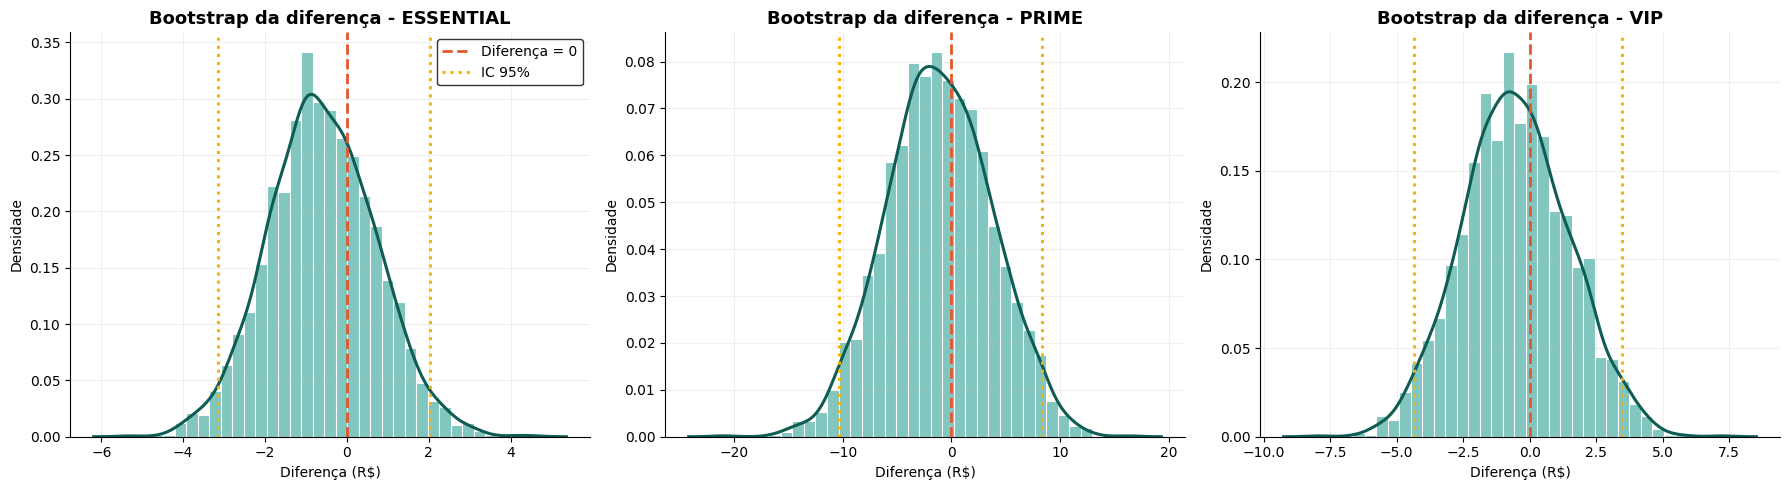

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (histograma)
    "ref_line":  "#E4572E",   # laranja avermelhado (diferença = 0)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (IC 95%)
    "kde_line":  "#0E5C53",   # verde-azulado escuro (curva KDE)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, item in zip(axes, resultado["grupos"]):
    if item["validacao"]["n_rodadas_validas"] == 0:
        ax.set_title(f"{item['grupo']} - sem rodadas válidas")
        ax.axis("off")
        continue

    rodada = item["validacao"]["rodadas"][0]
    boot_diff = rodada["boot_diff"]
    ci_inf = rodada["ci_boot_diff_inf"]
    ci_sup = rodada["ci_boot_diff_sup"]

    sns.histplot(
        boot_diff,
        bins=35,
        stat="density",
        color=PLOT_COLORS["main_line"],
        edgecolor="white",
        alpha=0.55,
        ax=ax
    )

    sns.kdeplot(
        boot_diff,
        color=PLOT_COLORS["kde_line"],
        linewidth=2.2,
        ax=ax
    )

    ax.axvline(0, color=PLOT_COLORS["ref_line"], linestyle="--", linewidth=2, label="Diferença = 0")
    ax.axvline(ci_inf, color=PLOT_COLORS["ideal_pt"], linestyle=":", linewidth=2.2, label="IC 95%")
    ax.axvline(ci_sup, color=PLOT_COLORS["ideal_pt"], linestyle=":", linewidth=2.2)
    ax.set_title(f"Bootstrap da diferença - {item['grupo']}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Diferença (R$)")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.20)

axes[0].legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()

In [ ]:
for item in resultado["grupos"]:
    print(f"\nGrupo: {item['grupo']}")
    display(item["validacao"]["tabela_rodadas"].round(4))


Grupo: ESSENTIAL


,rodada,media_amostra,media_train,media_validation,media_test,diff_obs,ci_boot_diff_inf,ci_boot_diff_sup,p_boot,inclui_zero
0,1,403.2656,403.7510,402.8905,402.1842,-0.6034,-3.1417,2.0269,0.638,True
1,2,405.0540,404.2499,406.4663,406.0538,1.1851,-1.3508,3.8891,0.382,True
2,3,404.5820,404.2738,405.5251,404.5632,0.7130,-1.8396,3.4593,0.612,True
3,4,403.1235,402.8176,404.2304,402.9346,-0.7454,-3.3438,1.9064,0.555,True
4,5,402.8676,402.7423,403.8028,402.3083,-1.0013,-3.5309,1.5773,0.433,True
5,6,404.6619,404.5657,404.9670,404.6457,0.7930,-1.8122,3.2592,0.539,True
6,7,404.4904,404.3478,403.1325,406.2759,0.6214,-2.0048,3.2516,0.668,True
7,8,403.9091,404.9390,402.7641,401.9645,0.0402,-2.4368,2.6431,0.973,True
8,9,403.1658,402.4797,405.1443,403.2454,-0.7031,-3.2444,2.0638,0.571,True
9,10,404.2594,403.9278,403.4474,406.0659,0.3904,-2.1882,2.9205,0.796,True



Grupo: PRIME


,rodada,media_amostra,media_train,media_validation,media_test,diff_obs,ci_boot_diff_inf,ci_boot_diff_sup,p_boot,inclui_zero
0,1,2191.1819,2192.1508,2188.8325,2190.6247,-1.1431,-10.3250,8.3059,0.819,True
1,2,2191.2504,2191.1533,2189.5115,2193.2808,-1.0746,-10.3566,8.7387,0.830,True
2,3,2190.2394,2191.2229,2191.4472,2186.0812,-2.0856,-11.1376,7.3005,0.667,True
3,4,2189.1868,2188.6207,2195.9661,2184.1060,-3.1382,-12.9257,6.5671,0.524,True
4,5,2189.7576,2184.7581,2193.0941,2201.4194,-2.5675,-11.7961,6.7587,0.607,True
5,6,2194.6881,2195.2380,2188.5033,2199.2235,2.3631,-7.0520,11.5789,0.626,True
6,7,2194.2620,2191.8550,2199.9204,2195.8246,1.9370,-7.2250,11.3830,0.669,True
7,8,2195.8887,2196.1527,2201.1352,2189.8499,3.5636,-5.8851,13.4437,0.451,True
8,9,2193.3938,2198.5792,2187.5192,2183.7125,1.0688,-8.3169,10.2069,0.851,True
9,10,2198.4515,2197.7727,2197.5827,2201.3565,6.1264,-3.1295,15.5368,0.206,True



Grupo: VIP


,rodada,media_amostra,media_train,media_validation,media_test,diff_obs,ci_boot_diff_inf,ci_boot_diff_sup,p_boot,inclui_zero
0,1,906.6898,906.3039,907.5724,906.9648,-0.4926,-4.3377,3.4564,0.780,True
1,2,906.5872,905.3705,908.1548,908.6699,-0.5951,-4.5561,3.3686,0.752,True
2,3,907.3504,906.6772,905.6305,911.0897,0.1680,-3.7497,4.1304,0.926,True
3,4,906.8480,907.3331,907.5523,904.6881,-0.3344,-4.3348,3.5360,0.843,True
4,5,906.3428,907.5977,903.6892,905.2318,-0.8395,-4.7675,3.0764,0.690,True
5,6,906.9958,906.6091,905.1839,909.9674,-0.1866,-3.9854,3.6028,0.919,True
6,7,906.3478,906.9727,903.5174,907.3037,-0.8345,-4.6742,3.1436,0.678,True
7,8,905.7473,904.9664,905.3795,908.4581,-1.4350,-5.3472,2.6601,0.479,True
8,9,907.2492,906.2329,909.9706,907.5767,0.0669,-3.8040,4.0936,0.952,True
9,10,907.3552,907.5024,905.7720,908.4970,0.1729,-3.7023,4.0873,0.926,True


O teste de Levene foi usado para verificar, em cada grupo (ESSENTIAL, PRIME e VIP), se as partições TRAIN, VALIDATION e TEST têm variâncias equivalentes na variável TOTAL (R&#36;) nas rodadas válidas da amostragem estratificada.

A leitura é feita grupo a grupo. Um p-valor acima de 0,05 não rejeita a hipótese nula de homogeneidade de variâncias, o que indica que a dispersão das partições é estatisticamente semelhante. Um p-valor abaixo de 0,05 rejeita essa hipótese e aponta diferença de variabilidade entre pelo menos duas partições.

As estatísticas descritivas de cada partição (média, mediana e intervalo interquartil) complementam o teste, ao mostrar como TRAIN, VALIDATION e TEST se comportam dentro de cada segmento. Assim, a análise confirma se a estabilidade da amostragem estratificada também se mantém na dispersão dos dados, o que reforça a consistência da validação por grupos.

#### A1.3.1: Teste de Normalidade

Nesta etapa, verifica-se se a variável TOTAL (R&#36;) tem comportamento compatível com a distribuição normal em cada um dos grupos ESSENTIAL, PRIME e VIP. Para isso, aplica-se o teste de Shapiro-Wilk a amostras controladas de cada grupo, com apoio de histogramas e QQ-plots.

A análise é feita no nível estratificado porque a base completa mistura grupos com distribuições bem diferentes, o que dificultaria o diagnóstico. Por isso, a normalidade é avaliada separadamente em cada segmento, em linha com a validação amostral realizada na Atividade A1.3.

In [ ]:
def teste_shapiro_amostra(serie, n_amostra=5000, alpha=0.05, random_state=42):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    if len(serie) == 0:
        return np.nan, np.nan, "Sem dados", serie

    n_use = min(n_amostra, len(serie))
    amostra = serie.sample(n=n_use, random_state=random_state) if len(serie) > n_use else serie.copy()

    w, p = shapiro(amostra)
    decisao = "Rejeita normalidade" if p < alpha else "Não rejeita normalidade"

    return float(w), float(p), decisao, amostra


def plot_normalidade_grupo(amostra, grupo):
    amostra = pd.to_numeric(amostra, errors="coerce").dropna()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    q_inf = amostra.quantile(0.005)
    q_sup = amostra.quantile(0.995)
    amostra_plot = amostra.clip(lower=q_inf, upper=q_sup)

    sns.histplot(
        amostra_plot,
        bins=35,
        stat="density",
        color="#9ecae1",
        edgecolor="white",
        alpha=0.60,
        ax=axes[0],
    )
    sns.kdeplot(
        amostra_plot,
        color="#08519c",
        linewidth=2.2,
        ax=axes[0],
    )

    axes[0].set_title(f"{grupo} - Distribuição de TOTAL (R$)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("TOTAL (R$)")
    axes[0].set_ylabel("Densidade")
    axes[0].grid(alpha=0.20)

    stats.probplot(amostra, dist="norm", plot=axes[1])
    axes[1].set_title(f"{grupo} - QQ-plot de TOTAL (R$)", fontsize=13, fontweight="bold")
    axes[1].grid(alpha=0.20)

    plt.tight_layout()
    sns.despine()
    plt.show()


In [ ]:
def AtividadeA1_3_1():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        amostra = pd.to_numeric(item["normalidade"]["amostra"], errors="coerce").dropna()
        tabela_rodadas = item["validacao"]["tabela_rodadas"].copy()

        erro_train = (tabela_rodadas["media_train"] - item["media_populacao"]).abs()
        erro_validation = (tabela_rodadas["media_validation"] - item["media_populacao"]).abs()
        erro_test = (tabela_rodadas["media_test"] - item["media_populacao"]).abs()

        resultados.append({
            "Grupo": grupo,
            "N população": item["N"],
            "n amostra": item["normalidade"]["n_amostra"],
            "Shapiro W": item["normalidade"]["shapiro_stat"],
            "Shapiro p-valor": item["normalidade"]["shapiro_p"],
            "Decisão normalidade": item["normalidade"]["decisao"],
            "Média amostra": float(amostra.mean()),
            "DP amostra": float(amostra.std(ddof=1)),
            "Assimetria": float(amostra.skew()),
            "Curtose": float(amostra.kurtosis()),
            "Erro médio TRAIN": float(erro_train.mean()),
            "Erro médio VALIDATION": float(erro_validation.mean()),
            "Erro médio TEST": float(erro_test.mean()),
            "Amostra": amostra,
            "Erros": pd.DataFrame({
                "Partição": ["TRAIN", "VALIDATION", "TEST"],
                "Erro médio": [erro_train.mean(), erro_validation.mean(), erro_test.mean()]
            })
        })

    df_resultados = pd.DataFrame(resultados)

    RESULTADOS["A1.3.1"] = {
        "tabela": df_resultados.drop(columns=["Amostra", "Erros"]),
        "amostras": {
            row["Grupo"]: row["Amostra"]
            for _, row in df_resultados.iterrows()
        },
        "erros_medios": {
            row["Grupo"]: row["Erros"]
            for _, row in df_resultados.iterrows()
        },
    }

    print("Teste de normalidade por grupos concluído.")
    print("Variável analisada: TOTAL (R$)")
    print(f"Grupos analisados: {len(df_resultados)}")


In [ ]:
AtividadeA1_3_1()

resultado = RESULTADOS["A1.3.1"]

tabela_normalidade = resultado["tabela"].copy()
tabela_normalidade[[
    "Shapiro W",
    "Shapiro p-valor",
    "Média amostra",
    "DP amostra",
    "Assimetria",
    "Curtose",
    "Erro médio TRAIN",
    "Erro médio VALIDATION",
    "Erro médio TEST"
]] = tabela_normalidade[[
    "Shapiro W",
    "Shapiro p-valor",
    "Média amostra",
    "DP amostra",
    "Assimetria",
    "Curtose",
    "Erro médio TRAIN",
    "Erro médio VALIDATION",
    "Erro médio TEST"
]].round(4)

display(tabela_normalidade)


Teste de normalidade por grupos concluído.
Variável analisada: TOTAL (R$)
Grupos analisados: 3


,Grupo,N população,n amostra,Shapiro W,Shapiro p-valor,Decisão normalidade,Média amostra,DP amostra,Assimetria,Curtose,Erro médio TRAIN,Erro médio VALIDATION,Erro médio TEST
0,ESSENTIAL,683501,5000,0.5631,0.0,Rejeita normalidade,409.0829,311.8388,4.9840,33.9362,1.0594,1.2982,1.3274
1,PRIME,183226,5000,0.9802,0.0,Rejeita normalidade,2209.1934,1047.3862,0.1769,-0.8457,3.5593,4.6545,4.4387
2,VIP,253273,5000,0.8992,0.0,Rejeita normalidade,903.7862,451.3063,1.4875,4.8874,1.0898,1.6948,1.8791


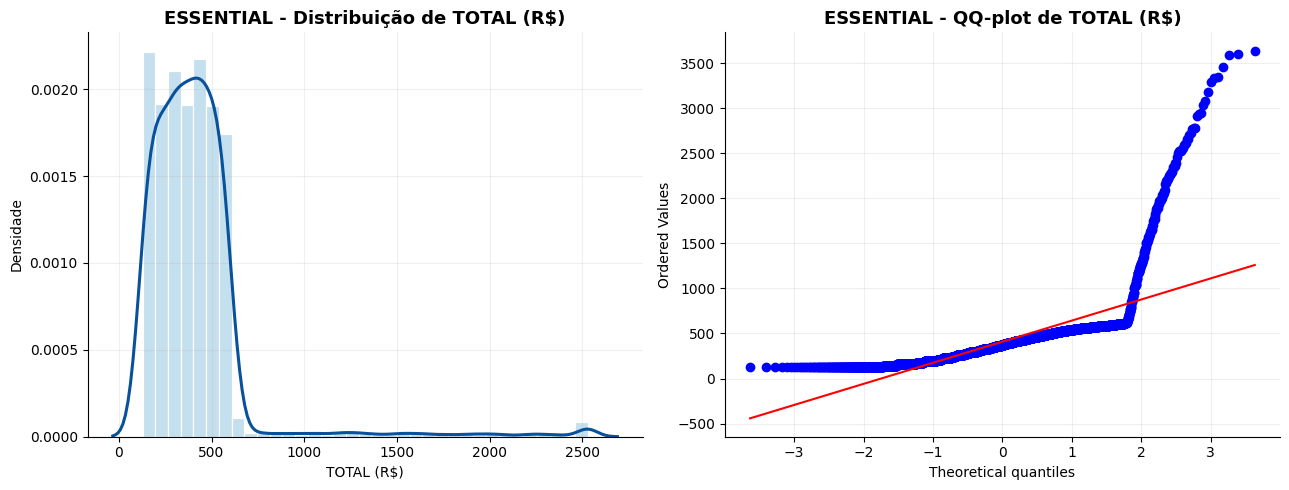

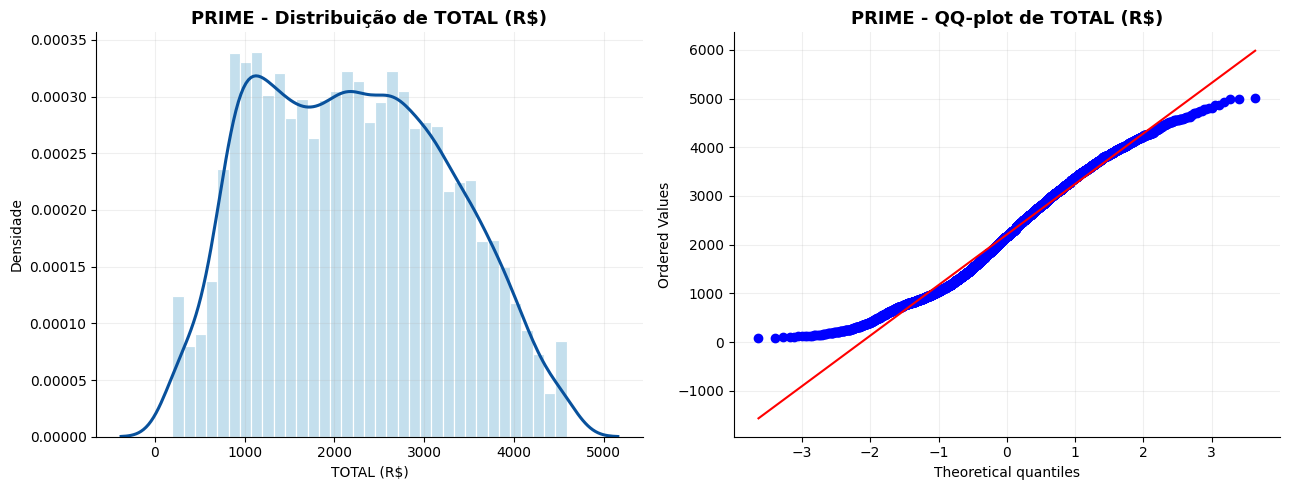

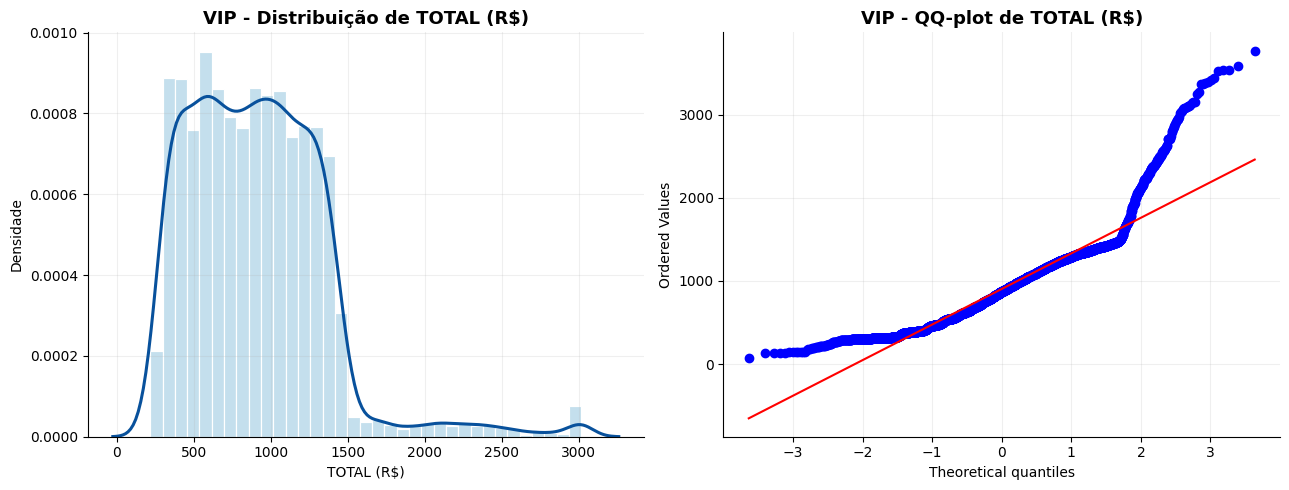

In [ ]:
for grupo, amostra in resultado["amostras"].items():
    plot_normalidade_grupo(amostra, grupo)



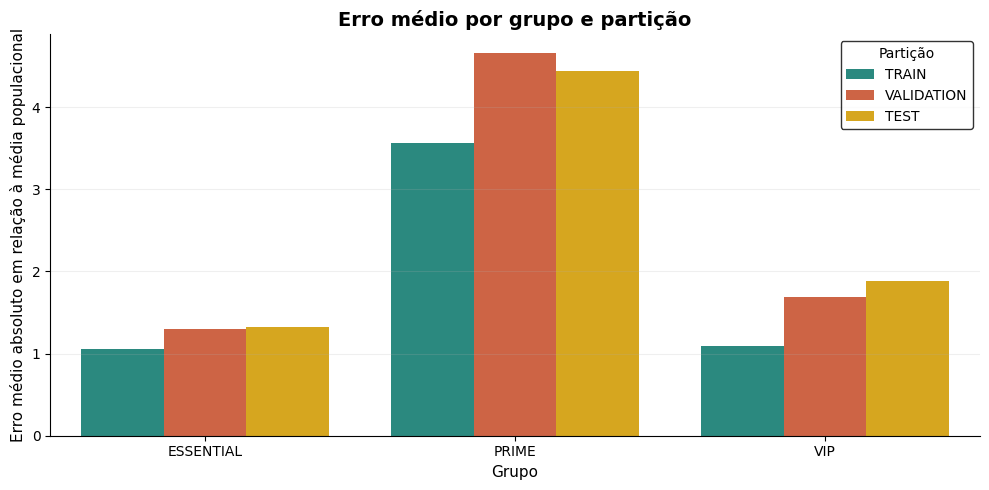

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado
    "ref_line":  "#E4572E",   # laranja avermelhado
    "ideal_pt":  "#F4B400",   # amarelo âmbar
}

dados_erro = []

for grupo, df_erro in resultado["erros_medios"].items():
    temp = df_erro.copy()
    temp["Grupo"] = grupo
    dados_erro.append(temp)

dados_erro = pd.concat(dados_erro, ignore_index=True)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=dados_erro,
    x="Grupo",
    y="Erro médio",
    hue="Partição",
    palette=[PLOT_COLORS["main_line"], PLOT_COLORS["ref_line"], PLOT_COLORS["ideal_pt"]]
)

plt.title("Erro médio por grupo e partição", fontsize=14, fontweight="bold")
plt.xlabel("Grupo", fontsize=11)
plt.ylabel("Erro médio absoluto em relação à média populacional", fontsize=11)
plt.grid(axis="y", alpha=0.20)
plt.legend(title="Partição", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()

In [ ]:
auditoria_discretizacao = []

for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    df_grupo = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    df_grupo = df_grupo[df_grupo["TIPO DA CONTA"] == grupo]

    for var in ["RENDA BRUTO (R$)", "TOTAL (R$)"]:
        serie = pd.to_numeric(df_grupo[var], errors="coerce").dropna()

        freq = serie.value_counts()
        perc_moda = float((freq.iloc[0] / len(serie)) * 100)
        ratio_unicos = float((serie.nunique() / len(serie)) * 100)

        auditoria_discretizacao.append({
            "Grupo": grupo,
            "Variável": var,
            "N": int(len(serie)),
            "Valores únicos": int(serie.nunique()),
            "% únicos": ratio_unicos,
            "Moda": float(freq.index[0]),
            "% moda": perc_moda,
            "Top 5 %": float((freq.iloc[:5].sum() / len(serie)) * 100)
        })

auditoria_discretizacao = pd.DataFrame(auditoria_discretizacao)
display(auditoria_discretizacao.round(4))


,Grupo,Variável,N,Valores únicos,% únicos,Moda,% moda,Top 5 %
0,ESSENTIAL,RENDA BRUTO (R$),683501,75707,11.0764,3239.27,0.0082,0.0379
1,ESSENTIAL,TOTAL (R$),683501,71459,10.4548,132.81,0.0101,0.0493
2,PRIME,RENDA BRUTO (R$),183226,163609,89.2936,17334.83,0.0038,0.0175
3,PRIME,TOTAL (R$),183226,145418,79.3654,791.32,0.0038,0.0169
4,VIP,RENDA BRUTO (R$),253273,141141,55.7268,7739.83,0.0043,0.0205
5,VIP,TOTAL (R$),253273,112470,44.4066,313.16,0.0055,0.0265


In [ ]:
percentis_normalidade = []

for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    df_grupo = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    df_grupo = df_grupo[df_grupo["TIPO DA CONTA"] == grupo]

    for var in ["RENDA BRUTO (R$)", "TOTAL (R$)"]:
        serie = pd.to_numeric(df_grupo[var], errors="coerce").dropna()

        percentis_normalidade.append({
            "Grupo": grupo,
            "Variável": var,
            "P1": float(serie.quantile(0.01)),
            "P5": float(serie.quantile(0.05)),
            "P25": float(serie.quantile(0.25)),
            "P50": float(serie.quantile(0.50)),
            "P75": float(serie.quantile(0.75)),
            "P95": float(serie.quantile(0.95)),
            "P99": float(serie.quantile(0.99)),
        })

percentis_normalidade = pd.DataFrame(percentis_normalidade)
display(percentis_normalidade.round(2))


,Grupo,Variável,P1,P5,P25,P50,P75,P95,P99
0,ESSENTIAL,RENDA BRUTO (R$),3047.00,3113.10,3197.49,3256.07,3317.24,3462.78,17165.86
1,ESSENTIAL,TOTAL (R$),128.60,134.70,237.65,367.45,494.90,599.32,1952.05
2,PRIME,RENDA BRUTO (R$),2949.32,7179.14,18749.63,21066.16,23024.47,25612.93,27349.16
3,PRIME,TOTAL (R$),257.26,649.91,1313.85,2130.85,3017.84,3948.15,4427.23
4,VIP,RENDA BRUTO (R$),3274.93,7146.19,7555.21,7770.99,8002.71,13821.61,19718.64
5,VIP,TOTAL (R$),286.50,316.66,559.82,869.24,1176.74,1469.09,2681.15


Os resultados da A1.3.1 rejeitaram a hipótese de normalidade da variável `TOTAL (R$)` nos grupos ESSENTIAL, PRIME e VIP, pois os p-valores do teste de Shapiro-Wilk ficaram abaixo de 0,05 nos três casos (W de 0,5631 em ESSENTIAL, 0,8992 em VIP e 0,9802 em PRIME). Os histogramas e os QQ-plots confirmaram o diagnóstico, com desvios claros em relação ao comportamento esperado sob normalidade.

Em ESSENTIAL, a distribuição apresentou assimetria positiva acentuada (4,9840) e curtose elevada (33,9362), o que indica forte concentração em valores baixos e uma cauda superior longa. Em VIP, o comportamento também foi assimétrico à direita, com assimetria de 1,4875 e curtose de 4,8874, mostrando concentração central acompanhada de valores extremos superiores. PRIME foi o grupo mais próximo de um formato regular, com assimetria baixa (0,1769) e curtose negativa (-0,8457), embora sem aderência à normalidade segundo o teste formal.

A análise complementar mostrou que essa não normalidade não decorre de travamento artificial dos valores monetários: `TOTAL (R$)` tem 71.459 valores únicos em ESSENTIAL, 145.418 em PRIME e 112.470 em VIP, e a moda representa no máximo 0,0101% dos registros. Os percentis reforçaram a presença de caudas superiores relevantes em ESSENTIAL e VIP: em ESSENTIAL, a mediana é de 367,45 e o percentil 99 chega a 1.952,05, e em VIP, a mediana é de 869,24 e o percentil 99 chega a 2.681,15.

O gráfico de erro médio por grupo e partição mostrou que as amostras validadas ficaram próximas da média populacional de cada segmento. ESSENTIAL teve os menores erros médios absolutos, entre 1,0594 (TRAIN) e 1,3274 (TEST). VIP teve erros intermediários, entre 1,0898 e 1,8791. PRIME concentrou os maiores desvios, sobretudo na partição VALIDATION (4,6545), indicando maior variabilidade interna mesmo após o critério de aceitação das amostras. Em todos os grupos, o erro ficou bem abaixo de 1% da média populacional.

Conclui-se então que a variável `TOTAL (R$)` não segue distribuição normal mesmo no nível estratificado, mas a validação por grupos produziu partições com erro médio controlado em relação à média populacional. Assim, a estratificação melhora a consistência da amostragem, ainda que não elimine a assimetria e as caudas longas características da variável.

#### A1.3.2: Teste de Independência

Nesta etapa, verifica-se, em cada grupo (`ESSENTIAL`, `PRIME` e `VIP`), se o fato de uma partição (`TRAIN`, `VALIDATION` ou `TEST`) ficar dentro do intervalo de confiança depende de qual partição se trata. Para isso, aplica-se o teste Qui-Quadrado de independência, com apoio do tamanho de efeito, das frequências esperadas e dos resíduos padronizados.

A finalidade é identificar se alguma partição se comporta de modo sistematicamente diferente das outras na validação das reamostragens, o que seria um sinal de instabilidade do procedimento de amostragem dentro dos grupos.

In [ ]:
def interpretar_cramers_v(v):
    if np.isnan(v):
        return "N/A"
    if v < 0.05:
        return "Efeito desprezível"
    if v < 0.10:
        return "Efeito fraco"
    if v < 0.30:
        return "Efeito moderado"
    return "Efeito forte"


def preparar_tabela_particoes(tentativas_log):
    df = tentativas_log.copy()

    df_long = df.melt(
        id_vars=["tentativa", "aceita"],
        value_vars=["status_train", "status_validation", "status_test"],
        var_name="Partição",
        value_name="Status IC"
    )

    mapa_particao = {
        "status_train": "TRAIN",
        "status_validation": "VALIDATION",
        "status_test": "TEST"
    }

    df_long["Partição"] = df_long["Partição"].map(mapa_particao)

    contingencia = pd.crosstab(df_long["Partição"], df_long["Status IC"])
    return df_long, contingencia

In [ ]:
from scipy.stats import chi2_contingency

def AtividadeA1_3_2():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        tentativas_log = item["validacao"]["tentativas_log"].copy()

        df_long, cont = preparar_tabela_particoes(tentativas_log)
        n_validos = int(cont.values.sum())

        chi2, p_val, dof, expected = chi2_contingency(cont.values, correction=False)
        decisao = "Rejeita H0" if p_val < 0.05 else "Não rejeita H0"

        r, c = cont.shape
        k = min(r - 1, c - 1)
        cramers_v = np.sqrt((chi2 / n_validos) / k) if (k > 0 and n_validos > 0) else np.nan
        interpretacao_v = interpretar_cramers_v(cramers_v)

        expected_df = pd.DataFrame(expected, index=cont.index, columns=cont.columns)
        qtd_expected_lt5 = int((expected_df < 5).sum().sum())
        total_celulas = int(expected_df.size)
        perc_expected_lt5 = (qtd_expected_lt5 / total_celulas) * 100 if total_celulas > 0 else np.nan

        residuos = (cont - expected_df) / np.sqrt(expected_df)
        residuos = residuos.replace([np.inf, -np.inf], np.nan)

        top_residuos = (
            residuos.abs()
            .stack()
            .sort_values(ascending=False)
            .head(10)
            .reset_index()
        )
        top_residuos.columns = ["Partição", "Status IC", "|Resíduo padronizado|"]

        percentuais = cont.div(cont.sum(axis=1), axis=0) * 100

        resultados.append({
            "Grupo": grupo,
            "n_validos": n_validos,
            "chi2": float(chi2),
            "p_value": float(p_val),
            "dof": int(dof),
            "decisao": decisao,
            "cramers_v": float(cramers_v) if not np.isnan(cramers_v) else None,
            "interpretacao_cramers_v": interpretacao_v,
            "qtd_expected_lt5": int(qtd_expected_lt5),
            "perc_expected_lt5": float(perc_expected_lt5) if np.isfinite(perc_expected_lt5) else None,
            "contingencia": cont,
            "esperadas": expected_df,
            "residuos_padronizados": residuos,
            "top_residuos": top_residuos,
            "percentuais": percentuais,
        })

    RESULTADOS["A1.3.2"] = {
        "resultados_por_grupo": resultados
    }

    print("Teste de independência por grupos concluído.")
    print(f"Grupos analisados: {len(resultados)}")

In [ ]:
AtividadeA1_3_2()

resultado = RESULTADOS["A1.3.2"]

Teste de independência por grupos concluído.
Grupos analisados: 3


In [ ]:
resumo_independencia = pd.DataFrame([
    {
        "Grupo": item["Grupo"],
        "N válidos": item["n_validos"],
        "Qui-quadrado": item["chi2"],
        "gl": item["dof"],
        "p-valor": item["p_value"],
        "Decisão": item["decisao"],
        "Cramér's V": item["cramers_v"],
        "Interpretação": item["interpretacao_cramers_v"],
        "% esperado < 5": item["perc_expected_lt5"],
    }
    for item in resultado["resultados_por_grupo"]
])

resumo_independencia[["Qui-quadrado", "p-valor", "Cramér's V", "% esperado < 5"]] = (
    resumo_independencia[["Qui-quadrado", "p-valor", "Cramér's V", "% esperado < 5"]].round(4)
)

display(resumo_independencia)

,Grupo,N válidos,Qui-quadrado,gl,p-valor,Decisão,Cramér's V,Interpretação,% esperado < 5
0,ESSENTIAL,153,15.6923,2,0.0004,Rejeita H0,0.3203,Efeito forte,0.0
1,PRIME,105,9.4382,2,0.0089,Rejeita H0,0.2998,Efeito moderado,0.0
2,VIP,201,19.1200,2,0.0001,Rejeita H0,0.3084,Efeito forte,0.0


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']}")
    display(item["contingencia"])
    display(item["top_residuos"])


Grupo: ESSENTIAL


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,32,19
TRAIN,48,3
VALIDATION,34,17


,Partição,Status IC,|Resíduo padronizado|
0,TRAIN,Fora do IC,2.773501
1,TEST,Fora do IC,1.664101
2,TRAIN,Dentro do IC,1.622214
3,VALIDATION,Fora do IC,1.109400
4,TEST,Dentro do IC,0.973329
5,VALIDATION,Dentro do IC,0.648886



Grupo: PRIME


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,27,8
TRAIN,35,0
VALIDATION,27,8


,Partição,Status IC,|Resíduo padronizado|
0,TRAIN,Fora do IC,2.309401
1,TEST,Fora do IC,1.154701
2,VALIDATION,Fora do IC,1.154701
3,TRAIN,Dentro do IC,0.979184
4,TEST,Dentro do IC,0.489592
5,VALIDATION,Dentro do IC,0.489592



Grupo: VIP


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,39,28
TRAIN,57,10
VALIDATION,34,33


,Partição,Status IC,|Resíduo padronizado|
0,TRAIN,Fora do IC,2.809274
1,TRAIN,Dentro do IC,2.076116
2,VALIDATION,Fora do IC,1.918528
3,VALIDATION,Dentro do IC,1.417835
4,TEST,Fora do IC,0.890745
5,TEST,Dentro do IC,0.658281


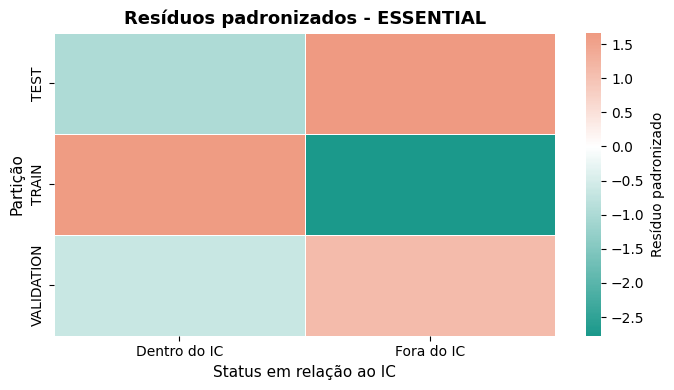

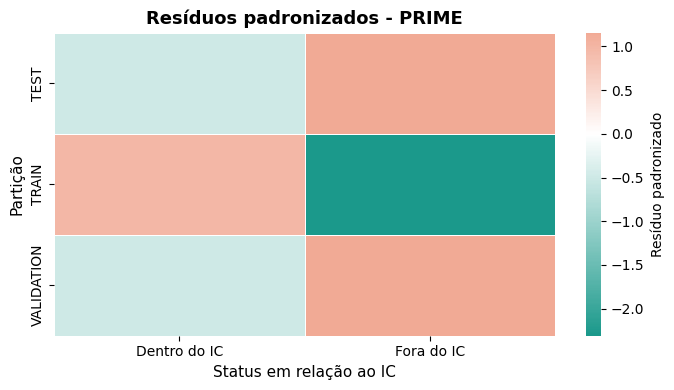

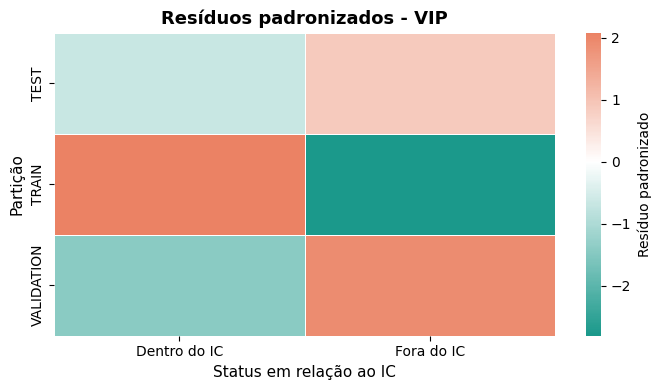

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (resíduos negativos)
    "ref_line":  "#E4572E",   # laranja avermelhado (resíduos positivos)
}

cmap_residuos = LinearSegmentedColormap.from_list(
    "residuos_paleta",
    [PLOT_COLORS["main_line"], "#FFFFFF", PLOT_COLORS["ref_line"]]
)

for item in resultado["resultados_por_grupo"]:
    plt.figure(figsize=(7, 4))

    sns.heatmap(
        item["residuos_padronizados"],
        cmap=cmap_residuos,
        center=0,
        linewidths=0.6,
        linecolor="white",
        cbar_kws={"label": "Resíduo padronizado"},
    )

    plt.title(
        f"Resíduos padronizados - {item['Grupo']}",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Status em relação ao IC", fontsize=11)
    plt.ylabel("Partição", fontsize=11)

    plt.tight_layout()
    sns.despine(left=True, bottom=True)
    plt.show()


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']} - percentuais por partição")
    display(item["percentuais"].round(2))



Grupo: ESSENTIAL - percentuais por partição


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,62.75,37.25
TRAIN,94.12,5.88
VALIDATION,66.67,33.33



Grupo: PRIME - percentuais por partição


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,77.14,22.86
TRAIN,100.00,0.00
VALIDATION,77.14,22.86



Grupo: VIP - percentuais por partição


Status IC,Dentro do IC,Fora do IC
Partição,,
TEST,58.21,41.79
TRAIN,85.07,14.93
VALIDATION,50.75,49.25


O teste Qui-Quadrado mostrou associação estatisticamente significativa entre a partição (TRAIN, VALIDATION ou TEST) e o status em relação ao intervalo de confiança nos três grupos, com p = 0,0004 em ESSENTIAL, p = 0,0089 em PRIME e p = 0,0001 em VIP. Nenhuma frequência esperada ficou abaixo de 5, o que valida o uso do teste, e a hipótese nula de independência foi rejeitada em todos os casos.

O Cramér's V indicou efeito forte em ESSENTIAL (0,3203) e em VIP (0,3084) e efeito moderado em PRIME (0,2998, muito próximo do limite de 0,30). Portanto, as partições não se comportaram de forma equivalente: a chance de ficar dentro ou fora do intervalo de confiança mudou conforme a partição.

As tabelas de contingência e os resíduos padronizados mostram que TRAIN foi a partição mais estável. Em ESSENTIAL, TRAIN ficou dentro do intervalo em 94,12% das tentativas, contra 62,75% em TEST e 66,67% em VALIDATION. Em PRIME, os percentuais foram 100%, 77,14% e 77,14%, e em VIP, 85,07%, 58,21% e 50,75%, respectivamente. Os maiores resíduos padronizados em módulo (2,77 em ESSENTIAL, 2,31 em PRIME e 2,81 em VIP) correspondem a TRAIN fora do intervalo, que ocorreu menos vezes que o esperado. Em VIP, VALIDATION teve o pior desempenho, com cerca de metade das tentativas dentro do intervalo. Uma explicação possível é o tamanho das partições: TRAIN reúne 60% da amostra e as outras duas, 20% cada, e por isso a média de TRAIN tende a ser mais estável.

Conclui-se que, em cada grupo, a permanência dentro do intervalo de confiança depende da partição considerada. Embora a estratégia estratificada tenha gerado as rodadas válidas, as partições não têm o mesmo nível de estabilidade, com vantagem sistemática de TRAIN sobre TEST e VALIDATION.

#### A1.3.3: Teste de Distribuição

Nesta etapa, verifica-se, em cada grupo (`ESSENTIAL`, `PRIME` e `VIP`), se as partições `TRAIN`, `VALIDATION` e `TEST` possuem variâncias semelhantes em relação à variável `TOTAL (R$)`. Para essa análise, é aplicado o teste de Levene, utilizando a mediana como medida central, juntamente com estatísticas descritivas e gráficos que permitem observar a distribuição das médias entre as diferentes partições.

O propósito é identificar se a dispersão dos dados entre as partições é estatisticamente equivalente dentro de cada segmento, ajudando a avaliar a consistência e a estabilidade do processo de amostragem estratificada.


In [ ]:
def calcular_iqr(serie):
    return float(serie.quantile(0.75) - serie.quantile(0.25))


def preparar_dados_levene(dados, coluna_valor, coluna_grupo):
    df = dados[[coluna_valor, coluna_grupo]].copy()

    df = df.dropna(subset=[coluna_valor, coluna_grupo])
    df[coluna_grupo] = df[coluna_grupo].astype(str).str.strip()
    df = df[df[coluna_grupo] != ""]

    df[coluna_valor] = pd.to_numeric(df[coluna_valor], errors="coerce")
    df = df.dropna(subset=[coluna_valor])
    df = df[df[coluna_valor] >= 0]

    return df

In [ ]:
from scipy.stats import levene

def AtividadeA1_3_3():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        df = item["validacao"]["tabela_rodadas"].copy()

        train = df["media_train"].values
        validation = df["media_validation"].values
        test = df["media_test"].values

        estatistica, p_valor = levene(train, validation, test, center="median")
        decisao = "Rejeita H0" if p_valor < 0.05 else "Não rejeita H0"

        resumo = pd.DataFrame({
            "Partição": ["TRAIN", "VALIDATION", "TEST"],
            "n": [len(train), len(validation), len(test)],
            "media": [np.mean(train), np.mean(validation), np.mean(test)],
            "dp": [np.std(train, ddof=1), np.std(validation, ddof=1), np.std(test, ddof=1)],
            "mediana": [np.median(train), np.median(validation), np.median(test)],
            "q1": [np.quantile(train, 0.25), np.quantile(validation, 0.25), np.quantile(test, 0.25)],
            "q3": [np.quantile(train, 0.75), np.quantile(validation, 0.75), np.quantile(test, 0.75)],
        })
        resumo["iqr"] = resumo["q3"] - resumo["q1"]

        resultados.append({
            "Grupo": grupo,
            "Estatística de Levene": float(estatistica),
            "p-valor": float(p_valor),
            "Decisão": decisao,
            "Resumo": resumo,
            "Dados": df,
        })

    RESULTADOS["A1.3.3"] = {
        "resultados_por_grupo": resultados
    }

    print("Teste de distribuição por grupos concluído.")
    print(f"Grupos analisados: {len(resultados)}")


In [ ]:
AtividadeA1_3_3()
resultado = RESULTADOS["A1.3.3"]

Teste de distribuição por grupos concluído.
Grupos analisados: 3


In [ ]:
resumo_levene = pd.DataFrame([
    {
        "Grupo": item["Grupo"],
        "Estatística de Levene": item["Estatística de Levene"],
        "p-valor": item["p-valor"],
        "Decisão": item["Decisão"],
    }
    for item in resultado["resultados_por_grupo"]
])

display(resumo_levene.round(4))

,Grupo,Estatística de Levene,p-valor,Decisão
0,ESSENTIAL,0.6668,0.5173,Não rejeita H0
1,PRIME,0.8656,0.4262,Não rejeita H0
2,VIP,3.0489,0.0552,Não rejeita H0


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']}")
    display(item["Resumo"].round(4))



Grupo: ESSENTIAL


,Partição,n,media,dp,mediana,q1,q3,iqr
0,TRAIN,20,403.8481,1.2827,404.0889,402.7987,404.6590,1.8603
1,VALIDATION,20,403.9516,1.4929,404.0166,402.7293,405.2006,2.4713
2,TEST,20,403.8345,1.5045,403.3695,402.6018,404.8014,2.1996



Grupo: PRIME


,Partição,n,media,dp,mediana,q1,q3,iqr
0,TRAIN,20,2191.8082,4.4218,2191.5389,2188.5977,2195.4667,6.8690
1,VALIDATION,20,2193.2680,5.4244,2192.7707,2188.7502,2197.5983,8.8481
2,TEST,20,2191.8490,5.3547,2191.0705,2188.2571,2194.6413,6.3842



Grupo: VIP


,Partição,n,media,dp,mediana,q1,q3,iqr
0,TRAIN,20,906.9667,1.4216,906.8136,906.2610,907.5579,1.2969
1,VALIDATION,20,906.8261,1.9675,906.3992,905.3724,908.2711,2.8987
2,TEST,20,907.5164,2.1229,908.0174,905.2839,909.0793,3.7954


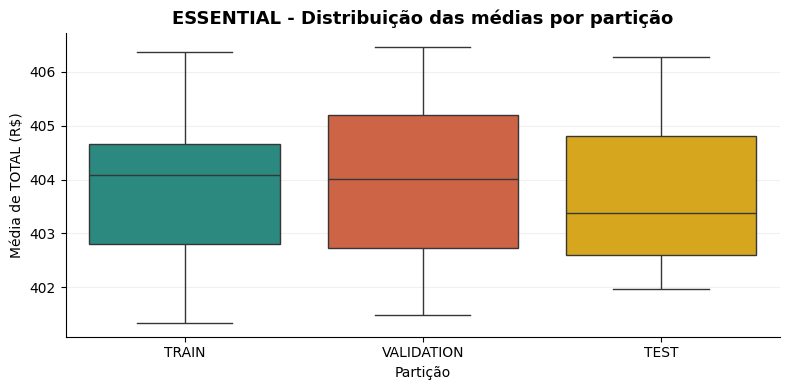

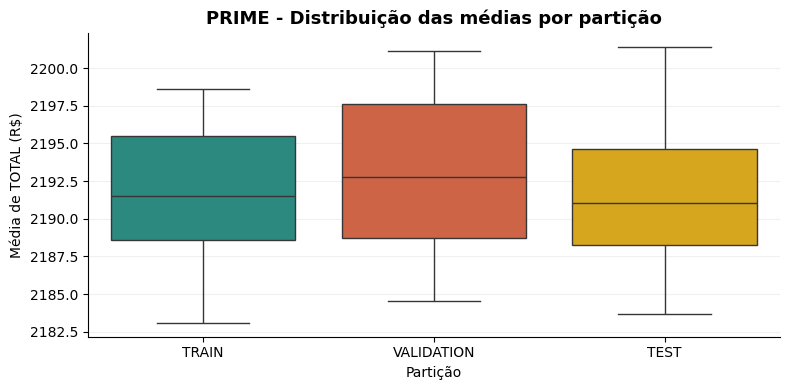

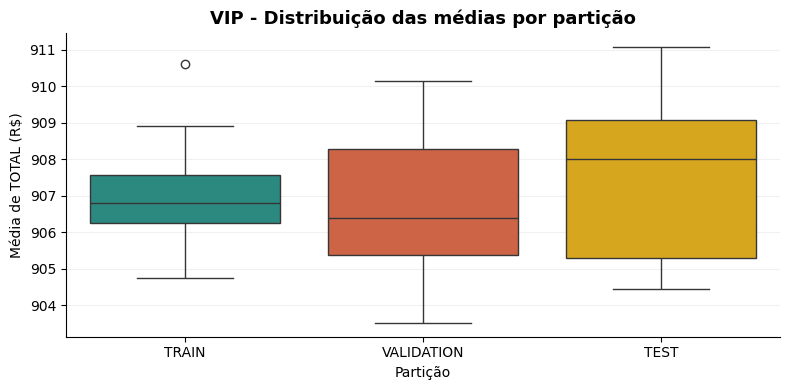

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado
    "ref_line":  "#E4572E",   # laranja avermelhado
    "ideal_pt":  "#F4B400",   # amarelo âmbar
}

PALETA_PARTICOES = {
    "TRAIN":      PLOT_COLORS["main_line"],
    "VALIDATION": PLOT_COLORS["ref_line"],
    "TEST":       PLOT_COLORS["ideal_pt"],
}

for item in resultado["resultados_por_grupo"]:
    df_plot = item["Dados"][["media_train", "media_validation", "media_test"]].copy()
    df_plot.columns = ["TRAIN", "VALIDATION", "TEST"]

    df_long = df_plot.melt(var_name="Partição", value_name="Média")

    plt.figure(figsize=(8, 4))
    sns.boxplot(
        data=df_long,
        x="Partição",
        y="Média",
        hue="Partição",
        palette=PALETA_PARTICOES,
        legend=False
    )
    plt.title(f"{item['Grupo']} - Distribuição das médias por partição", fontsize=13, fontweight="bold")
    plt.xlabel("Partição")
    plt.ylabel("Média de TOTAL (R$)")
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()

O teste de Levene não rejeitou a hipótese nula de homogeneidade de variâncias em nenhum dos grupos: p = 0,5173 em ESSENTIAL, p = 0,4262 em PRIME e p = 0,0552 em VIP. Assim, a dispersão das médias de `TOTAL (R$)` pode ser considerada estatisticamente semelhante entre TRAIN, VALIDATION e TEST nos três segmentos, embora o valor de VIP tenha ficado apenas pouco acima do limite de 0,05.

As estatísticas descritivas por partição reforçam essa leitura. As médias ficaram muito próximas entre as partições e das médias populacionais: 403,83 a 403,95 em ESSENTIAL, 2.191,81 a 2.193,27 em PRIME e 906,83 a 907,52 em VIP. Os boxplots mostram caixas de alturas parecidas em ESSENTIAL e PRIME, e em VIP a caixa de TRAIN é a mais estreita, com um valor extremo isolado acima de 910.

Ainda assim, em todos os grupos TRAIN teve o menor desvio padrão (1,2827 em ESSENTIAL, 4,4218 em PRIME e 1,4216 em VIP) e o menor intervalo interquartil, enquanto VALIDATION e TEST variaram um pouco mais. A diferença é mais visível em VIP, onde o intervalo interquartil de TEST (3,7954) é quase o triplo do de TRAIN (1,2969), o que explica o p-valor próximo de 0,05 nesse grupo. Esse padrão é coerente com o fato de TRAIN ser a maior partição e, portanto, ter médias mais estáveis.

Dessa forma, conclui-se que a dispersão das médias é homogênea entre as partições nos três grupos, o que reforça a consistência da validação estratificada. A única ressalva é VIP, em que VALIDATION e TEST mostram tendência de maior variabilidade que TRAIN, ainda sem significância estatística.

#### A1.3.4: Teste das Médias Amostrais

Nesta etapa, são comparadas, para cada grupo (`ESSENTIAL`, `PRIME` e `VIP`), as médias de `TOTAL (R$)` das partições `TRAIN`, `VALIDATION` e `TEST` considerando as reamostragens que foram consideradas válidas. Como as três partições são analisadas simultaneamente em cada rodada, aplica-se o teste de Friedman. Quando necessário, são realizadas comparações entre pares com ajuste de Holm.

O objetivo é avaliar se as médias das partições aceitas permanecem estatisticamente semelhantes, contribuindo para confirmar a consistência do processo de validação estratificada.


In [ ]:
def corrigir_holm(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    ordem = np.argsort(p_values)
    ajustados = np.empty(m, dtype=float)

    anterior = 0.0
    for rank, idx in enumerate(ordem):
        valor = min(1.0, (m - rank) * p_values[idx])
        valor = max(valor, anterior)
        ajustados[idx] = valor
        anterior = valor

    return ajustados

In [ ]:
from scipy.stats import friedmanchisquare, wilcoxon

def AtividadeA1_3_4():
    if "A1.3" not in RESULTADOS:
        raise ValueError("Execute a Atividade A1.3 antes desta etapa.")

    resultados = []

    for item in RESULTADOS["A1.3"]["grupos"]:
        grupo = item["grupo"]
        df = item["validacao"]["tabela_rodadas"].copy()

        train = df["media_train"].values
        validation = df["media_validation"].values
        test = df["media_test"].values

        estatistica, p_valor = friedmanchisquare(train, validation, test)
        decisao = "Rejeita H0" if p_valor < 0.05 else "Não rejeita H0"

        pares = [
            ("TRAIN", "VALIDATION", train, validation),
            ("TRAIN", "TEST", train, test),
            ("VALIDATION", "TEST", validation, test),
        ]

        resultados_pares = []
        p_brutos = []

        for nome_a, nome_b, a, b in pares:
            try:
                stat_w, p_w = wilcoxon(a, b)
            except ValueError:
                stat_w, p_w = 0.0, 1.0

            resultados_pares.append([nome_a, nome_b, float(stat_w), float(p_w)])
            p_brutos.append(float(p_w))

        posthoc = pd.DataFrame(
            resultados_pares,
            columns=["grupo_1", "grupo_2", "estatistica", "p_value"]
        )
        posthoc["p_holm"] = corrigir_holm(posthoc["p_value"].values)
        posthoc["diferença_significativa"] = posthoc["p_holm"] < 0.05

        resumo = pd.DataFrame({
            "Partição": ["TRAIN", "VALIDATION", "TEST"],
            "media": [np.mean(train), np.mean(validation), np.mean(test)],
            "dp": [np.std(train, ddof=1), np.std(validation, ddof=1), np.std(test, ddof=1)],
            "mediana": [np.median(train), np.median(validation), np.median(test)],
            "q1": [np.quantile(train, 0.25), np.quantile(validation, 0.25), np.quantile(test, 0.25)],
            "q3": [np.quantile(train, 0.75), np.quantile(validation, 0.75), np.quantile(test, 0.75)],
        })
        resumo["iqr"] = resumo["q3"] - resumo["q1"]

        resultados.append({
            "Grupo": grupo,
            "Estatística de Friedman": float(estatistica),
            "p-valor": float(p_valor),
            "Decisão": decisao,
            "Resumo": resumo,
            "Posthoc": posthoc,
        })

    RESULTADOS["A1.3.4"] = {
        "resultados_por_grupo": resultados
    }

    print("Teste das médias amostrais por grupos concluído.")
    print(f"Grupos analisados: {len(resultados)}")


In [ ]:
AtividadeA1_3_4()
resultado = RESULTADOS["A1.3.4"]

Teste das médias amostrais por grupos concluído.
Grupos analisados: 3


In [ ]:
resumo_friedman = pd.DataFrame([
    {
        "Grupo": item["Grupo"],
        "Estatística de Friedman": item["Estatística de Friedman"],
        "p-valor": item["p-valor"],
        "Decisão": item["Decisão"],
    }
    for item in resultado["resultados_por_grupo"]
])

display(resumo_friedman.round(4))

,Grupo,Estatística de Friedman,p-valor,Decisão
0,ESSENTIAL,2.1,0.3499,Não rejeita H0
1,PRIME,0.3,0.8607,Não rejeita H0
2,VIP,1.9,0.3867,Não rejeita H0


In [ ]:
for item in resultado["resultados_por_grupo"]:
    print(f"\nGrupo: {item['Grupo']}")
    display(item["Resumo"].round(4))
    display(item["Posthoc"].sort_values("p_holm").round(4))


Grupo: ESSENTIAL


,Partição,media,dp,mediana,q1,q3,iqr
0,TRAIN,403.8481,1.2827,404.0889,402.7987,404.6590,1.8603
1,VALIDATION,403.9516,1.4929,404.0166,402.7293,405.2006,2.4713
2,TEST,403.8345,1.5045,403.3695,402.6018,404.8014,2.1996


,grupo_1,grupo_2,estatistica,p_value,p_holm,diferença_significativa
0,TRAIN,VALIDATION,95.0,0.7285,1.0,False
1,TRAIN,TEST,99.0,0.8408,1.0,False
2,VALIDATION,TEST,89.0,0.5706,1.0,False



Grupo: PRIME


,Partição,media,dp,mediana,q1,q3,iqr
0,TRAIN,2191.8082,4.4218,2191.5389,2188.5977,2195.4667,6.8690
1,VALIDATION,2193.2680,5.4244,2192.7707,2188.7502,2197.5983,8.8481
2,TEST,2191.8490,5.3547,2191.0705,2188.2571,2194.6413,6.3842


,grupo_1,grupo_2,estatistica,p_value,p_holm,diferença_significativa
0,TRAIN,VALIDATION,76.0,0.2943,0.8828,False
1,TRAIN,TEST,100.0,0.8695,0.8828,False
2,VALIDATION,TEST,80.0,0.3683,0.8828,False



Grupo: VIP


,Partição,media,dp,mediana,q1,q3,iqr
0,TRAIN,906.9667,1.4216,906.8136,906.2610,907.5579,1.2969
1,VALIDATION,906.8261,1.9675,906.3992,905.3724,908.2711,2.8987
2,TEST,907.5164,2.1229,908.0174,905.2839,909.0793,3.7954


,grupo_1,grupo_2,estatistica,p_value,p_holm,diferença_significativa
0,TRAIN,VALIDATION,98.0,0.8124,1.0,False
1,TRAIN,TEST,82.0,0.4091,1.0,False
2,VALIDATION,TEST,80.0,0.3683,1.0,False


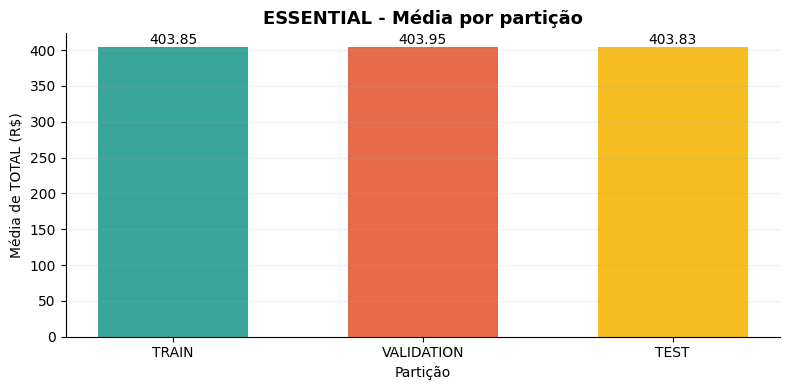

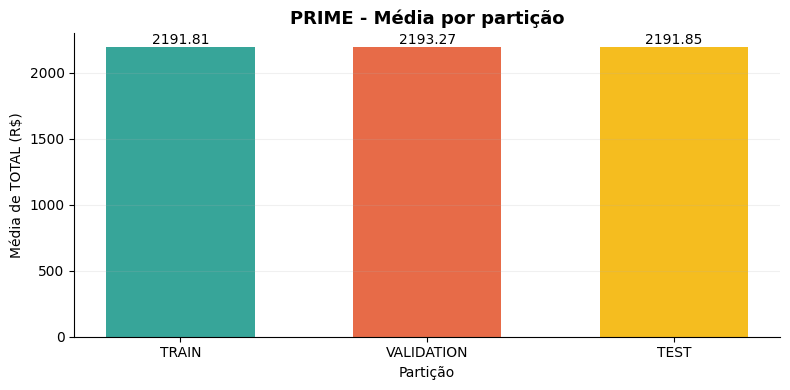

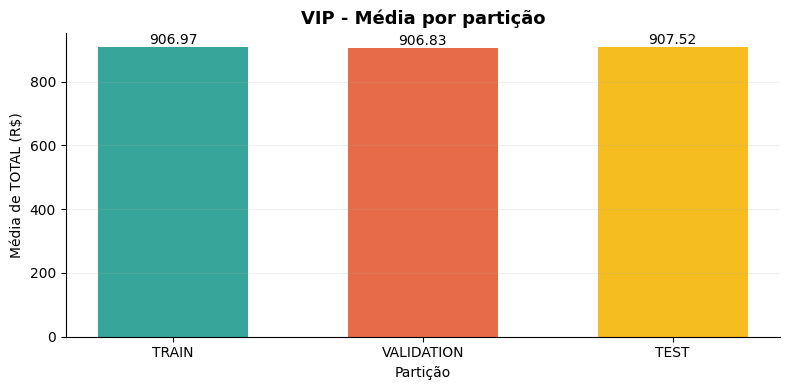

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado
    "ref_line":  "#E4572E",   # laranja avermelhado
    "ideal_pt":  "#F4B400",   # amarelo âmbar
}

PALETA_PARTICOES = {
    "TRAIN":      PLOT_COLORS["main_line"],
    "VALIDATION": PLOT_COLORS["ref_line"],
    "TEST":       PLOT_COLORS["ideal_pt"],
}

for item in resultado["resultados_por_grupo"]:
    resumo_plot = item["Resumo"].copy()

    plt.figure(figsize=(8, 4))
    bars = plt.bar(
        resumo_plot["Partição"],
        resumo_plot["media"],
        color=[PALETA_PARTICOES[p] for p in resumo_plot["Partição"]],
        alpha=0.88,
        width=0.6,
    )

    for bar, valor in zip(bars, resumo_plot["media"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            valor,
            f"{valor:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
        )

    plt.title(f"{item['Grupo']} - Média por partição", fontsize=13, fontweight="bold")
    plt.xlabel("Partição")
    plt.ylabel("Média de TOTAL (R$)")
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()

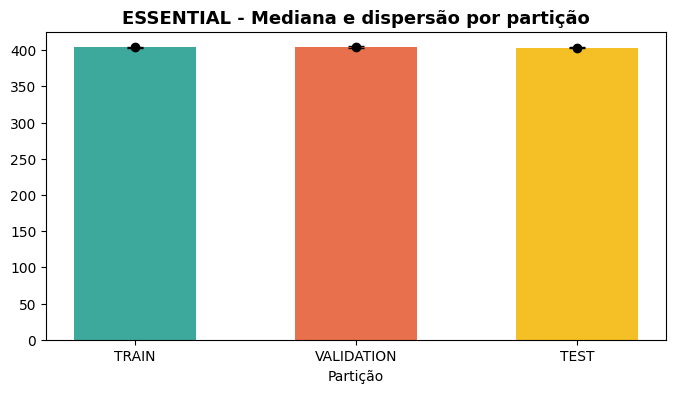

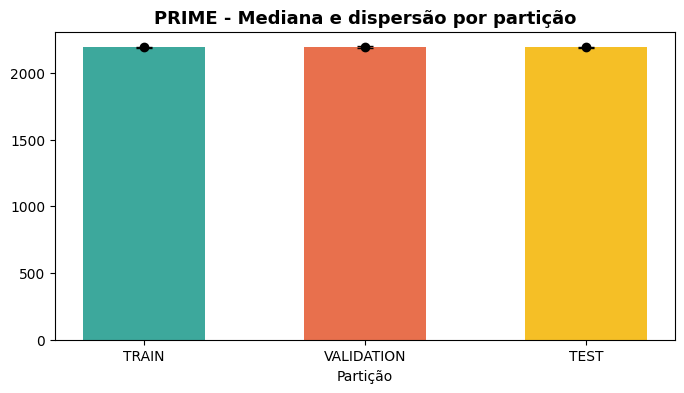

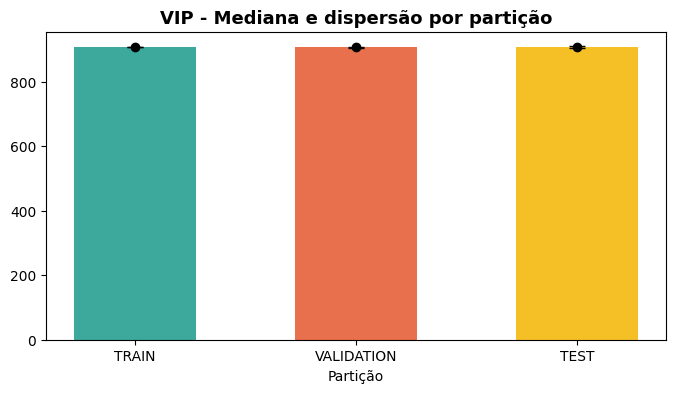

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado
    "ref_line":  "#E4572E",   # laranja avermelhado
    "ideal_pt":  "#F4B400",   # amarelo âmbar
}

PALETA_PARTICOES = {
    "TRAIN":      PLOT_COLORS["main_line"],
    "VALIDATION": PLOT_COLORS["ref_line"],
    "TEST":       PLOT_COLORS["ideal_pt"],
}

for item in resultado["resultados_por_grupo"]:
    resumo_plot = item["Resumo"].copy()

    x = np.arange(len(resumo_plot))

    plt.figure(figsize=(8, 4))
    plt.bar(
        x,
        resumo_plot["mediana"],
        color=[PALETA_PARTICOES[p] for p in resumo_plot["Partição"]],
        alpha=0.85,
        width=0.55,
    )

    plt.errorbar(
        x,
        resumo_plot["mediana"],
        yerr=[resumo_plot["mediana"] - resumo_plot["q1"], resumo_plot["q3"] - resumo_plot["mediana"]],
        fmt="o",
        color="black",
        capsize=6,
        linewidth=1.5,
        label="Intervalo interquartil"
    )

    plt.xticks(x, resumo_plot["Partição"])
    plt.title(f"{item['Grupo']} - Mediana e dispersão por partição", fontsize=13, fontweight="bold")
    plt.xlabel("Partição")

O teste de Friedman não encontrou diferença estatisticamente significativa entre as médias das partições TRAIN, VALIDATION e TEST em nenhum dos grupos: p = 0,3499 em ESSENTIAL, p = 0,8607 em PRIME e p = 0,3867 em VIP. Dessa forma, a hipótese nula de igualdade entre as partições não foi rejeitada nos três casos.

As estatísticas descritivas confirmam esse resultado. Em ESSENTIAL, as médias variaram apenas de 403,83 a 403,95, com medianas entre 403,37 e 404,09. Em PRIME, as médias ficaram entre 2.191,81 e 2.193,27, e em VIP, entre 906,83 e 907,52, valores muito próximos das médias populacionais de cada grupo (403,87, 2.192,33 e 907,18). Os intervalos interquartis foram pequenos em relação ao nível das médias, e os gráficos de média e de mediana por partição mostram barras praticamente do mesmo tamanho.

As comparações par a par com correção de Holm também não apontaram diferença significativa em nenhum par. Em ESSENTIAL e em VIP, todos os p ajustados foram iguais a 1,00, e em PRIME ficaram em 0,8828, sem qualquer evidência de que duas partições difiram entre si.

Conclui-se que, em cada grupo (ESSENTIAL, PRIME e VIP), as partições TRAIN, VALIDATION e TEST têm médias estatisticamente equivalentes para `TOTAL (R$)` nas rodadas aceitas. Isso reforça a consistência da amostragem estratificada validada na A1.3: mesmo que TRAIN tenha ficado mais vezes dentro do intervalo de confiança (A1.3.2), as rodadas aceitas não mostram distorção sistemática de média entre as partições.

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

Nesta etapa, são examinadas as variáveis quantitativas e qualitativas da base com o intuito de entender melhor sua composição dentro de cada estrato, observando padrões, níveis de dispersão e possíveis diferenças entre os grupos `ESSENTIAL`, `PRIME` e `VIP`.

Em vez de analisar os dados de forma geral, o foco está na comparação entre os segmentos, permitindo identificar como as características e comportamentos das variáveis se distribuem em cada grupo. Dessa forma, a análise contribui para a interpretação dos resultados obtidos nos testes estatísticos realizados anteriormente.


###Atividade A2.1: Analisar as variáveis Quantitativas

Nesta etapa, são avaliadas as variáveis quantitativas da base para identificar suas principais características, como medidas de tendência central, nível de dispersão, formato das distribuições e ocorrência de possíveis valores extremos nos grupos `ESSENTIAL`, `PRIME` e `VIP`.

A análise é feita individualmente para cada grupo, evitando que uma avaliação conjunta oculte diferenças importantes entre as distribuições. Dessa forma, é possível obter uma visão mais clara e específica do comportamento das variáveis em cada segmento.


In [ ]:
def calcular_resumo_quantitativo(serie, nome_variavel, grupo):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    if len(serie) == 0:
        return None

    media = float(serie.mean())
    mediana = float(serie.median())
    dp = float(serie.std(ddof=1)) if len(serie) > 1 else 0.0
    minimo = float(serie.min())
    maximo = float(serie.max())

    q1 = float(serie.quantile(0.25))
    q3 = float(serie.quantile(0.75))
    iqr = float(q3 - q1)

    p1 = float(serie.quantile(0.01))
    p5 = float(serie.quantile(0.05))
    p95 = float(serie.quantile(0.95))
    p99 = float(serie.quantile(0.99))

    assimetria = float(serie.skew()) if len(serie) > 2 else np.nan
    curtose = float(serie.kurtosis()) if len(serie) > 3 else np.nan
    cv = float(dp / media) if media != 0 else np.nan

    lim_inf = float(q1 - 1.5 * iqr)
    lim_sup = float(q3 + 1.5 * iqr)
    outliers_qtd = int(((serie < lim_inf) | (serie > lim_sup)).sum())
    outliers_perc = float((outliers_qtd / len(serie)) * 100)

    return {
        "grupo": grupo,
        "variavel": nome_variavel,
        "n": int(len(serie)),
        "media": media,
        "mediana": mediana,
        "dp": dp,
        "min": minimo,
        "max": maximo,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "p1": p1,
        "p5": p5,
        "p95": p95,
        "p99": p99,
        "assimetria": assimetria,
        "curtose": curtose,
        "coef_var": cv,
        "lim_inf_iqr": lim_inf,
        "lim_sup_iqr": lim_sup,
        "outliers_qtd": outliers_qtd,
        "outliers_%": outliers_perc,
    }


In [ ]:
def AtividadeA2_1():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    variaveis = ["RENDA BRUTO (R$)", "TOTAL (R$)"]

    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    resultados = []

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()

        for coluna in variaveis:
            resumo = calcular_resumo_quantitativo(df_grupo[coluna], coluna, grupo)
            if resumo is not None:
                resultados.append(resumo)

    tabela_resumo = pd.DataFrame(resultados)

    RESULTADOS["A2.1"] = {
        "n_registros": int(len(base_ref)),
        "qtd_variaveis": int(len(variaveis)),
        "grupos": grupos_alvo,
        "tabela_resumo": tabela_resumo,
    }

    print("Análise das variáveis quantitativas por grupos concluída.")
    print(f"Grupos analisados: {len(grupos_alvo)}")
    print(f"Variáveis analisadas por grupo: {len(variaveis)}")


In [ ]:
AtividadeA2_1()
resultado = RESULTADOS["A2.1"]
tabela_quant = resultado["tabela_resumo"].copy()

Análise das variáveis quantitativas por grupos concluída.
Grupos analisados: 3
Variáveis analisadas por grupo: 2


In [ ]:
colunas_visuais = [
    "grupo", "variavel", "n", "media", "mediana", "dp", "q1", "q3",
    "iqr", "assimetria", "curtose", "coef_var", "outliers_%"
]

tabela_exibicao = tabela_quant[colunas_visuais].copy()
tabela_exibicao[[
    "media", "mediana", "dp", "q1", "q3", "iqr",
    "assimetria", "curtose", "coef_var", "outliers_%"
]] = tabela_exibicao[[
    "media", "mediana", "dp", "q1", "q3", "iqr",
    "assimetria", "curtose", "coef_var", "outliers_%"
]].round(4)

display(tabela_exibicao)

,grupo,variavel,n,media,mediana,dp,q1,q3,iqr,assimetria,curtose,coef_var,outliers_%
0,ESSENTIAL,RENDA BRUTO (R$),683501,3651.7831,3256.070,2158.2579,3197.4900,3317.2400,119.7500,5.8565,35.0307,0.5910,5.1592
1,ESSENTIAL,TOTAL (R$),683501,403.8689,367.450,299.1983,237.6500,494.9000,257.2500,5.0153,35.6445,0.7408,2.8881
2,PRIME,RENDA BRUTO (R$),183226,19912.5591,21066.165,5115.7511,18749.6350,23024.4675,4274.8325,-1.6039,2.5366,0.2569,9.8026
3,PRIME,TOTAL (R$),183226,2192.3250,2130.845,1051.2856,1313.8525,3017.8400,1703.9875,0.1935,-0.8647,0.4795,0.0000
4,VIP,RENDA BRUTO (R$),253273,8242.1429,7770.990,2405.2742,7555.2100,8002.7100,447.5000,3.1997,12.1947,0.2918,12.0498
5,VIP,TOTAL (R$),253273,907.1823,869.240,455.2692,559.8200,1176.7400,616.9200,1.5483,5.2435,0.5018,2.2746


In [ ]:
for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    print(f"\nGrupo: {grupo}")

    df_grupo = tabela_quant[tabela_quant["grupo"] == grupo].copy()

    maior_cv = df_grupo.sort_values("coef_var", ascending=False).head(3)
    maior_outliers = df_grupo.sort_values("outliers_%", ascending=False).head(3)
    maior_assimetria = df_grupo.reindex(
        df_grupo["assimetria"].abs().sort_values(ascending=False).index
    ).head(3)

    display(maior_cv[["variavel", "coef_var"]].round(4))
    display(maior_outliers[["variavel", "outliers_%"]].round(4))
    display(maior_assimetria[["variavel", "assimetria"]].round(4))


Grupo: ESSENTIAL


,variavel,coef_var
1,TOTAL (R$),0.7408
0,RENDA BRUTO (R$),0.5910


,variavel,outliers_%
0,RENDA BRUTO (R$),5.1592
1,TOTAL (R$),2.8881


,variavel,assimetria
0,RENDA BRUTO (R$),5.8565
1,TOTAL (R$),5.0153



Grupo: PRIME


...

,variavel,assimetria
2,RENDA BRUTO (R$),-1.6039
3,TOTAL (R$),0.1935



Grupo: VIP


,variavel,coef_var
5,TOTAL (R$),0.5018
4,RENDA BRUTO (R$),0.2918


,variavel,outliers_%
4,RENDA BRUTO (R$),12.0498
5,TOTAL (R$),2.2746


,variavel,assimetria
4,RENDA BRUTO (R$),3.1997
5,TOTAL (R$),1.5483


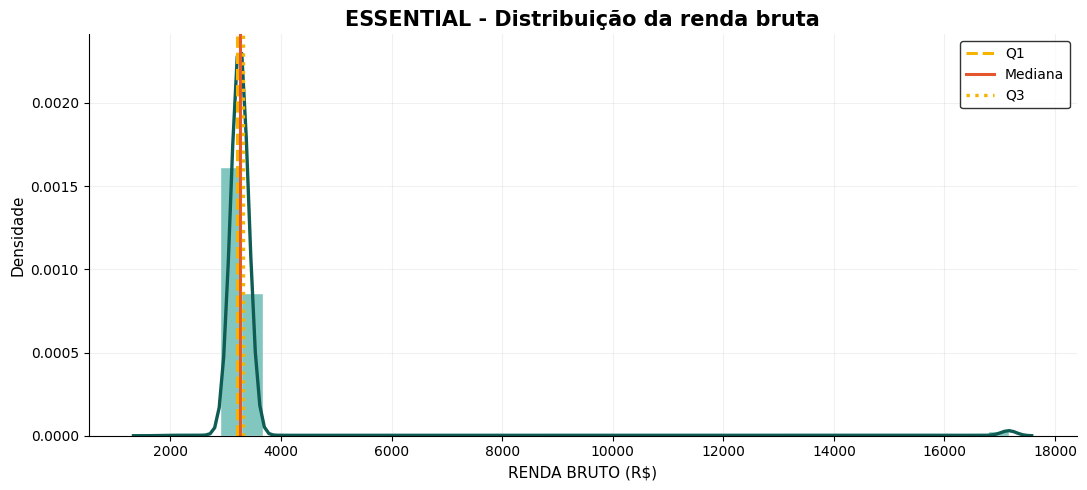

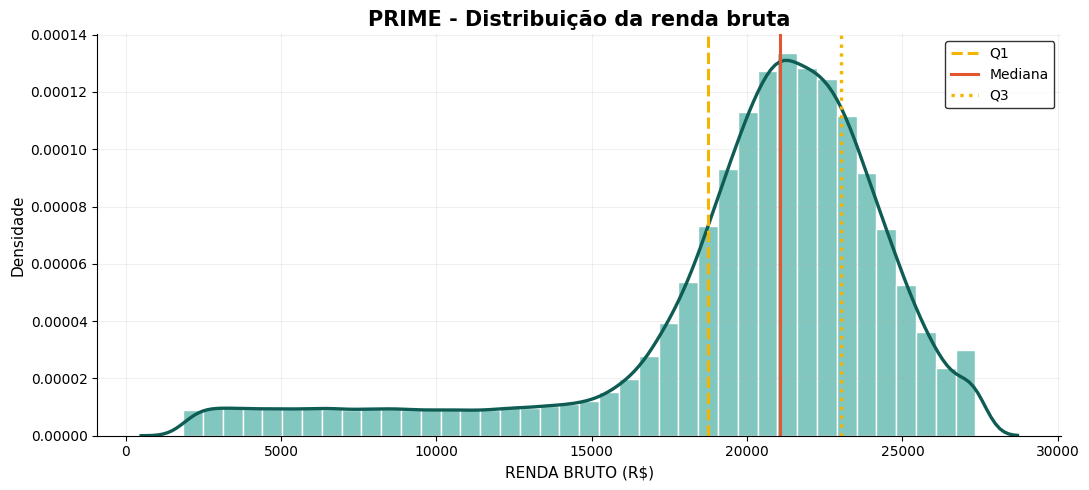

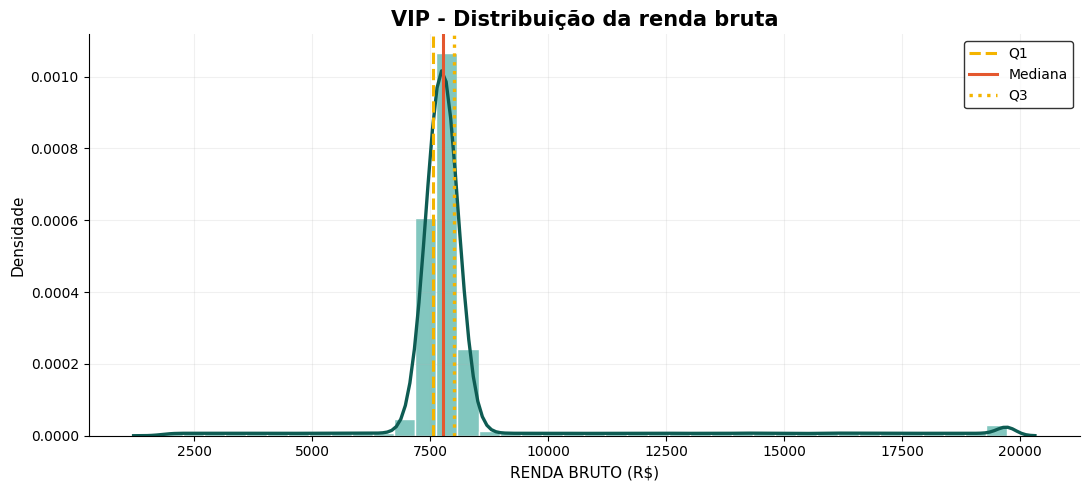

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (histograma)
    "ref_line":  "#E4572E",   # laranja avermelhado (mediana)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (quartis)
    "kde_line":  "#0E5C53",   # verde-azulado escuro (curva KDE)
}

for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    serie = RESULTADOS["A1.2"]["table_limpa"].loc[
        RESULTADOS["A1.2"]["table_limpa"]["TIPO DA CONTA"] == grupo,
        "RENDA BRUTO (R$)"
    ].dropna()

    cap = serie.quantile(0.99)
    serie_plot = serie.clip(upper=cap)

    q1 = serie.quantile(0.25)
    mediana = serie.median()
    q3 = serie.quantile(0.75)

    plt.figure(figsize=(11, 5))

    sns.histplot(
        serie_plot,
        bins=40,
        stat="density",
        color=PLOT_COLORS["main_line"],
        edgecolor="white",
        alpha=0.55,
    )

    sns.kdeplot(
        serie_plot,
        color=PLOT_COLORS["kde_line"],
        linewidth=2.4,
    )

    plt.axvline(q1, color=PLOT_COLORS["ideal_pt"], linestyle="--", linewidth=2.2, label="Q1")
    plt.axvline(mediana, color=PLOT_COLORS["ref_line"], linestyle="-", linewidth=2.2, label="Mediana")
    plt.axvline(q3, color=PLOT_COLORS["ideal_pt"], linestyle=":", linewidth=2.4, label="Q3")

    plt.title(f"{grupo} - Distribuição da renda bruta", fontsize=15, fontweight="bold")
    plt.xlabel("RENDA BRUTO (R$)", fontsize=11)
    plt.ylabel("Densidade", fontsize=11)
    plt.grid(alpha=0.18)
    plt.legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()

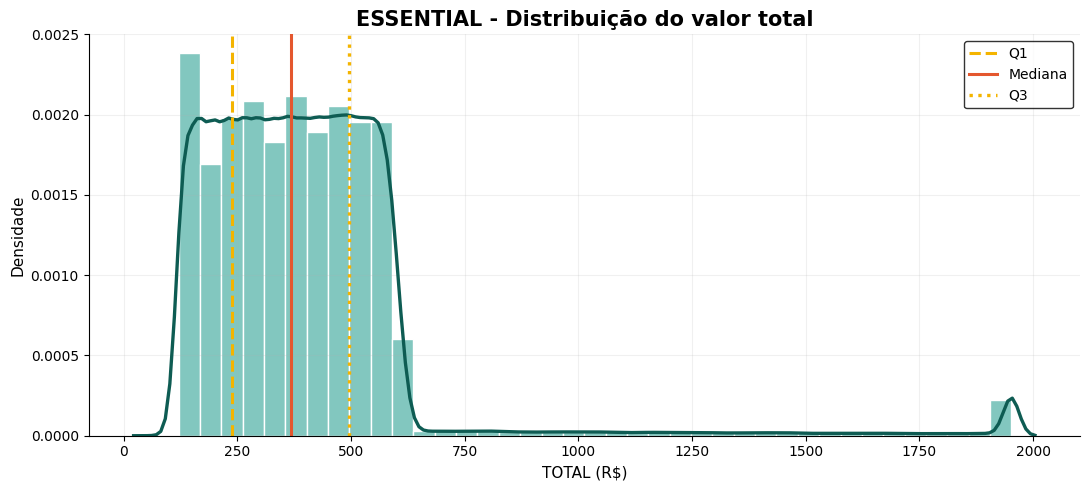

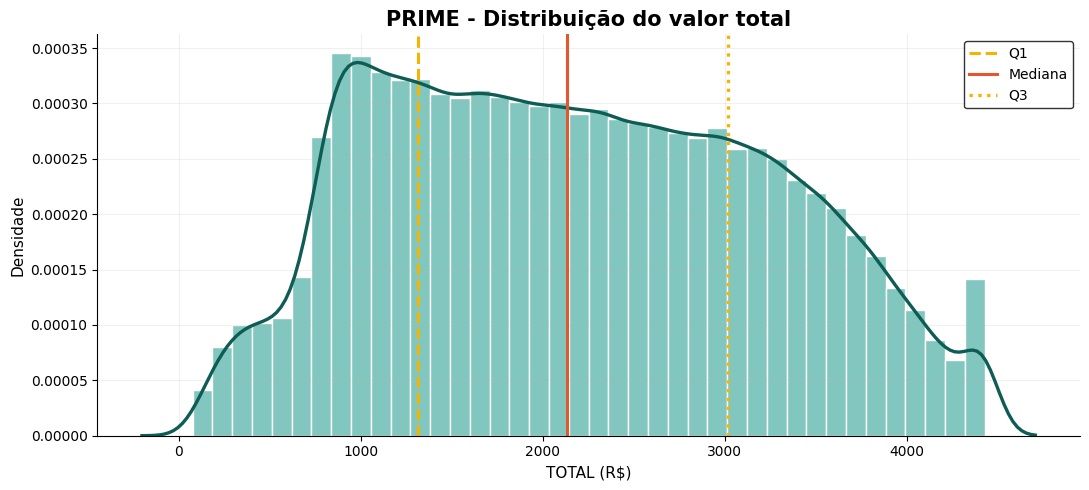

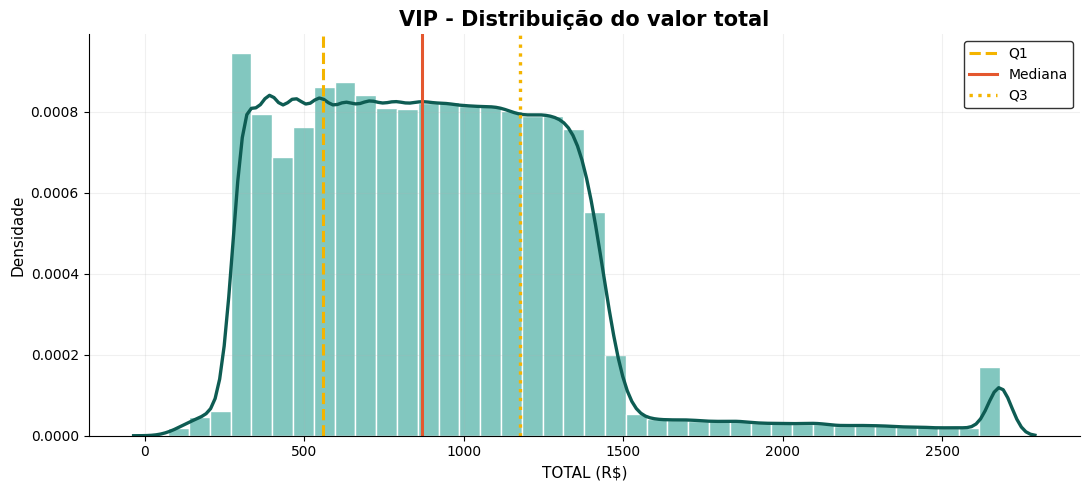

In [ ]:
PLOT_COLORS = {
    "main_line": "#1B998B",   # verde-azulado (histograma)
    "ref_line":  "#E4572E",   # laranja avermelhado (mediana)
    "ideal_pt":  "#F4B400",   # amarelo âmbar (quartis)
    "kde_line":  "#0E5C53",   # verde-azulado escuro (curva KDE)
}

for grupo in ["ESSENTIAL", "PRIME", "VIP"]:
    serie = RESULTADOS["A1.2"]["table_limpa"].loc[
        RESULTADOS["A1.2"]["table_limpa"]["TIPO DA CONTA"] == grupo,
        "TOTAL (R$)"
    ].dropna()

    cap = serie.quantile(0.99)
    serie_plot = serie.clip(upper=cap)

    q1 = serie.quantile(0.25)
    mediana = serie.median()
    q3 = serie.quantile(0.75)

    plt.figure(figsize=(11, 5))

    sns.histplot(
        serie_plot,
        bins=40,
        stat="density",
        color=PLOT_COLORS["main_line"],
        edgecolor="white",
        alpha=0.55,
    )

    sns.kdeplot(
        serie_plot,
        color=PLOT_COLORS["kde_line"],
        linewidth=2.4,
    )

    plt.axvline(q1, color=PLOT_COLORS["ideal_pt"], linestyle="--", linewidth=2.2, label="Q1")
    plt.axvline(mediana, color=PLOT_COLORS["ref_line"], linestyle="-", linewidth=2.2, label="Mediana")
    plt.axvline(q3, color=PLOT_COLORS["ideal_pt"], linestyle=":", linewidth=2.4, label="Q3")

    plt.title(f"{grupo} - Distribuição do valor total", fontsize=15, fontweight="bold")
    plt.xlabel("TOTAL (R$)", fontsize=11)
    plt.ylabel("Densidade", fontsize=11)
    plt.grid(alpha=0.18)
    plt.legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()

In [ ]:
percentis_quant = tabela_quant[[
    "grupo", "variavel", "p1", "p5", "q1", "mediana", "q3", "p95", "p99"
]].copy()

display(percentis_quant.round(2))


,grupo,variavel,p1,p5,q1,mediana,q3,p95,p99
0,ESSENTIAL,RENDA BRUTO (R$),3047.00,3113.10,3197.49,3256.07,3317.24,3462.78,17165.86
1,ESSENTIAL,TOTAL (R$),128.60,134.70,237.65,367.45,494.90,599.32,1952.05
2,PRIME,RENDA BRUTO (R$),2949.32,7179.14,18749.63,21066.16,23024.47,25612.93,27349.16
3,PRIME,TOTAL (R$),257.26,649.91,1313.85,2130.85,3017.84,3948.15,4427.23
4,VIP,RENDA BRUTO (R$),3274.93,7146.19,7555.21,7770.99,8002.71,13821.61,19718.64
5,VIP,TOTAL (R$),286.50,316.66,559.82,869.24,1176.74,1469.09,2681.15


A estatística descritiva por grupo mostrou que ESSENTIAL, PRIME e VIP têm perfis distintos em nível central, dispersão e forma da distribuição, tanto em `RENDA BRUTO (R$)` quanto em `TOTAL (R$)`.

ESSENTIAL tem o menor nível entre os grupos, com média de 3.651,78 em `RENDA BRUTO (R$)` e de 403,87 em `TOTAL (R$)`. Nas duas variáveis a média fica acima da mediana (3.256,07 e 367,45), efeito de uma cauda direita longa, confirmada pela assimetria positiva acentuada (5,86 e 5,02) e pela curtose muito elevada (35,03 e 35,64). O coeficiente de variação de `TOTAL (R$)` (0,7408) é o maior entre os grupos, e em `RENDA BRUTO (R$)` o intervalo interquartil é de apenas 119,75, o que deixa 5,16% dos valores fora dos limites do IQR.

PRIME apresenta os maiores níveis, com média de 19.912,56 em `RENDA BRUTO (R$)` e de 2.192,33 em `TOTAL (R$)`. Em `TOTAL (R$)`, a distribuição é a mais equilibrada: assimetria de 0,1935, curtose negativa (-0,8647) e nenhum valor fora dos limites do IQR. Em `RENDA BRUTO (R$)`, a mediana (21.066,16) supera a média e a assimetria é negativa (-1,6039), o que indica alongamento para valores baixos e explica os 9,80% de extremos, além de um coeficiente de variação de 0,2569, o menor do grupo.

VIP ocupa posição intermediária, com média de 8.242,14 em `RENDA BRUTO (R$)` e de 907,18 em `TOTAL (R$)`, mas é o grupo com mais extremos em `RENDA BRUTO (R$)`, 12,05% das observações. As duas variáveis têm assimetria positiva (3,1997 e 1,5483) e curtose acima de zero (12,1947 e 5,2435), o que aponta caudas à direita e heterogeneidade interna.

Os percentis confirmam as diferenças. As medianas seguem a ordem ESSENTIAL, VIP e PRIME, com 3.256,07, 7.770,99 e 21.066,16 em `RENDA BRUTO (R$)` e 367,45, 869,24 e 2.130,85 em `TOTAL (R$)`. As caudas também aparecem na distância entre os percentis 95 e 99: em `TOTAL (R$)`, de 599,32 para 1.952,05 em ESSENTIAL e de 1.469,09 para 2.681,15 em VIP, contra um aumento bem menor em PRIME (de 3.948,15 para 4.427,23).

Conclui-se que a análise por grupo revela diferenças relevantes de patamar monetário, dispersão relativa e formato das distribuições, que ficariam diluídas em uma leitura agregada. Esses resultados reforçam a adequação da abordagem estratificada adotada ao longo do trabalho.

###Atividade A2.2: Analisar as variáveis Qualitativas

Nesta etapa, as variáveis qualitativas são examinadas com a finalidade de compreender como suas categorias se distribuem nos grupos `ESSENTIAL`, `PRIME` e `VIP`, considerando aspectos como frequência, concentração, quantidade de categorias e possíveis padrões de ocorrência.

A avaliação é feita individualmente para cada grupo, permitindo identificar características que poderiam passar despercebidas em uma análise conjunta da base. Dessa maneira, essa etapa complementa a análise das variáveis quantitativas e auxilia na construção de uma visão mais detalhada do perfil categórico dos registros.


In [ ]:
def resumir_variavel_qualitativa(serie, n_total, top_n=10):
    serie = serie.astype("string").str.strip()

    missing_mask = serie.isna() | (serie == "") | (serie.str.lower() == "nan")
    missing_qtd = int(missing_mask.sum())
    missing_pct = float((missing_qtd / n_total) * 100) if n_total > 0 else 0.0

    serie_valid = serie[~missing_mask]
    n_validos = int(len(serie_valid))

    if n_validos == 0:
        return {
            "resumo": {
                "n_total": int(n_total),
                "n_validos": 0,
                "missing_qtd": missing_qtd,
                "missing_%": missing_pct,
                "categorias_unicas": 0,
                "moda": None,
                "moda_qtd": 0,
                "moda_%_validos": 0.0,
                "top1_%_validos": 0.0,
                "top3_%_validos": 0.0,
                "top5_%_validos": 0.0,
                "diversidade": "sem dados",
            },
            "top_table": pd.DataFrame(columns=["categoria", "freq_abs", "freq_%"])
        }

    freq_abs = serie_valid.value_counts()
    freq_rel = (freq_abs / n_validos) * 100

    moda = str(freq_abs.index[0])
    moda_qtd = int(freq_abs.iloc[0])
    moda_pct = float(freq_rel.iloc[0])

    top1 = float(freq_rel.iloc[:1].sum())
    top3 = float(freq_rel.iloc[:3].sum())
    top5 = float(freq_rel.iloc[:5].sum())

    if top1 >= 70:
        diversidade = "alta concentração"
    elif top1 >= 40:
        diversidade = "concentração moderada"
    else:
        diversidade = "distribuição mais equilibrada"

    top_table = pd.DataFrame({
        "categoria": freq_abs.index[:top_n].astype(str),
        "freq_abs": freq_abs.values[:top_n],
        "freq_%": freq_rel.values[:top_n],
    })

    return {
        "resumo": {
            "n_total": int(n_total),
            "n_validos": n_validos,
            "missing_qtd": missing_qtd,
            "missing_%": missing_pct,
            "categorias_unicas": int(serie_valid.nunique()),
            "moda": moda,
            "moda_qtd": moda_qtd,
            "moda_%_validos": moda_pct,
            "top1_%_validos": top1,
            "top3_%_validos": top3,
            "top5_%_validos": top5,
            "diversidade": diversidade,
        },
        "top_table": top_table
    }


In [ ]:
def AtividadeA2_2():
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()

    resultados = {}
    linhas_resumo = []

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()
        n_total = int(len(df_grupo))

        cat_df = df_grupo.select_dtypes(include=["object", "category", "bool"]).copy()

        heuristicas = []
        for coluna in df_grupo.columns:
            if coluna in cat_df.columns:
                continue
            if coluna == "TIPO DA CONTA":
                continue

            if pd.api.types.is_integer_dtype(df_grupo[coluna]) or pd.api.types.is_float_dtype(df_grupo[coluna]):
                serie_tmp = df_grupo[coluna].dropna()
                if len(serie_tmp) == 0:
                    continue

                nunique = int(serie_tmp.nunique())
                if 1 < nunique <= 12:
                    heuristicas.append(coluna)

        for coluna in heuristicas:
            cat_df[coluna] = df_grupo[coluna].astype("Int64").astype("string")

        if "TIPO DA CONTA" in cat_df.columns:
            cat_df = cat_df.drop(columns=["TIPO DA CONTA"])

        resultados[grupo] = {
            "variaveis": list(cat_df.columns),
            "variaveis_heuristicas": heuristicas,
            "resumo_por_variavel": {},
        }

        for coluna in cat_df.columns:
            saida = resumir_variavel_qualitativa(cat_df[coluna], n_total=n_total, top_n=10)

            resultados[grupo]["resumo_por_variavel"][coluna] = {
                "resumo": saida["resumo"],
                "top_categorias": saida["top_table"],
            }

            linhas_resumo.append({
                "grupo": grupo,
                "variável": coluna,
                **saida["resumo"],
            })

    tabela_resumo = pd.DataFrame(linhas_resumo)

    RESULTADOS["A2.2"] = {
        "grupos": grupos_alvo,
        "resumo_por_grupo": resultados,
        "tabela_resumo": tabela_resumo,
    }

    print("Análise das variáveis qualitativas por grupos concluída.")
    print(f"Grupos analisados: {len(grupos_alvo)}")


In [ ]:
AtividadeA2_2()

resultado = RESULTADOS["A2.2"]
tabela_qualitativas = resultado["tabela_resumo"].copy()


Análise das variáveis qualitativas por grupos concluída.
Grupos analisados: 3


In [ ]:
colunas_visuais = [
    "grupo",
    "variável",
    "missing_%",
    "categorias_unicas",
    "moda",
    "moda_%_validos",
    "top1_%_validos",
    "top3_%_validos",
    "top5_%_validos",
    "diversidade",
]

tabela_exibicao = tabela_qualitativas[colunas_visuais].copy()
tabela_exibicao[[
    "missing_%",
    "moda_%_validos",
    "top1_%_validos",
    "top3_%_validos",
    "top5_%_validos"
]] = tabela_exibicao[[
    "missing_%",
    "moda_%_validos",
    "top1_%_validos",
    "top3_%_validos",
    "top5_%_validos"
]].round(2)

display(tabela_exibicao)


,grupo,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
0,ESSENTIAL,REGIÃO,0.0,5,SUDESTE,67.03,67.03,92.04,100.00,concentração moderada
1,ESSENTIAL,SEXO,0.0,2,MASCULINO,86.97,86.97,100.00,100.00,alta concentração
2,ESSENTIAL,ESTADO CIVIL,0.0,3,CASADO,55.04,55.04,100.00,100.00,concentração moderada
3,ESSENTIAL,OPINIÃO DO CLIENTE,0.0,25,Entrega foi boa e rápida na UVVine,15.45,15.45,46.28,76.96,distribuição mais equilibrada
4,ESSENTIAL,DEPENDENTES,0.0,5,1,53.05,53.05,90.00,100.00,concentração moderada
5,PRIME,REGIÃO,0.0,5,SUDESTE,67.06,67.06,92.04,100.00,concentração moderada
6,PRIME,SEXO,0.0,2,MASCULINO,86.91,86.91,100.00,100.00,alta concentração
7,PRIME,ESTADO CIVIL,0.0,3,CASADO,55.09,55.09,100.00,100.00,concentração moderada
8,PRIME,OPINIÃO DO CLIENTE,0.0,25,Gostei do atendimento prestado pela UVVine,15.55,15.55,46.44,77.18,distribuição mais equilibrada
9,PRIME,DEPENDENTES,0.0,5,1,53.01,53.01,90.04,100.00,concentração moderada


In [ ]:
for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo}")

    resumo_grupo = tabela_qualitativas[tabela_qualitativas["grupo"] == grupo].copy()
    display(
        resumo_grupo[[
            "variável",
            "missing_%",
            "categorias_unicas",
            "moda",
            "moda_%_validos",
            "top1_%_validos",
            "top3_%_validos",
            "top5_%_validos",
            "diversidade",
        ]].round(2)
    )



Grupo: ESSENTIAL


,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
0,REGIÃO,0.0,5,SUDESTE,67.03,67.03,92.04,100.00,concentração moderada
1,SEXO,0.0,2,MASCULINO,86.97,86.97,100.00,100.00,alta concentração
2,ESTADO CIVIL,0.0,3,CASADO,55.04,55.04,100.00,100.00,concentração moderada
3,OPINIÃO DO CLIENTE,0.0,25,Entrega foi boa e rápida na UVVine,15.45,15.45,46.28,76.96,distribuição mais equilibrada
4,DEPENDENTES,0.0,5,1,53.05,53.05,90.00,100.00,concentração moderada



Grupo: PRIME


,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
5,REGIÃO,0.0,5,SUDESTE,67.06,67.06,92.04,100.00,concentração moderada
6,SEXO,0.0,2,MASCULINO,86.91,86.91,100.00,100.00,alta concentração
7,ESTADO CIVIL,0.0,3,CASADO,55.09,55.09,100.00,100.00,concentração moderada
8,OPINIÃO DO CLIENTE,0.0,25,Gostei do atendimento prestado pela UVVine,15.55,15.55,46.44,77.18,distribuição mais equilibrada
9,DEPENDENTES,0.0,5,1,53.01,53.01,90.04,100.00,concentração moderada



Grupo: VIP


,variável,missing_%,categorias_unicas,moda,moda_%_validos,top1_%_validos,top3_%_validos,top5_%_validos,diversidade
10,REGIÃO,0.0,5,SUDESTE,67.02,67.02,92.03,100.00,concentração moderada
11,SEXO,0.0,2,MASCULINO,87.02,87.02,100.00,100.00,alta concentração
12,ESTADO CIVIL,0.0,3,CASADO,55.05,55.05,100.00,100.00,concentração moderada
13,OPINIÃO DO CLIENTE,0.0,25,"Serviço eficiente, recomendo o clube: UVVine",15.46,15.46,46.30,76.99,distribuição mais equilibrada
14,DEPENDENTES,0.0,5,1,52.80,52.80,89.98,100.00,concentração moderada


In [ ]:
def plot_top_categorias_grupo(resultado_a22, grupo, variavel, top_n=8, figsize=(10, 5)):
    top_table = resultado_a22["resumo_por_grupo"][grupo]["resumo_por_variavel"][variavel]["top_categorias"].copy().head(top_n)

    if variavel == "OPINIÃO DO CLIENTE":
        top_table["categoria_plot"] = top_table["categoria"].str.slice(0, 42) + "..."
        y = top_table["categoria_plot"]
        palette_name = "crest"
    else:
        y = top_table["categoria"].astype(str)
        palette_name = "Blues"

    plt.figure(figsize=figsize)

    bars = plt.barh(
        y,
        top_table["freq_%"],
        color=sns.color_palette(palette_name, len(top_table)),
        edgecolor="white",
        linewidth=0.8,
    )

    for bar, valor in zip(bars, top_table["freq_%"]):
        plt.text(
            bar.get_width() + 0.25,
            bar.get_y() + bar.get_height() / 2,
            f"{valor:.2f}%",
            va="center",
            fontsize=10,
        )

    plt.title(f"{grupo} - Distribuição das categorias de {variavel}", fontsize=14, fontweight="bold")
    plt.xlabel("Percentual (%)", fontsize=11)
    plt.ylabel("Categoria", fontsize=11)
    plt.grid(axis="x", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


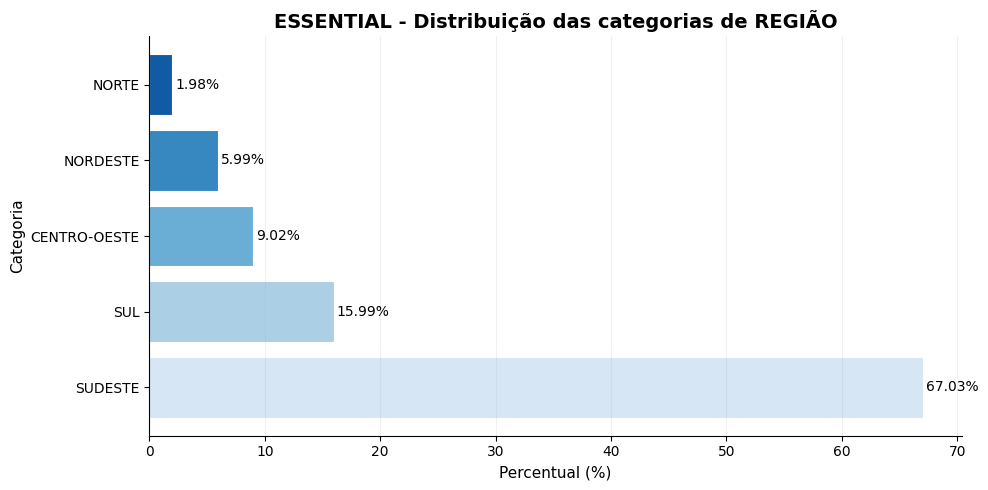

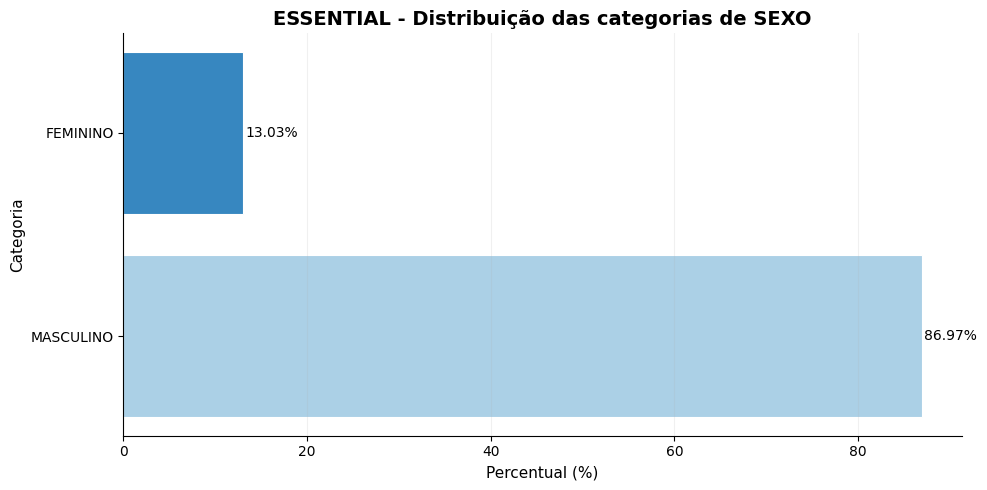

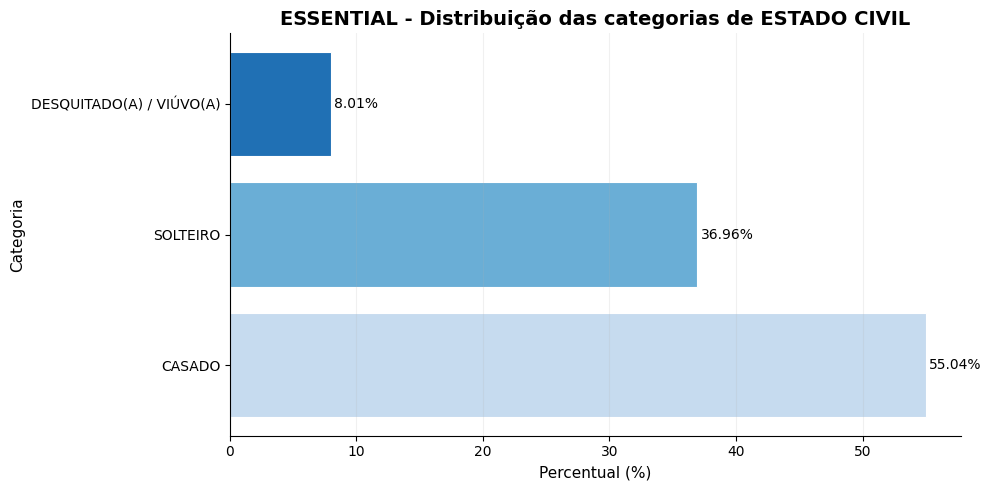

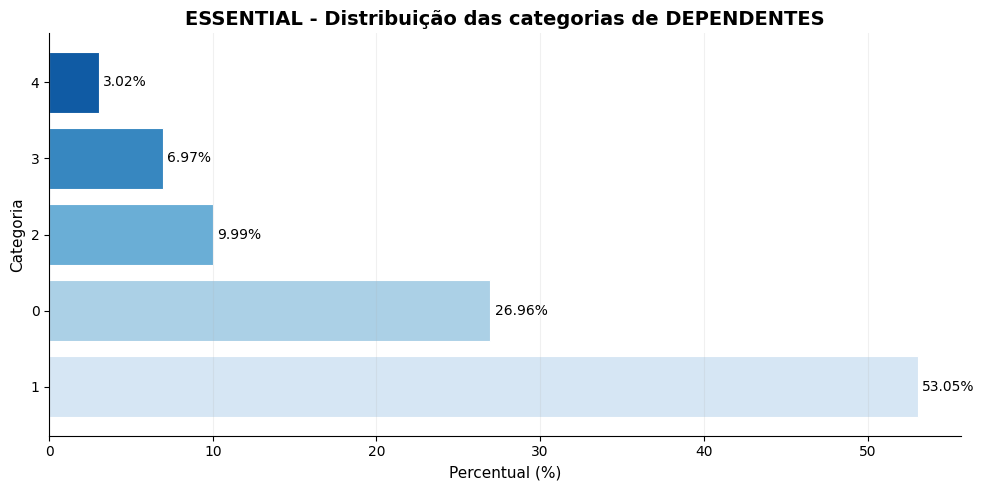

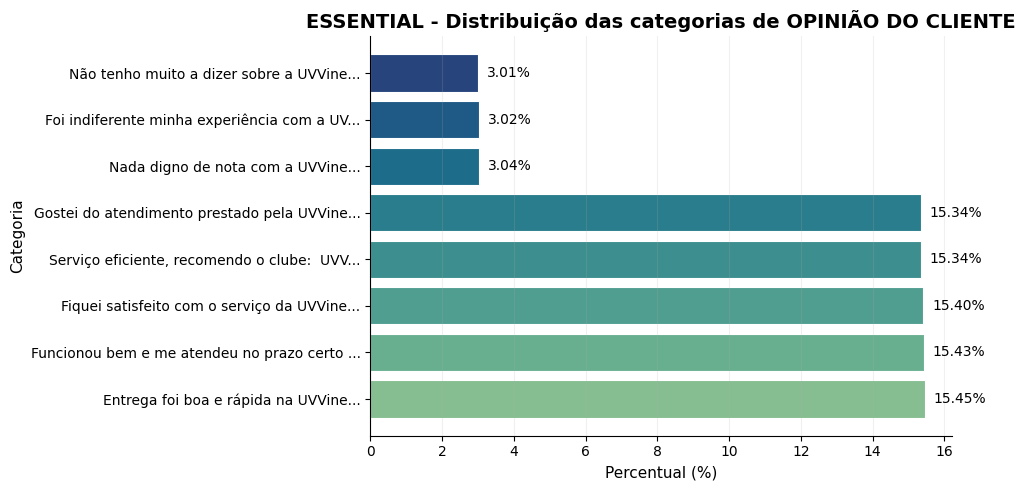

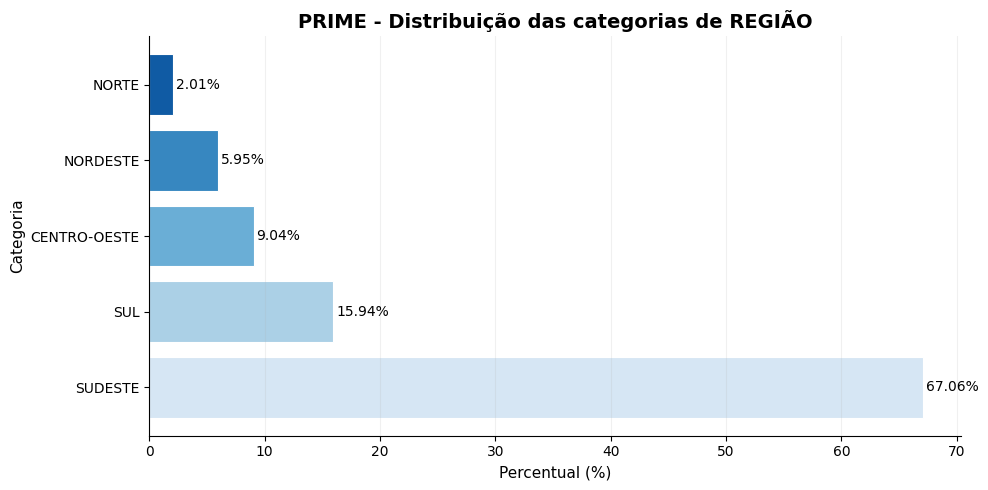

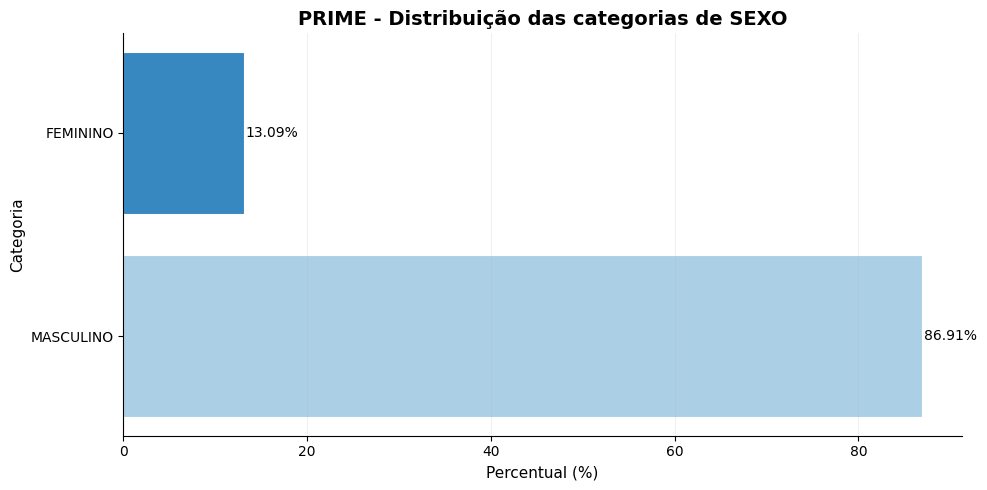

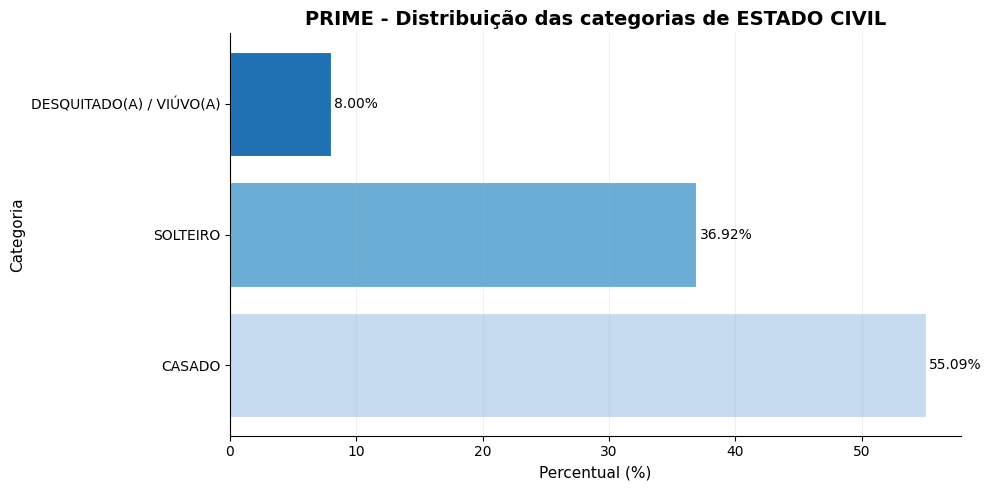

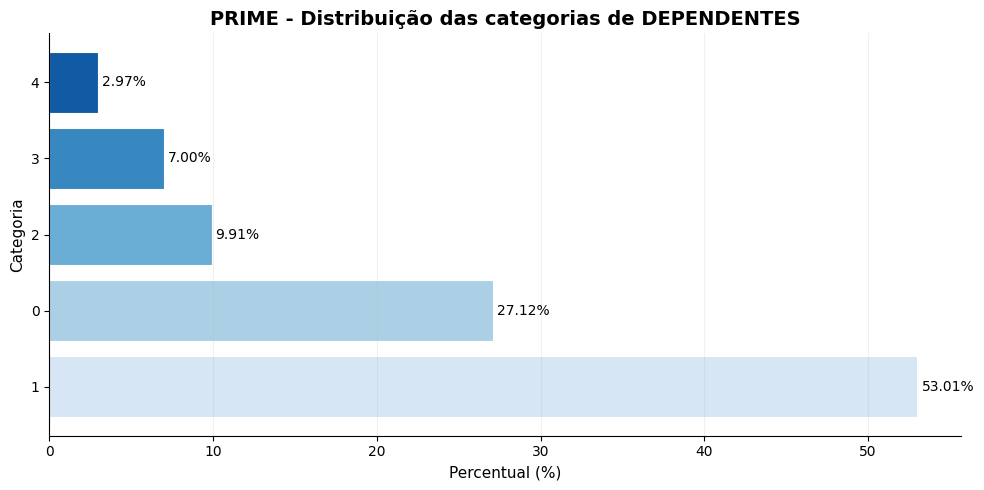

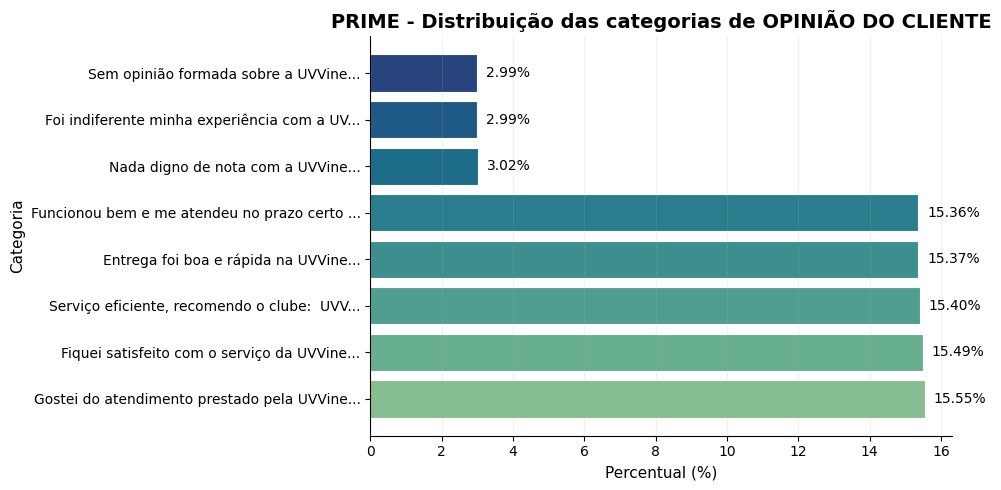

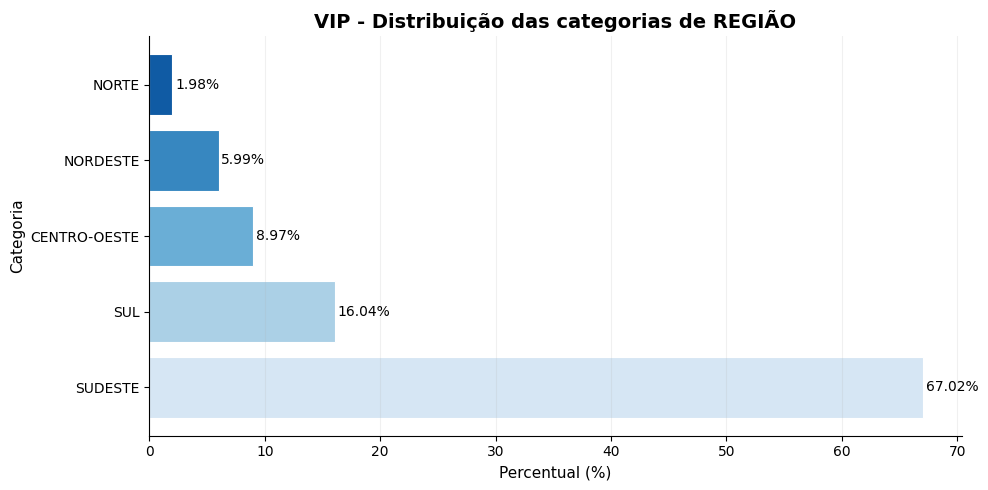

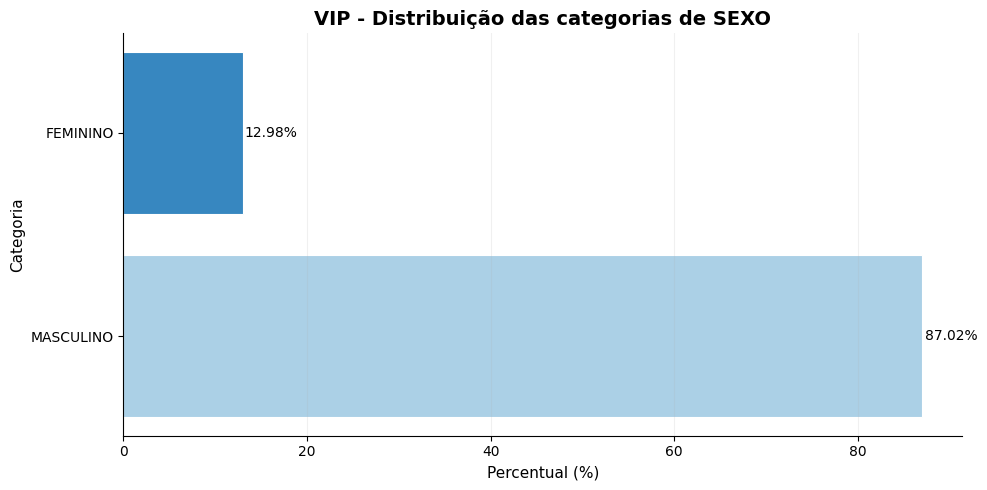

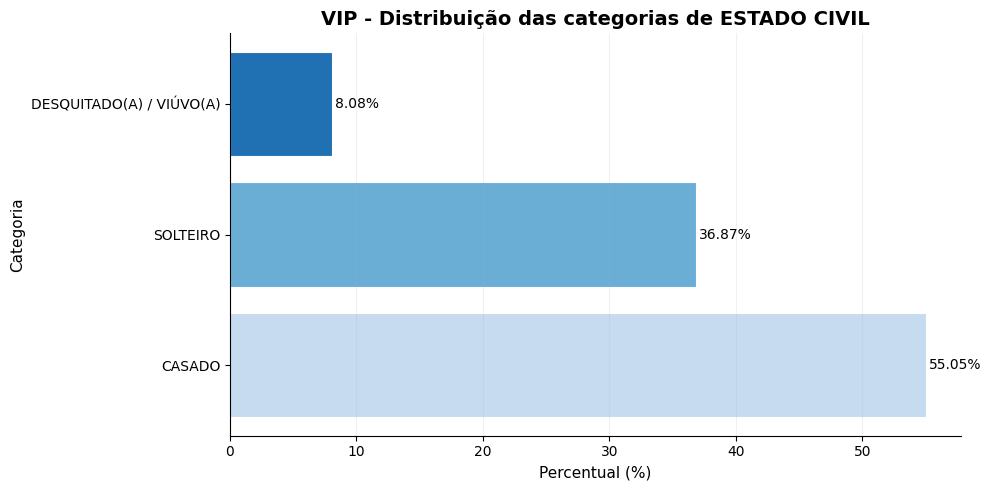

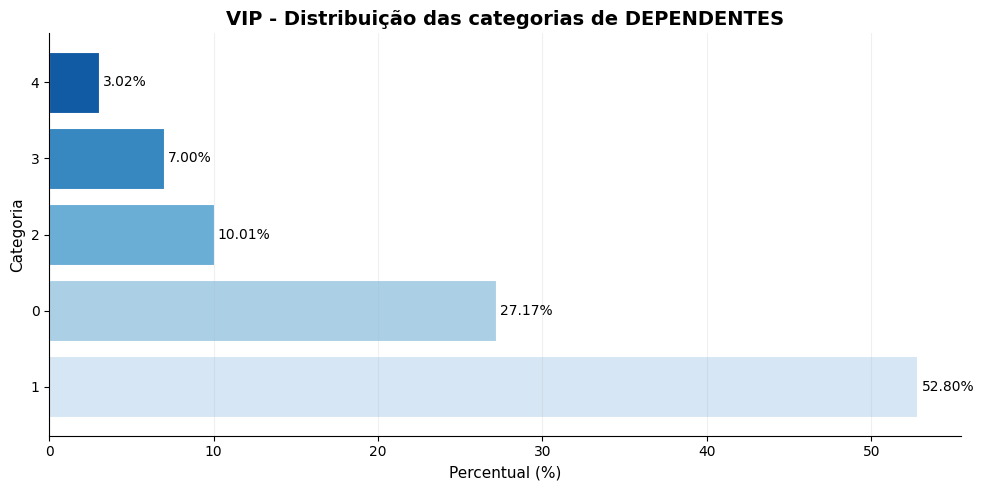

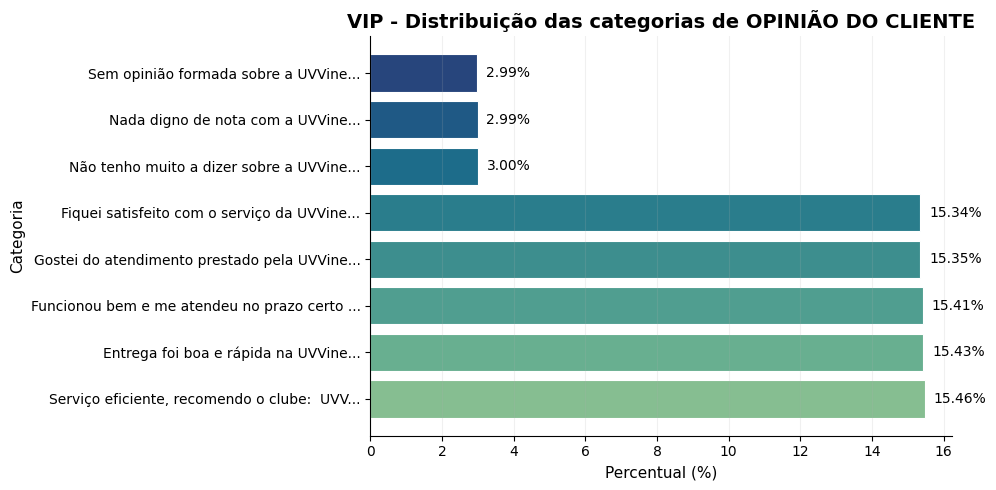

In [ ]:
variaveis_plot = ["REGIÃO", "SEXO", "ESTADO CIVIL", "DEPENDENTES", "OPINIÃO DO CLIENTE"]

for grupo in resultado["grupos"]:
    for variavel in variaveis_plot:
        if variavel in resultado["resumo_por_grupo"][grupo]["resumo_por_variavel"]:
            plot_top_categorias_grupo(resultado, grupo, variavel, top_n=8, figsize=(10, 5))



A análise das variáveis qualitativas mostrou que ESSENTIAL, PRIME e VIP têm perfis categóricos muito parecidos, com os mesmos padrões de concentração e diferenças de décimos de ponto percentual entre os segmentos. Nenhuma das variáveis apresentou valores ausentes.

Em REGIÃO, o SUDESTE predomina nos três grupos, com cerca de 67% dos registros (67,03% em ESSENTIAL, 67,06% em PRIME e 67,02% em VIP), e as duas principais regiões já somam cerca de 92%. SEXO tem a maior concentração entre as variáveis, com MASCULINO em torno de 87% em todos os grupos. Em ESTADO CIVIL, a concentração é moderada: CASADO aparece em cerca de 55% dos registros, seguido por SOLTEIRO (36,87% a 36,96%) e por DESQUITADO(A) / VIÚVO(A) (cerca de 8%).

DEPENDENTES também tem concentração moderada, com a categoria 1 em torno de 53% (de 52,80% em VIP a 53,05% em ESSENTIAL), seguida por 0, com aproximadamente 27%. As três categorias mais frequentes somam cerca de 90% dos registros, e as categorias 3 e 4 ficam em torno de 7% e 3%. Isso indica um perfil familiar estável entre os segmentos.

OPINIÃO DO CLIENTE foi a variável mais diversa, com 25 categorias e distribuição mais equilibrada. A categoria mais frequente representa cerca de 15,5% dos registros em cada grupo (15,45% em ESSENTIAL, 15,55% em PRIME e 15,46% em VIP), as três principais somam cerca de 46% e as cinco principais, cerca de 77%. A resposta mais comum muda entre os grupos, mas todas são positivas, e nenhuma domina a variável.

Conclui-se que as variáveis qualitativas têm estrutura estável entre ESSENTIAL, PRIME e VIP, com padrões de concentração praticamente iguais em REGIÃO, SEXO, ESTADO CIVIL e DEPENDENTES. OPINIÃO DO CLIENTE se destacou por manter maior diversidade de categorias em todos os grupos, o que reforça seu potencial informativo nas etapas seguintes.

##Atividade A3: Resultado da Pesquisa de Satisfação

Em relaçao a este tópico, busca-se consolidar a percepção dos clientes por meio da classificação da variável qualitativa `OPINIÃO DO CLIENTE` em cinco níveis de satisfação: `Muito insatisfeito`, `Insatisfeito`, `Indiferente`, `Satisfeito` e `Muito satisfeito`.

A análise é realizada de forma individual nos grupos `ESSENTIAL`, `PRIME` e `VIP`, possibilitando observar e comparar a distribuição percentual dos diferentes níveis de satisfação entre os segmentos. Essa abordagem permite uma análise mais adequada à estrutura da base de dados, preservando as diferenças existentes entre os grupos e evitando que uma análise agregada oculte características específicas de cada segmento.


Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

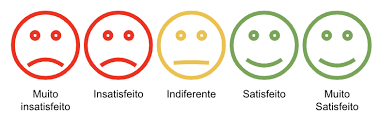

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

A classificação é feita a partir do conteúdo textual das respostas, permitindo enquadrar cada registro em um dos níveis de satisfação definidos. Posteriormente, calcula-se a proporção percentual de cada categoria dentro dos grupos `ESSENTIAL`, `PRIME` e `VIP`. Para complementar a análise, aplica-se a técnica de bootstrap na estimação dos intervalos de confiança dos percentuais obtidos para cada nível de satisfação, proporcionando maior segurança na interpretação dos resultados.


In [ ]:
def classificar_satisfacao_5_niveis(texto):
    if pd.isna(texto):
        return np.nan

    t = str(texto).strip().upper()

    muito_satisfeito = [
        "EXCELENTE", "ÓTIMO", "OTIMO", "PERFEITO", "IMPECÁVEL", "IMPECAVEL",
        "SUPEROU", "ADOREI", "AMEI", "MUITO SATISFEITO", "MUITO BOA",
        "SERVIÇO EFICIENTE", "RECOMENDO", "ENTREGA FOI BOA E RÁPIDA",
        "ENTREGA FOI BOA E RAPIDA", "FUNCIONOU BEM", "FIQUEI SATISFEITO"
    ]

    satisfeito = [
        "GOSTEI", "SATISFEITO", "BOM", "BOA", "ATENDEU", "PRAZO CERTO",
        "ATENDIMENTO PRESTADO", "SERVIÇO BOM", "SERVICO BOM"
    ]

    indiferente = [
        "INDIFERENTE", "NEUTRO", "NEUTRA", "RAZOÁVEL", "RAZOAVEL",
        "NORMAL", "COMUM", "NADA DIGNO DE NOTA", "NÃO TENHO MUITO A DIZER",
        "NAO TENHO MUITO A DIZER"
    ]

    insatisfeito = [
        "RUIM", "INSATISFEITO", "DEMORADO", "NÃO GOSTEI", "NAO GOSTEI",
        "PROBLEMA", "DEIXOU A DESEJAR", "PODERIA SER MELHOR"
    ]

    muito_insatisfeito = [
        "PÉSSIMO", "PESSIMO", "HORRÍVEL", "HORRIVEL", "MUITO INSATISFEITO",
        "NUNCA MAIS", "TERRÍVEL", "TERRIVEL"
    ]

    if any(chave in t for chave in muito_insatisfeito):
        return "Muito insatisfeito"
    if any(chave in t for chave in insatisfeito):
        return "Insatisfeito"
    if any(chave in t for chave in indiferente):
        return "Indiferente"
    if any(chave in t for chave in muito_satisfeito):
        return "Muito satisfeito"
    if any(chave in t for chave in satisfeito):
        return "Satisfeito"

    return "Indiferente"


def bootstrap_proporcao_categoria(categorias, categoria_alvo, B=3000, seed=42):
    rng = np.random.default_rng(seed)
    valores = (categorias == categoria_alvo).astype(float).values
    n = len(valores)

    boot = np.empty(B, dtype=float)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = valores[idx].mean() * 100

    ic_inf = float(np.percentile(boot, 2.5))
    ic_sup = float(np.percentile(boot, 97.5))

    return boot, ic_inf, ic_sup


In [ ]:
def AtividadeA3_1(B=3000, seed=42):
    grupos_alvo = ["ESSENTIAL", "PRIME", "VIP"]
    ordem_categorias = [
        "Muito insatisfeito",
        "Insatisfeito",
        "Indiferente",
        "Satisfeito",
        "Muito satisfeito"
    ]

    base_ref = RESULTADOS.get("A1.2", {}).get("table_limpa", table).copy()
    resultados_geral = []
    resultados_sexo = []
    bootstrap_resultados = {}

    for grupo in grupos_alvo:
        df_grupo = base_ref[base_ref["TIPO DA CONTA"] == grupo].copy()

        bootstrap_resultados[grupo] = {
            "geral": {},
            "por_sexo": {}
        }

        # -------------------------
        # Geral dentro do grupo
        # -------------------------
        opiniao = df_grupo["OPINIÃO DO CLIENTE"].dropna().copy()
        categorias = opiniao.apply(classificar_satisfacao_5_niveis)
        n_validos = int(len(categorias))

        freq_abs = categorias.value_counts().reindex(ordem_categorias, fill_value=0)
        freq_pct = (freq_abs / n_validos) * 100 if n_validos > 0 else 0

        for cat in ordem_categorias:
            boot, ic_inf, ic_sup = bootstrap_proporcao_categoria(
                categorias,
                categoria_alvo=cat,
                B=B,
                seed=seed
            )

            bootstrap_resultados[grupo]["geral"][cat] = {
                "bootstrap_%": boot,
                "ic95_%": (ic_inf, ic_sup),
            }

            resultados_geral.append({
                "Grupo": grupo,
                "Categoria": cat,
                "N válidos": n_validos,
                "Freq. absoluta": int(freq_abs[cat]),
                "Freq. (%)": float(freq_pct[cat]),
                "IC 95% inferior": ic_inf,
                "IC 95% superior": ic_sup,
            })

        # -------------------------
        # Por sexo dentro do grupo
        # -------------------------
        df_sexo = df_grupo[["SEXO", "OPINIÃO DO CLIENTE"]].dropna().copy()
        df_sexo["SEXO"] = df_sexo["SEXO"].astype(str).str.strip()

        for sexo in sorted(df_sexo["SEXO"].unique()):
            df_sub = df_sexo[df_sexo["SEXO"] == sexo].copy()
            categorias_sexo = df_sub["OPINIÃO DO CLIENTE"].apply(classificar_satisfacao_5_niveis)
            n_validos_sexo = int(len(categorias_sexo))

            freq_abs_sexo = categorias_sexo.value_counts().reindex(ordem_categorias, fill_value=0)
            freq_pct_sexo = (freq_abs_sexo / n_validos_sexo) * 100 if n_validos_sexo > 0 else 0

            bootstrap_resultados[grupo]["por_sexo"][sexo] = {}

            for cat in ordem_categorias:
                boot, ic_inf, ic_sup = bootstrap_proporcao_categoria(
                    categorias_sexo,
                    categoria_alvo=cat,
                    B=B,
                    seed=seed
                )

                bootstrap_resultados[grupo]["por_sexo"][sexo][cat] = {
                    "bootstrap_%": boot,
                    "ic95_%": (ic_inf, ic_sup),
                }

                resultados_sexo.append({
                    "Grupo": grupo,
                    "Sexo": sexo,
                    "Categoria": cat,
                    "N válidos": n_validos_sexo,
                    "Freq. absoluta": int(freq_abs_sexo[cat]),
                    "Freq. (%)": float(freq_pct_sexo[cat]),
                    "IC 95% inferior": ic_inf,
                    "IC 95% superior": ic_sup,
                })

    tabela_resultados = pd.DataFrame(resultados_geral)
    tabela_resultados_sexo = pd.DataFrame(resultados_sexo)

    RESULTADOS["A3.1"] = {
        "grupos": grupos_alvo,
        "ordem_categorias": ordem_categorias,
        "tabela_resultados": tabela_resultados,
        "tabela_resultados_sexo": tabela_resultados_sexo,
        "bootstrap": bootstrap_resultados,
    }

    print("Resultado da pesquisa de satisfação por grupos calculado.")
    print(f"Grupos analisados: {len(grupos_alvo)}")
    print(f"Categorias de satisfação: {len(ordem_categorias)}")
    print("Também foi calculada a distribuição por sexo dentro de cada grupo.")


In [ ]:
AtividadeA3_1()

resultado = RESULTADOS["A3.1"]
tabela_satisfacao = resultado["tabela_resultados"].copy()
tabela_satisfacao_sexo = resultado["tabela_resultados_sexo"].copy()

Resultado da pesquisa de satisfação por grupos calculado.
Grupos analisados: 3
Categorias de satisfação: 5
Também foi calculada a distribuição por sexo dentro de cada grupo.


In [ ]:
tabela_satisfacao[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]] = (
    tabela_satisfacao[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]].round(2)
)

display(tabela_satisfacao)


,Grupo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
0,ESSENTIAL,Muito insatisfeito,683501,0,0.00,0.00,0.00
1,ESSENTIAL,Insatisfeito,683501,4093,0.60,0.58,0.62
2,ESSENTIAL,Indiferente,683501,127271,18.62,18.53,18.71
3,ESSENTIAL,Satisfeito,683501,110337,16.14,16.05,16.23
4,ESSENTIAL,Muito satisfeito,683501,441800,64.64,64.52,64.75
5,PRIME,Muito insatisfeito,183226,0,0.00,0.00,0.00
6,PRIME,Insatisfeito,183226,1101,0.60,0.57,0.64
7,PRIME,Indiferente,183226,33933,18.52,18.34,18.69
8,PRIME,Satisfeito,183226,29925,16.33,16.16,16.50
9,PRIME,Muito satisfeito,183226,118267,64.55,64.33,64.76


In [ ]:
for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo}")
    display(
        tabela_satisfacao[tabela_satisfacao["Grupo"] == grupo][[
            "Categoria", "N válidos", "Freq. absoluta", "Freq. (%)",
            "IC 95% inferior", "IC 95% superior"
        ]]
    )



Grupo: ESSENTIAL


,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
0,Muito insatisfeito,683501,0,0.00,0.00,0.00
1,Insatisfeito,683501,4093,0.60,0.58,0.62
2,Indiferente,683501,127271,18.62,18.53,18.71
3,Satisfeito,683501,110337,16.14,16.05,16.23
4,Muito satisfeito,683501,441800,64.64,64.52,64.75



Grupo: PRIME


,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
5,Muito insatisfeito,183226,0,0.00,0.00,0.00
6,Insatisfeito,183226,1101,0.60,0.57,0.64
7,Indiferente,183226,33933,18.52,18.34,18.69
8,Satisfeito,183226,29925,16.33,16.16,16.50
9,Muito satisfeito,183226,118267,64.55,64.33,64.76



Grupo: VIP


,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
10,Muito insatisfeito,253273,0,0.00,0.00,0.00
11,Insatisfeito,253273,1540,0.61,0.58,0.64
12,Indiferente,253273,47044,18.57,18.42,18.72
13,Satisfeito,253273,40938,16.16,16.03,16.31
14,Muito satisfeito,253273,163751,64.65,64.47,64.83


In [ ]:
tabela_satisfacao_sexo[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]] = (
    tabela_satisfacao_sexo[["Freq. (%)", "IC 95% inferior", "IC 95% superior"]].round(2)
)

for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo} - por sexo")
    display(
        tabela_satisfacao_sexo[tabela_satisfacao_sexo["Grupo"] == grupo][[
            "Sexo", "Categoria", "N válidos", "Freq. absoluta", "Freq. (%)",
            "IC 95% inferior", "IC 95% superior"
        ]]
    )



Grupo: ESSENTIAL - por sexo


,Sexo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
0,FEMININO,Muito insatisfeito,89094,0,0.00,0.00,0.00
1,FEMININO,Insatisfeito,89094,538,0.60,0.55,0.66
2,FEMININO,Indiferente,89094,16765,18.82,18.56,19.08
3,FEMININO,Satisfeito,89094,14278,16.03,15.78,16.27
4,FEMININO,Muito satisfeito,89094,57513,64.55,64.23,64.86
5,MASCULINO,Muito insatisfeito,594407,0,0.00,0.00,0.00
6,MASCULINO,Insatisfeito,594407,3555,0.60,0.58,0.62
7,MASCULINO,Indiferente,594407,110506,18.59,18.49,18.69
8,MASCULINO,Satisfeito,594407,96059,16.16,16.07,16.25
9,MASCULINO,Muito satisfeito,594407,384287,64.65,64.53,64.77



Grupo: PRIME - por sexo


,Sexo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
10,FEMININO,Muito insatisfeito,23980,0,0.00,0.00,0.00
11,FEMININO,Insatisfeito,23980,135,0.56,0.47,0.66
12,FEMININO,Indiferente,23980,4432,18.48,18.00,18.97
13,FEMININO,Satisfeito,23980,3939,16.43,15.95,16.90
14,FEMININO,Muito satisfeito,23980,15474,64.53,63.93,65.15
15,MASCULINO,Muito insatisfeito,159246,0,0.00,0.00,0.00
16,MASCULINO,Insatisfeito,159246,966,0.61,0.57,0.64
17,MASCULINO,Indiferente,159246,29501,18.53,18.34,18.72
18,MASCULINO,Satisfeito,159246,25986,16.32,16.13,16.50
19,MASCULINO,Muito satisfeito,159246,102793,64.55,64.32,64.79



Grupo: VIP - por sexo


,Sexo,Categoria,N válidos,Freq. absoluta,Freq. (%),IC 95% inferior,IC 95% superior
20,FEMININO,Muito insatisfeito,32877,0,0.00,0.00,0.00
21,FEMININO,Insatisfeito,32877,219,0.67,0.58,0.75
22,FEMININO,Indiferente,32877,6227,18.94,18.51,19.37
23,FEMININO,Satisfeito,32877,5287,16.08,15.67,16.48
24,FEMININO,Muito satisfeito,32877,21144,64.31,63.81,64.87
25,MASCULINO,Muito insatisfeito,220396,0,0.00,0.00,0.00
26,MASCULINO,Insatisfeito,220396,1321,0.60,0.57,0.63
27,MASCULINO,Indiferente,220396,40817,18.52,18.35,18.69
28,MASCULINO,Satisfeito,220396,35651,16.18,16.02,16.33
29,MASCULINO,Muito satisfeito,220396,142607,64.70,64.51,64.91


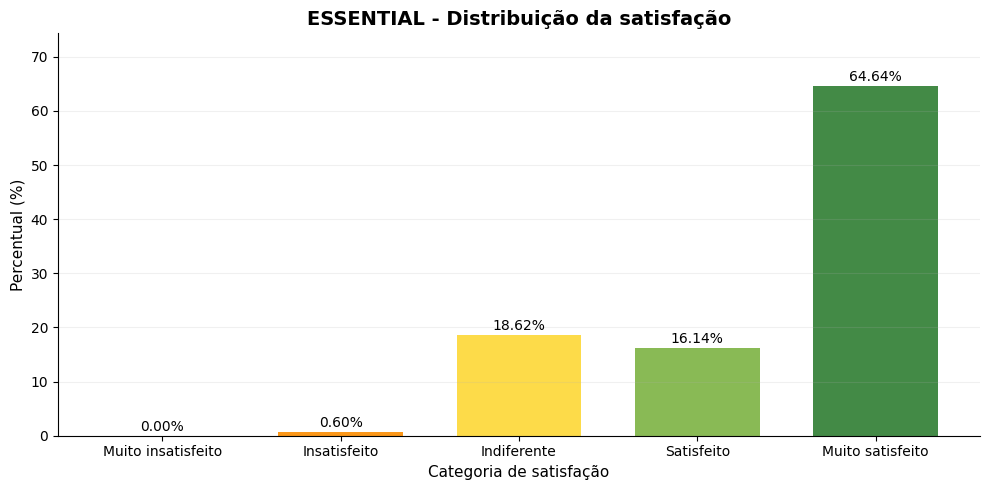

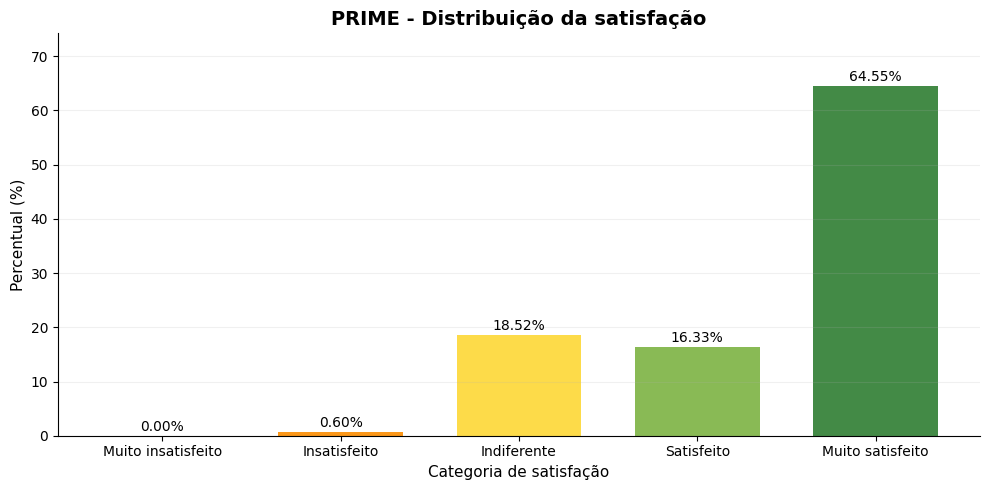

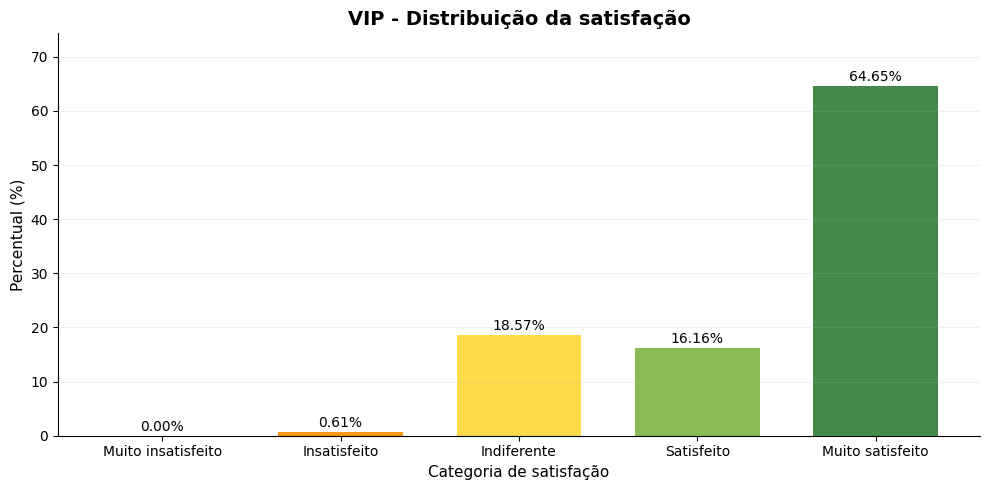

In [ ]:
cores_satisfacao = {
    "Muito insatisfeito": "#E53935",
    "Insatisfeito": "#FB8C00",
    "Indiferente": "#FDD835",
    "Satisfeito": "#7CB342",
    "Muito satisfeito": "#2E7D32",
}

for grupo in resultado["grupos"]:
    df_plot = tabela_satisfacao[tabela_satisfacao["Grupo"] == grupo].copy()

    plt.figure(figsize=(10, 5))

    bars = plt.bar(
        df_plot["Categoria"],
        df_plot["Freq. (%)"],
        color=[cores_satisfacao[c] for c in df_plot["Categoria"]],
        alpha=0.9,
        width=0.7,
    )

    for bar, valor in zip(bars, df_plot["Freq. (%)"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            valor + 0.4,
            f"{valor:.2f}%",
            ha="center",
            va="bottom",
            fontsize=10,
        )

    plt.title(f"{grupo} - Distribuição da satisfação", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Percentual (%)", fontsize=11)
    plt.ylim(0, max(df_plot["Freq. (%)"]) * 1.15 if len(df_plot) > 0 else 100)
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


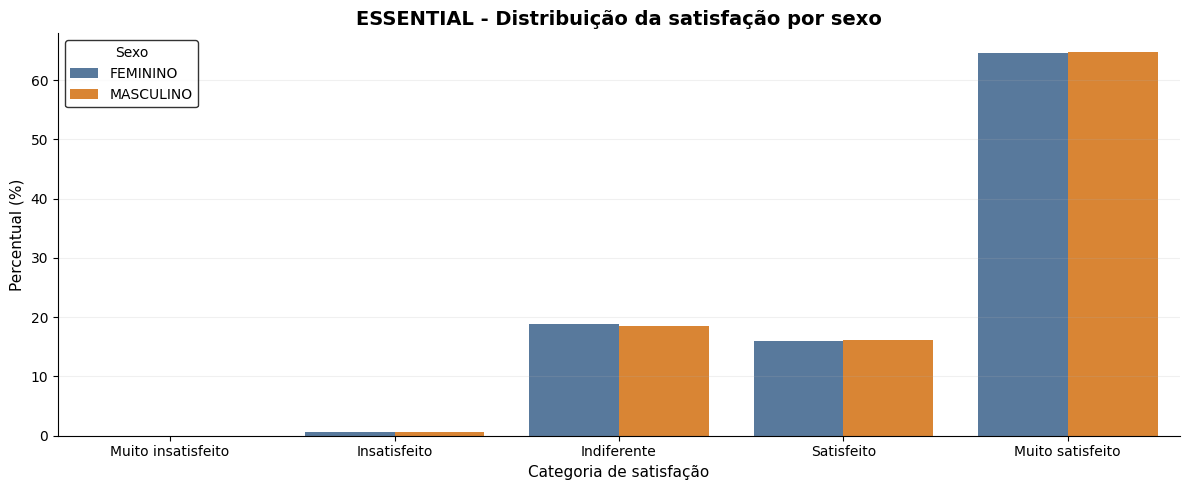

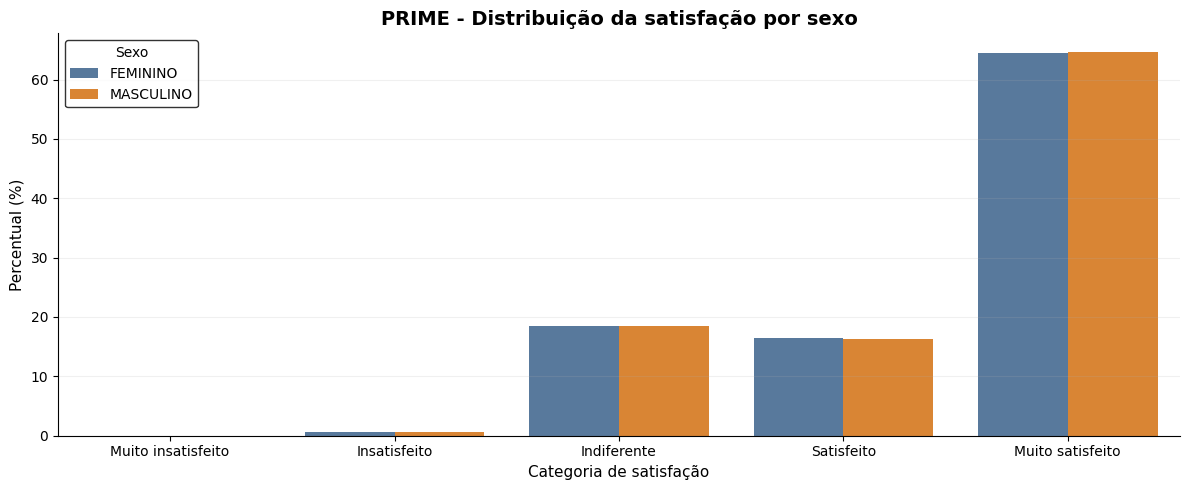

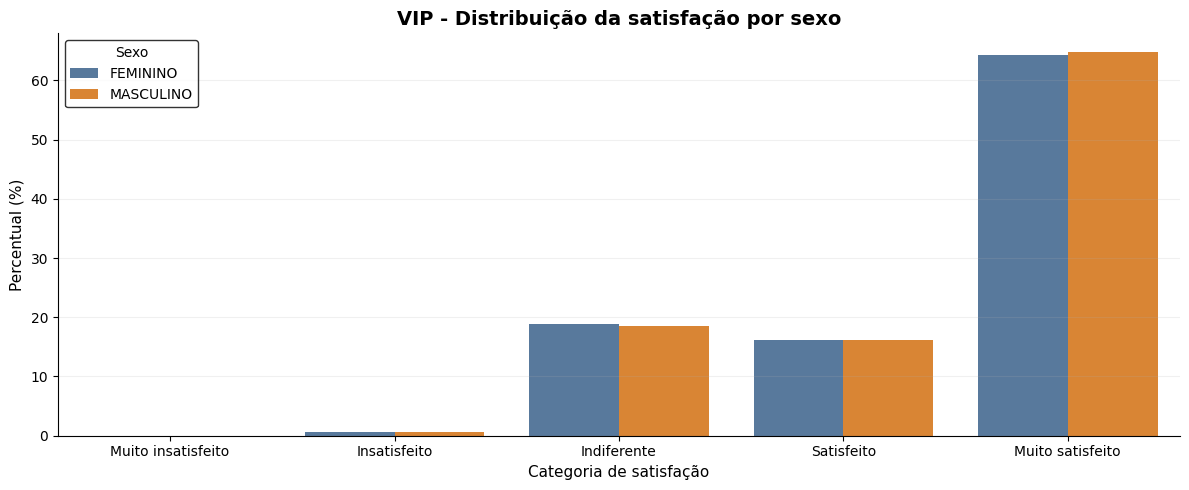

In [ ]:
for grupo in resultado["grupos"]:
    df_plot = tabela_satisfacao_sexo[tabela_satisfacao_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=df_plot,
        x="Categoria",
        y="Freq. (%)",
        hue="Sexo",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Distribuição da satisfação por sexo", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Percentual (%)", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.legend(title="Sexo", frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


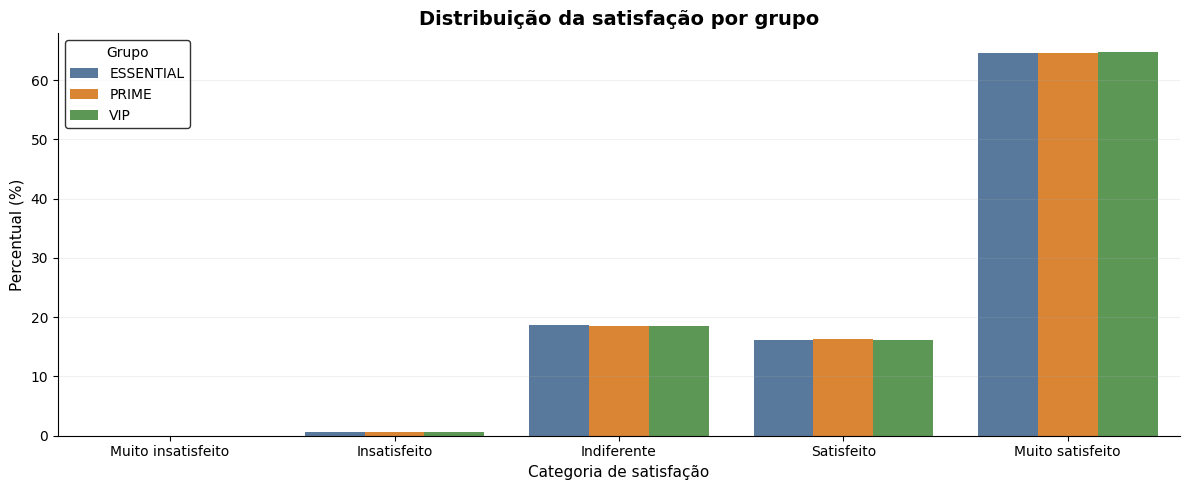

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabela_satisfacao,
    x="Categoria",
    y="Freq. (%)",
    hue="Grupo",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Distribuição da satisfação por grupo", fontsize=14, fontweight="bold")
plt.xlabel("Categoria de satisfação", fontsize=11)
plt.ylabel("Percentual (%)", fontsize=11)
plt.grid(axis="y", alpha=0.18)
plt.legend(title="Grupo", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


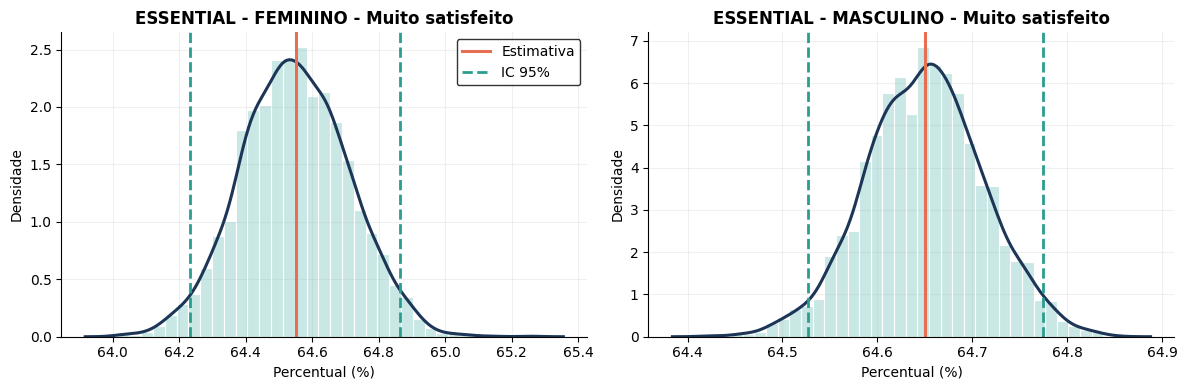

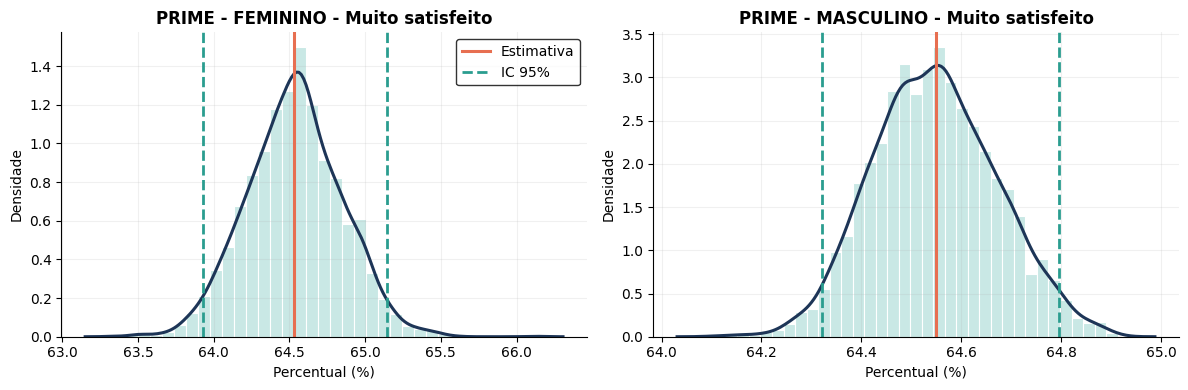

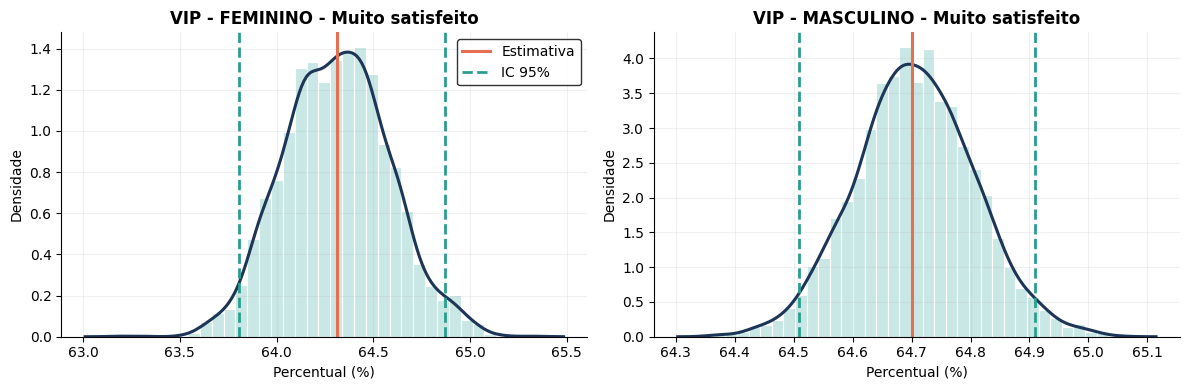

In [ ]:
categoria_plot = "Muito satisfeito"

for grupo in resultado["grupos"]:
    sexos_grupo = tabela_satisfacao_sexo[tabela_satisfacao_sexo["Grupo"] == grupo]["Sexo"].unique()

    fig, axes = plt.subplots(1, len(sexos_grupo), figsize=(6 * len(sexos_grupo), 4))

    if len(sexos_grupo) == 1:
        axes = [axes]

    for ax, sexo in zip(axes, sexos_grupo):
        boot = resultado["bootstrap"][grupo]["por_sexo"][sexo][categoria_plot]["bootstrap_%"]
        ic_inf, ic_sup = resultado["bootstrap"][grupo]["por_sexo"][sexo][categoria_plot]["ic95_%"]

        estimativa = tabela_satisfacao_sexo[
            (tabela_satisfacao_sexo["Grupo"] == grupo) &
            (tabela_satisfacao_sexo["Sexo"] == sexo) &
            (tabela_satisfacao_sexo["Categoria"] == categoria_plot)
        ]["Freq. (%)"].iloc[0]

        sns.histplot(
            boot,
            bins=35,
            stat="density",
            color="#B8E1DD",
            edgecolor="white",
            alpha=0.75,
            ax=ax
        )

        sns.kdeplot(
            boot,
            color="#1D3557",
            linewidth=2.2,
            ax=ax
        )

        ax.axvline(estimativa, color="#E76F51", linewidth=2.2, label="Estimativa")
        ax.axvline(ic_inf, color="#2A9D8F", linestyle="--", linewidth=2, label="IC 95%")
        ax.axvline(ic_sup, color="#2A9D8F", linestyle="--", linewidth=2)

        ax.set_title(f"{grupo} - {sexo} - {categoria_plot}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Percentual (%)")
        ax.set_ylabel("Densidade")
        ax.grid(alpha=0.18)

    axes[0].legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


Os resultados da A3.1 mostram que a distribuição da satisfação é muito parecida entre ESSENTIAL, PRIME e VIP. Em todos os grupos, a categoria dominante foi Muito satisfeito, com 64,64% em ESSENTIAL, 64,55% em PRIME e 64,65% em VIP. Indiferente (18,62%, 18,52% e 18,57%) e Satisfeito (16,14%, 16,33% e 16,16%) vêm em seguida, com valores próximos entre os segmentos. Insatisfeito ficou em cerca de 0,6% em todos os grupos, e Muito insatisfeito não teve nenhuma ocorrência.

Dentro de cada grupo, a análise por sexo manteve o mesmo padrão. O percentual de Muito satisfeito foi de 64,55% em FEMININO e 64,65% em MASCULINO em ESSENTIAL, de 64,53% e 64,55% em PRIME e de 64,31% e 64,70% em VIP. A maior diferença entre sexos foi de 0,39 ponto percentual, em VIP, e o mesmo comportamento aparece nas demais categorias.

Os intervalos de confiança por bootstrap foram estreitos na leitura geral dos grupos, com amplitudes de até 0,43 ponto percentual na categoria Muito satisfeito. Na segmentação por sexo, os intervalos de FEMININO são mais largos que os de MASCULINO, o que é esperado pelo menor número de registros, mas continuam estreitos.

Conclui-se que a percepção dos clientes é predominantemente positiva, homogênea entre os três grupos e estável por sexo. O predomínio de Muito satisfeito e a presença quase nula de avaliações negativas indicam uma experiência consistentemente favorável em todos os segmentos.

###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

Nesta etapa, a análise da satisfação dos clientes é aprofundada por meio da aplicação da técnica de bootstrap, buscando avaliar a precisão estatística dos percentuais identificados em cada categoria de satisfação.

O procedimento é realizado separadamente nos grupos `ESSENTIAL`, `PRIME` e `VIP`, considerando duas perspectivas de análise: a distribuição geral dos níveis de satisfação em cada grupo e a distribuição desses níveis de acordo com o sexo dos clientes dentro de cada segmento. Para ambas as abordagens, são analisadas as cinco categorias de satisfação: `Muito insatisfeito`, `Insatisfeito`, `Indiferente`, `Satisfeito` e `Muito satisfeito`.

Com isso, a etapa possibilita verificar a consistência das estimativas obtidas, comparar a precisão dos resultados entre os diferentes grupos e identificar possíveis diferenças nos níveis de satisfação de acordo com o sexo dos clientes em cada segmento.


In [ ]:
def AtividadeA3_2():
    if "A3.1" not in RESULTADOS:
        raise ValueError("Execute a Atividade A3.1 antes desta etapa.")

    resultado_a31 = RESULTADOS["A3.1"]

    tabela_geral = resultado_a31["tabela_resultados"].copy()
    tabela_sexo = resultado_a31["tabela_resultados_sexo"].copy()

    linhas_geral = []
    linhas_sexo = []

    for grupo in resultado_a31["grupos"]:
        for categoria in resultado_a31["ordem_categorias"]:
            linha = tabela_geral[
                (tabela_geral["Grupo"] == grupo) &
                (tabela_geral["Categoria"] == categoria)
            ].iloc[0]

            boot = resultado_a31["bootstrap"][grupo]["geral"][categoria]["bootstrap_%"]
            ic_inf, ic_sup = resultado_a31["bootstrap"][grupo]["geral"][categoria]["ic95_%"]
            se_boot = float(np.std(boot, ddof=1))

            linhas_geral.append({
                "Grupo": grupo,
                "Categoria": categoria,
                "N válidos": int(linha["N válidos"]),
                "Freq. (%)": float(linha["Freq. (%)"]),
                "Erro padrão bootstrap": se_boot,
                "IC 95% inferior": float(ic_inf),
                "IC 95% superior": float(ic_sup),
                "Amplitude IC": float(ic_sup - ic_inf),
            })

    for grupo in resultado_a31["grupos"]:
        sexos_grupo = sorted(
            tabela_sexo[tabela_sexo["Grupo"] == grupo]["Sexo"].dropna().unique()
        )

        for sexo in sexos_grupo:
            for categoria in resultado_a31["ordem_categorias"]:
                linha = tabela_sexo[
                    (tabela_sexo["Grupo"] == grupo) &
                    (tabela_sexo["Sexo"] == sexo) &
                    (tabela_sexo["Categoria"] == categoria)
                ].iloc[0]

                boot = resultado_a31["bootstrap"][grupo]["por_sexo"][sexo][categoria]["bootstrap_%"]
                ic_inf, ic_sup = resultado_a31["bootstrap"][grupo]["por_sexo"][sexo][categoria]["ic95_%"]
                se_boot = float(np.std(boot, ddof=1))

                linhas_sexo.append({
                    "Grupo": grupo,
                    "Sexo": sexo,
                    "Categoria": categoria,
                    "N válidos": int(linha["N válidos"]),
                    "Freq. (%)": float(linha["Freq. (%)"]),
                    "Erro padrão bootstrap": se_boot,
                    "IC 95% inferior": float(ic_inf),
                    "IC 95% superior": float(ic_sup),
                    "Amplitude IC": float(ic_sup - ic_inf),
                })

    tabela_bootstrap_geral = pd.DataFrame(linhas_geral)
    tabela_bootstrap_sexo = pd.DataFrame(linhas_sexo)

    RESULTADOS["A3.2"] = {
        "grupos": resultado_a31["grupos"],
        "ordem_categorias": resultado_a31["ordem_categorias"],
        "tabela_bootstrap": tabela_bootstrap_geral,
        "tabela_bootstrap_sexo": tabela_bootstrap_sexo,
        "bootstrap": resultado_a31["bootstrap"],
    }

    print("Análise bootstrap da satisfação por grupos concluída.")
    print(f"Grupos analisados: {len(resultado_a31['grupos'])}")
    print(f"Categorias analisadas: {len(resultado_a31['ordem_categorias'])}")
    print("Também foi calculada a precisão bootstrap por sexo dentro de cada grupo.")


In [ ]:
AtividadeA3_2()

resultado = RESULTADOS["A3.2"]
tabela_bootstrap = resultado["tabela_bootstrap"].copy()
tabela_bootstrap_sexo = resultado["tabela_bootstrap_sexo"].copy()


Análise bootstrap da satisfação por grupos concluída.
Grupos analisados: 3
Categorias analisadas: 5
Também foi calculada a precisão bootstrap por sexo dentro de cada grupo.


In [ ]:
tabela_bootstrap[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]] = tabela_bootstrap[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]].round(2)

display(tabela_bootstrap)


,Grupo,Categoria,N válidos,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
0,ESSENTIAL,Muito insatisfeito,683501,0.00,0.00,0.00,0.00,0.00
1,ESSENTIAL,Insatisfeito,683501,0.60,0.01,0.58,0.62,0.04
2,ESSENTIAL,Indiferente,683501,18.62,0.05,18.53,18.71,0.18
3,ESSENTIAL,Satisfeito,683501,16.14,0.04,16.05,16.23,0.17
4,ESSENTIAL,Muito satisfeito,683501,64.64,0.06,64.52,64.75,0.23
5,PRIME,Muito insatisfeito,183226,0.00,0.00,0.00,0.00,0.00
6,PRIME,Insatisfeito,183226,0.60,0.02,0.57,0.64,0.07
7,PRIME,Indiferente,183226,18.52,0.09,18.34,18.69,0.35
8,PRIME,Satisfeito,183226,16.33,0.09,16.16,16.50,0.34
9,PRIME,Muito satisfeito,183226,64.55,0.11,64.33,64.76,0.43


In [ ]:
for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo}")
    display(
        tabela_bootstrap[tabela_bootstrap["Grupo"] == grupo][[
            "Categoria",
            "Freq. (%)",
            "Erro padrão bootstrap",
            "IC 95% inferior",
            "IC 95% superior",
            "Amplitude IC"
        ]]
    )



Grupo: ESSENTIAL


,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
0,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
1,Insatisfeito,0.60,0.01,0.58,0.62,0.04
2,Indiferente,18.62,0.05,18.53,18.71,0.18
3,Satisfeito,16.14,0.04,16.05,16.23,0.17
4,Muito satisfeito,64.64,0.06,64.52,64.75,0.23



Grupo: PRIME


,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
5,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
6,Insatisfeito,0.60,0.02,0.57,0.64,0.07
7,Indiferente,18.52,0.09,18.34,18.69,0.35
8,Satisfeito,16.33,0.09,16.16,16.50,0.34
9,Muito satisfeito,64.55,0.11,64.33,64.76,0.43



Grupo: VIP


,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
10,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
11,Insatisfeito,0.61,0.02,0.58,0.64,0.06
12,Indiferente,18.57,0.08,18.42,18.72,0.30
13,Satisfeito,16.16,0.07,16.03,16.31,0.28
14,Muito satisfeito,64.65,0.09,64.47,64.83,0.36


In [ ]:
tabela_bootstrap_sexo[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]] = tabela_bootstrap_sexo[[
    "Freq. (%)",
    "Erro padrão bootstrap",
    "IC 95% inferior",
    "IC 95% superior",
    "Amplitude IC"
]].round(2)

for grupo in resultado["grupos"]:
    print(f"\nGrupo: {grupo} - bootstrap por sexo")
    display(
        tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo][[
            "Sexo",
            "Categoria",
            "Freq. (%)",
            "Erro padrão bootstrap",
            "IC 95% inferior",
            "IC 95% superior",
            "Amplitude IC"
        ]]
    )



Grupo: ESSENTIAL - bootstrap por sexo


,Sexo,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
0,FEMININO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
1,FEMININO,Insatisfeito,0.60,0.03,0.55,0.66,0.10
2,FEMININO,Indiferente,18.82,0.13,18.56,19.08,0.53
3,FEMININO,Satisfeito,16.03,0.12,15.78,16.27,0.49
4,FEMININO,Muito satisfeito,64.55,0.16,64.23,64.86,0.63
5,MASCULINO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
6,MASCULINO,Insatisfeito,0.60,0.01,0.58,0.62,0.04
7,MASCULINO,Indiferente,18.59,0.05,18.49,18.69,0.20
8,MASCULINO,Satisfeito,16.16,0.05,16.07,16.25,0.18
9,MASCULINO,Muito satisfeito,64.65,0.06,64.53,64.77,0.25



Grupo: PRIME - bootstrap por sexo


,Sexo,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
10,FEMININO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
11,FEMININO,Insatisfeito,0.56,0.05,0.47,0.66,0.19
12,FEMININO,Indiferente,18.48,0.25,18.00,18.97,0.97
13,FEMININO,Satisfeito,16.43,0.24,15.95,16.90,0.95
14,FEMININO,Muito satisfeito,64.53,0.31,63.93,65.15,1.22
15,MASCULINO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
16,MASCULINO,Insatisfeito,0.61,0.02,0.57,0.64,0.07
17,MASCULINO,Indiferente,18.53,0.10,18.34,18.72,0.39
18,MASCULINO,Satisfeito,16.32,0.09,16.13,16.50,0.37
19,MASCULINO,Muito satisfeito,64.55,0.12,64.32,64.79,0.47



Grupo: VIP - bootstrap por sexo


,Sexo,Categoria,Freq. (%),Erro padrão bootstrap,IC 95% inferior,IC 95% superior,Amplitude IC
20,FEMININO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
21,FEMININO,Insatisfeito,0.67,0.05,0.58,0.75,0.18
22,FEMININO,Indiferente,18.94,0.22,18.51,19.37,0.86
23,FEMININO,Satisfeito,16.08,0.20,15.67,16.48,0.81
24,FEMININO,Muito satisfeito,64.31,0.27,63.81,64.87,1.06
25,MASCULINO,Muito insatisfeito,0.00,0.00,0.00,0.00,0.00
26,MASCULINO,Insatisfeito,0.60,0.02,0.57,0.63,0.07
27,MASCULINO,Indiferente,18.52,0.08,18.35,18.69,0.33
28,MASCULINO,Satisfeito,16.18,0.08,16.02,16.33,0.31
29,MASCULINO,Muito satisfeito,64.70,0.10,64.51,64.91,0.40


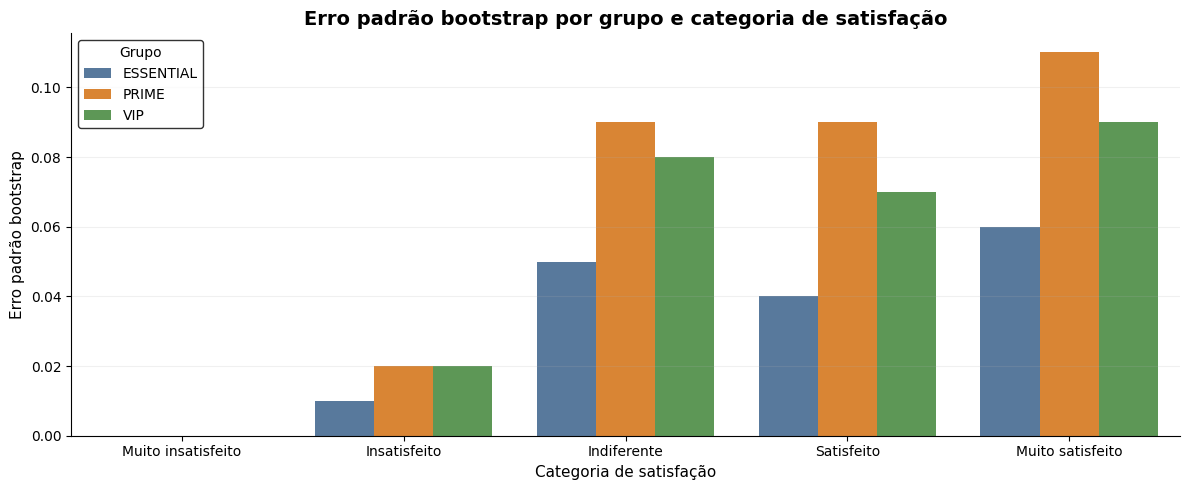

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabela_bootstrap,
    x="Categoria",
    y="Erro padrão bootstrap",
    hue="Grupo",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Erro padrão bootstrap por grupo e categoria de satisfação", fontsize=14, fontweight="bold")
plt.xlabel("Categoria de satisfação", fontsize=11)
plt.ylabel("Erro padrão bootstrap", fontsize=11)
plt.grid(axis="y", alpha=0.18)
plt.legend(title="Grupo", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()



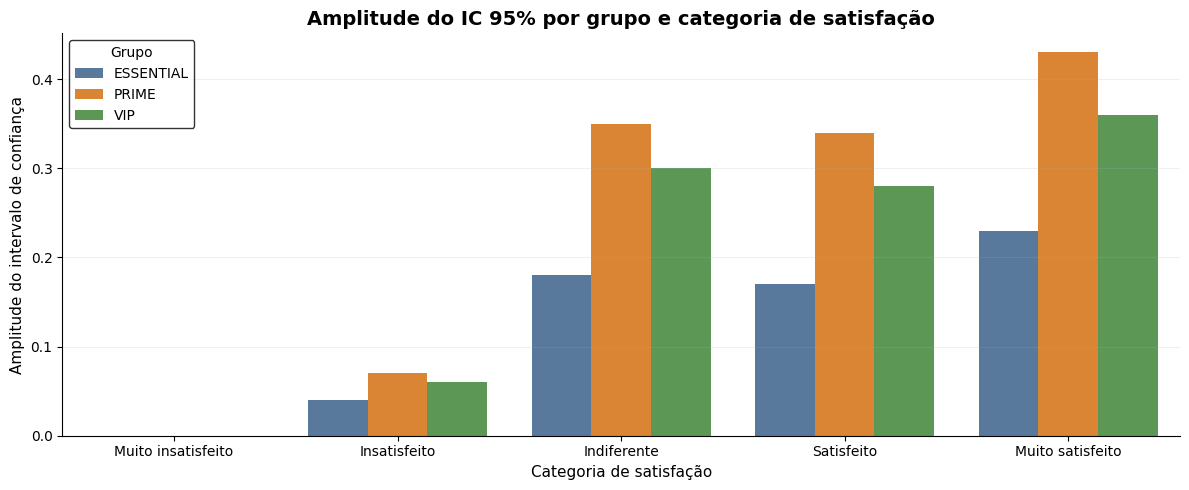

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabela_bootstrap,
    x="Categoria",
    y="Amplitude IC",
    hue="Grupo",
    palette=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Amplitude do IC 95% por grupo e categoria de satisfação", fontsize=14, fontweight="bold")
plt.xlabel("Categoria de satisfação", fontsize=11)
plt.ylabel("Amplitude do intervalo de confiança", fontsize=11)
plt.grid(axis="y", alpha=0.18)
plt.legend(title="Grupo", frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


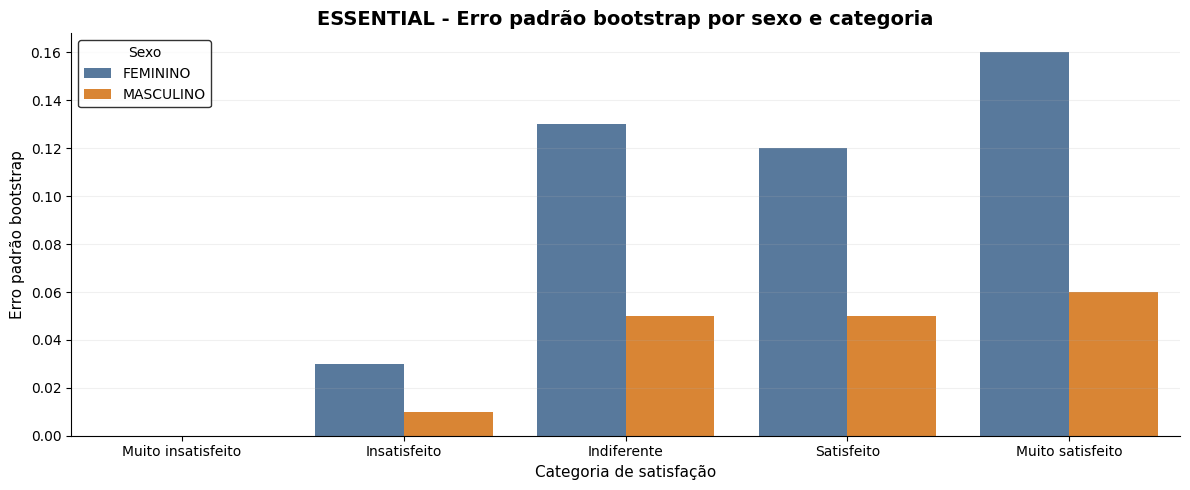

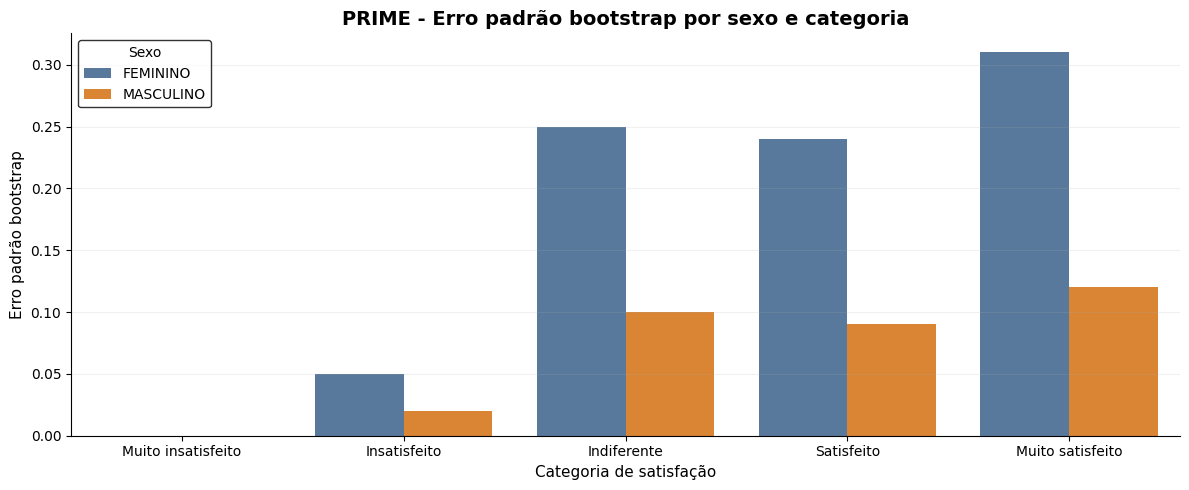

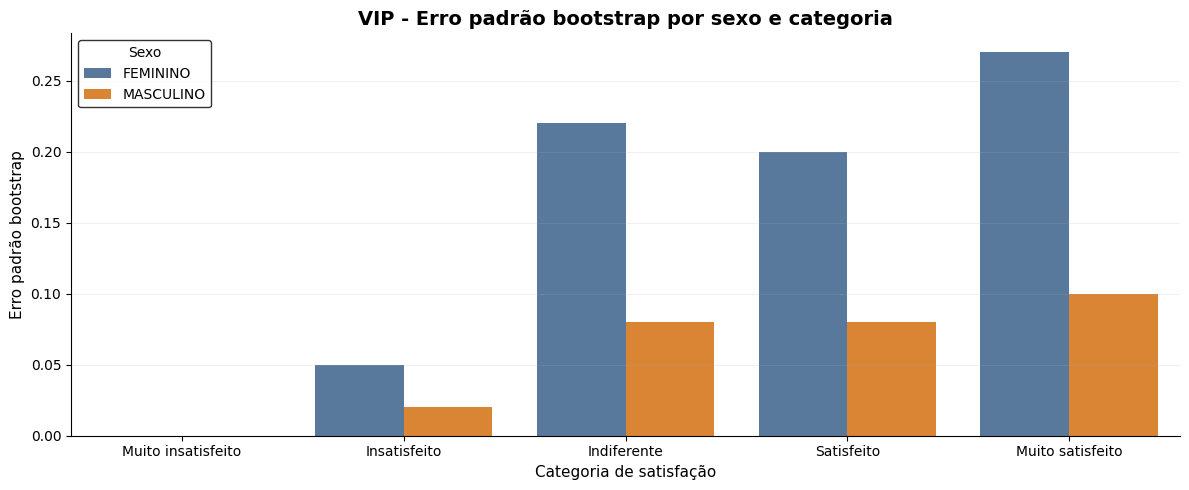

In [ ]:
for grupo in resultado["grupos"]:
    df_plot = tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=df_plot,
        x="Categoria",
        y="Erro padrão bootstrap",
        hue="Sexo",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Erro padrão bootstrap por sexo e categoria", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Erro padrão bootstrap", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.legend(title="Sexo", frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


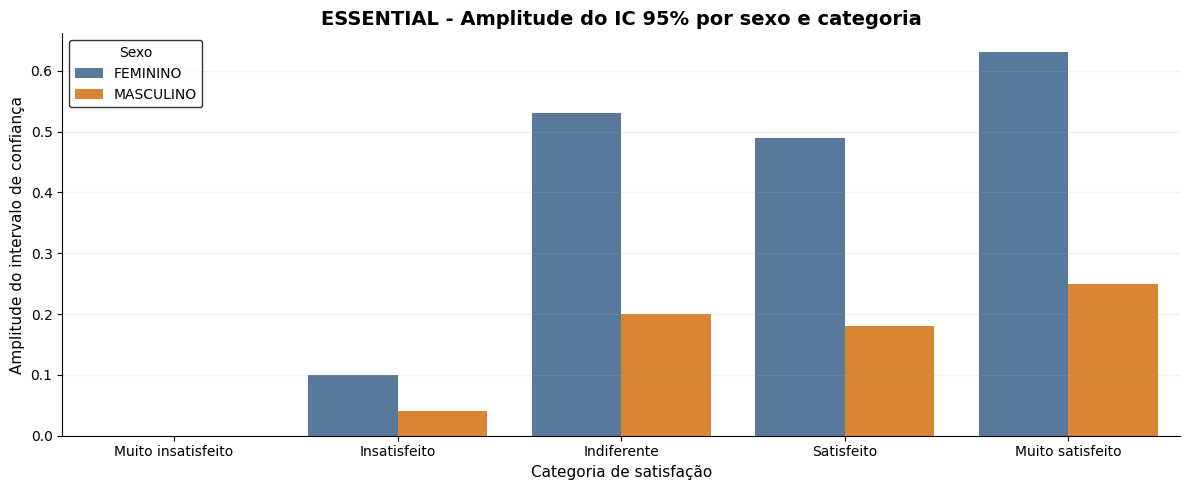

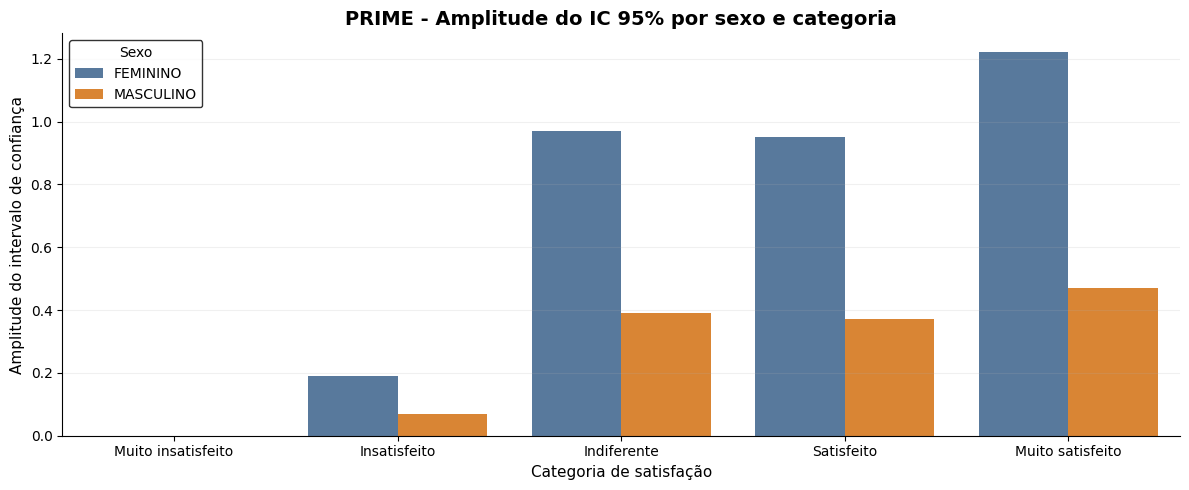

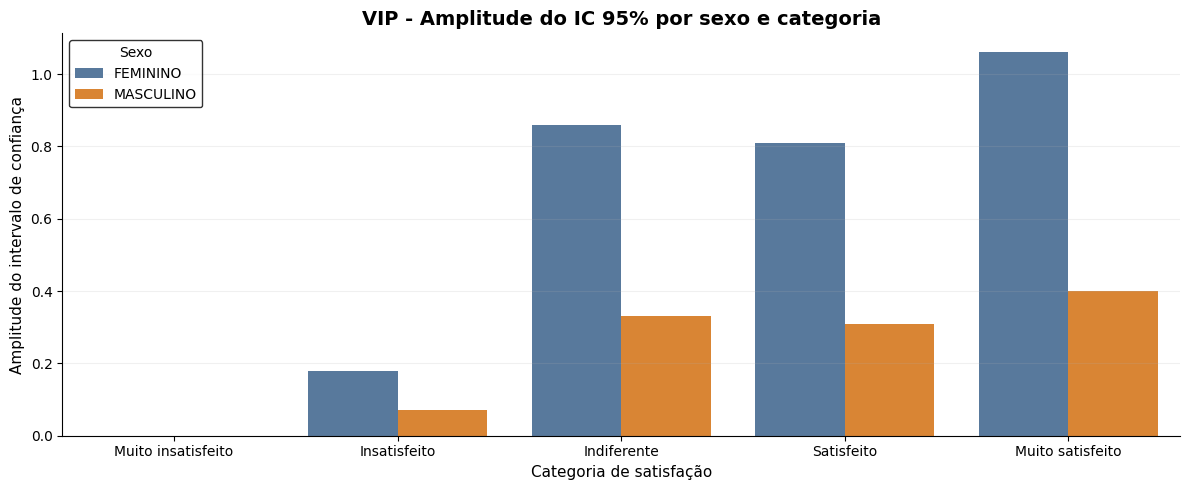

In [ ]:
for grupo in resultado["grupos"]:
    df_plot = tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=df_plot,
        x="Categoria",
        y="Amplitude IC",
        hue="Sexo",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Amplitude do IC 95% por sexo e categoria", fontsize=14, fontweight="bold")
    plt.xlabel("Categoria de satisfação", fontsize=11)
    plt.ylabel("Amplitude do intervalo de confiança", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.legend(title="Sexo", frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


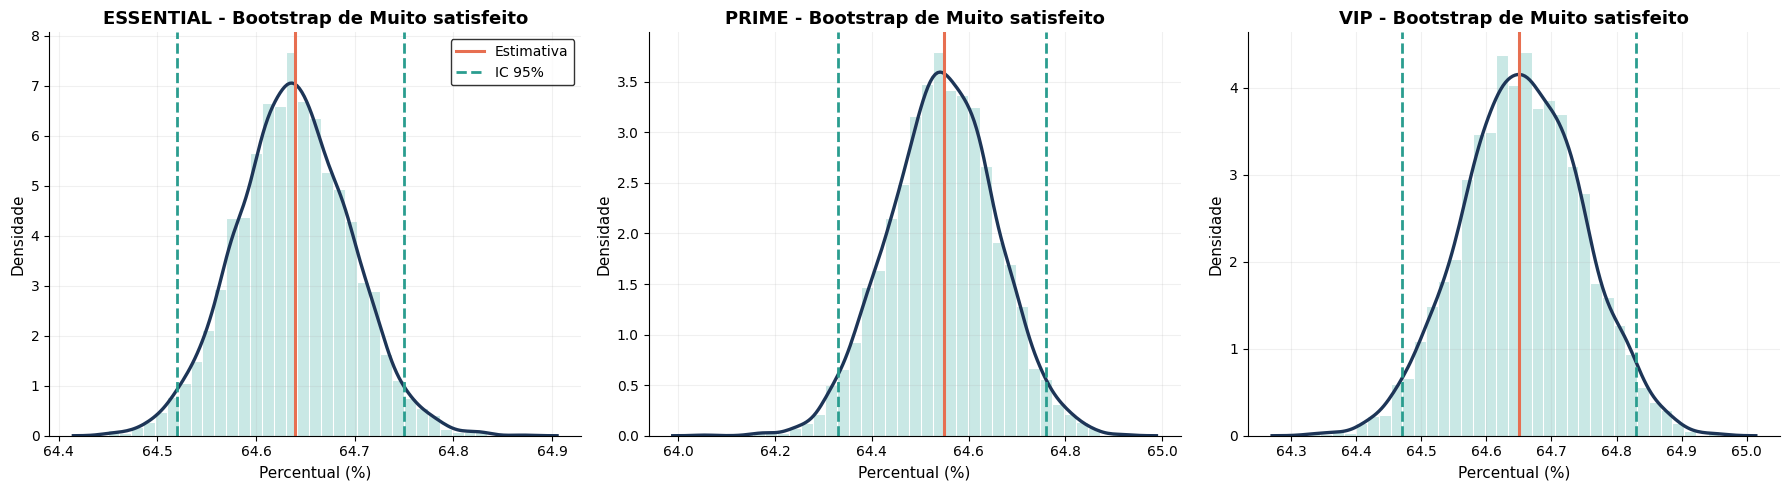

In [ ]:
categoria_plot = "Muito satisfeito"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, grupo in zip(axes, resultado["grupos"]):
    boot = resultado["bootstrap"][grupo]["geral"][categoria_plot]["bootstrap_%"]

    linha = tabela_bootstrap[
        (tabela_bootstrap["Grupo"] == grupo) &
        (tabela_bootstrap["Categoria"] == categoria_plot)
    ].iloc[0]

    estimativa = linha["Freq. (%)"]
    ic_inf = linha["IC 95% inferior"]
    ic_sup = linha["IC 95% superior"]

    sns.histplot(
        boot,
        bins=35,
        stat="density",
        color="#B8E1DD",
        edgecolor="white",
        alpha=0.75,
        ax=ax
    )

    sns.kdeplot(
        boot,
        color="#1D3557",
        linewidth=2.4,
        ax=ax
    )

    ax.axvline(estimativa, color="#E76F51", linewidth=2.2, label="Estimativa")
    ax.axvline(ic_inf, color="#2A9D8F", linestyle="--", linewidth=2, label="IC 95%")
    ax.axvline(ic_sup, color="#2A9D8F", linestyle="--", linewidth=2)

    ax.set_title(f"{grupo} - Bootstrap de {categoria_plot}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Percentual (%)", fontsize=11)
    ax.set_ylabel("Densidade", fontsize=11)
    ax.grid(alpha=0.18)

axes[0].legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


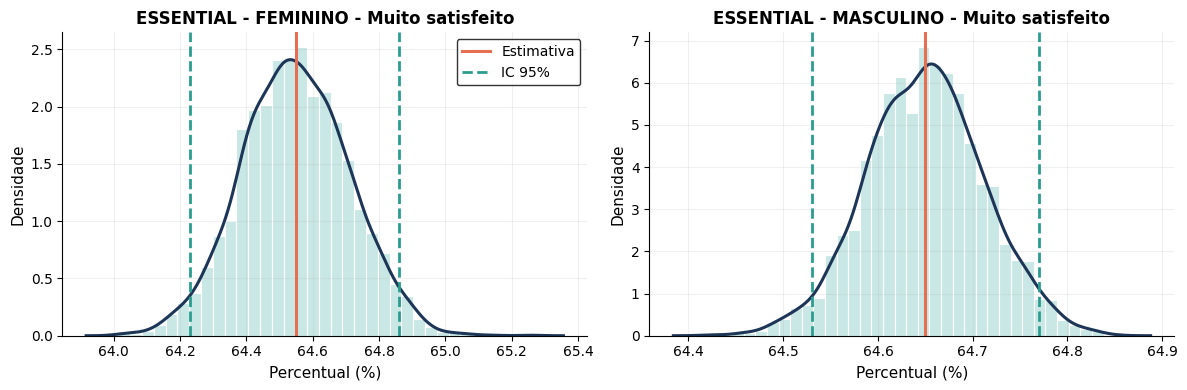

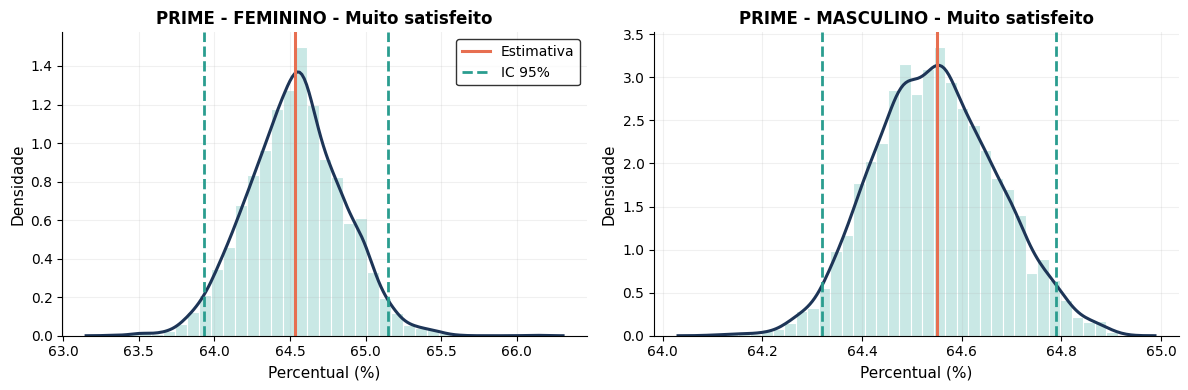

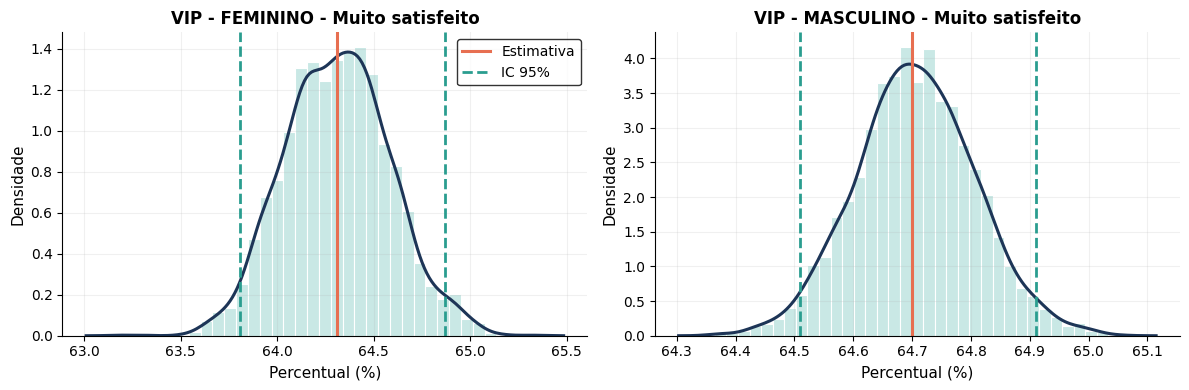

In [ ]:
categoria_plot = "Muito satisfeito"

for grupo in resultado["grupos"]:
    sexos_grupo = sorted(
        tabela_bootstrap_sexo[tabela_bootstrap_sexo["Grupo"] == grupo]["Sexo"].unique()
    )

    fig, axes = plt.subplots(1, len(sexos_grupo), figsize=(6 * len(sexos_grupo), 4))

    if len(sexos_grupo) == 1:
        axes = [axes]

    for ax, sexo in zip(axes, sexos_grupo):
        boot = resultado["bootstrap"][grupo]["por_sexo"][sexo][categoria_plot]["bootstrap_%"]

        linha = tabela_bootstrap_sexo[
            (tabela_bootstrap_sexo["Grupo"] == grupo) &
            (tabela_bootstrap_sexo["Sexo"] == sexo) &
            (tabela_bootstrap_sexo["Categoria"] == categoria_plot)
        ].iloc[0]

        estimativa = linha["Freq. (%)"]
        ic_inf = linha["IC 95% inferior"]
        ic_sup = linha["IC 95% superior"]

        sns.histplot(
            boot,
            bins=35,
            stat="density",
            color="#B8E1DD",
            edgecolor="white",
            alpha=0.75,
            ax=ax
        )

        sns.kdeplot(
            boot,
            color="#1D3557",
            linewidth=2.2,
            ax=ax
        )

        ax.axvline(estimativa, color="#E76F51", linewidth=2.2, label="Estimativa")
        ax.axvline(ic_inf, color="#2A9D8F", linestyle="--", linewidth=2, label="IC 95%")
        ax.axvline(ic_sup, color="#2A9D8F", linestyle="--", linewidth=2)

        ax.set_title(f"{grupo} - {sexo} - {categoria_plot}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Percentual (%)", fontsize=11)
        ax.set_ylabel("Densidade", fontsize=11)
        ax.grid(alpha=0.18)

    axes[0].legend(frameon=True, edgecolor="black")
    plt.tight_layout()
    sns.despine()
    plt.show()


A análise bootstrap mostrou que as estimativas percentuais das cinco categorias de satisfação são estáveis nos grupos ESSENTIAL, PRIME e VIP. Na leitura geral de cada grupo, o erro padrão bootstrap máximo foi de 0,11 ponto percentual, na categoria Muito satisfeito de PRIME, e a maior amplitude de intervalo de confiança foi de 0,43 ponto percentual, também nessa categoria.

As categorias mais frequentes tiveram erros padrão um pouco maiores em termos absolutos, mas dentro de intervalos estreitos: em Muito satisfeito, de 0,06 em ESSENTIAL, 0,11 em PRIME e 0,09 em VIP. Já Insatisfeito, com participação residual, teve erro padrão de apenas 0,01 a 0,02 e amplitude entre 0,04 e 0,07, e Muito insatisfeito ficou em zero em todas as medidas.

Na segmentação por sexo, os resultados continuaram precisos, com diferença previsível entre os dois grupos. Em Muito satisfeito, o erro padrão ficou entre 0,06 e 0,12 em MASCULINO e entre 0,16 e 0,31 em FEMININO, e a maior amplitude (1,22 ponto percentual) ocorreu em FEMININO de PRIME, o subgrupo com menos registros.

Assim, o bootstrap reforça a robustez da leitura estratificada da satisfação, tanto entre os grupos quanto dentro deles, sem sinais de instabilidade relevante nas estimativas.

###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

Nesta etapa, são reunidos os resultados obtidos nas Atividades A3.1 e A3.2, consolidando a distribuição percentual das cinco categorias de satisfação, os intervalos de confiança estimados por bootstrap e os principais indicadores utilizados para a interpretação dos resultados nos grupos `ESSENTIAL`, `PRIME` e `VIP`.

O objetivo é apresentar uma visão consolidada da pesquisa de satisfação considerando a estrutura estratificada da base, a partir de duas perspectivas complementares: a análise geral de cada grupo e a análise segmentada por sexo dentro de cada grupo. Dessa maneira, a etapa permite comparar os diferentes segmentos, identificar os níveis de satisfação predominantes, verificar a consistência estatística das estimativas e sintetizar o perfil geral de percepção dos clientes da UWine.


In [ ]:
def AtividadeA3_3():
    if "A3.1" not in RESULTADOS or "A3.2" not in RESULTADOS:
        raise ValueError("Execute as Atividades A3.1 e A3.2 antes desta etapa.")

    r31 = RESULTADOS["A3.1"]
    r32 = RESULTADOS["A3.2"]

    tabela_freq = r31["tabela_resultados"].copy()
    tabela_freq_sexo = r31["tabela_resultados_sexo"].copy()

    tabela_boot = r32["tabela_bootstrap"].copy()
    tabela_boot_sexo = r32["tabela_bootstrap_sexo"].copy()

    tabela_detalhada = tabela_freq.merge(
        tabela_boot[[
            "Grupo", "Categoria", "Erro padrão bootstrap", "Amplitude IC"
        ]],
        on=["Grupo", "Categoria"],
        how="left"
    )

    tabela_detalhada_sexo = tabela_freq_sexo.merge(
        tabela_boot_sexo[[
            "Grupo", "Sexo", "Categoria", "Erro padrão bootstrap", "Amplitude IC"
        ]],
        on=["Grupo", "Sexo", "Categoria"],
        how="left"
    )

    linhas_final = []
    linhas_final_sexo = []

    for grupo in r31["grupos"]:
        df_grupo = tabela_detalhada[tabela_detalhada["Grupo"] == grupo].copy()

        pct_muito_insatisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Muito insatisfeito", "Freq. (%)"].iloc[0])
        pct_insatisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Insatisfeito", "Freq. (%)"].iloc[0])
        pct_indiferente = float(df_grupo.loc[df_grupo["Categoria"] == "Indiferente", "Freq. (%)"].iloc[0])
        pct_satisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Satisfeito", "Freq. (%)"].iloc[0])
        pct_muito_satisfeito = float(df_grupo.loc[df_grupo["Categoria"] == "Muito satisfeito", "Freq. (%)"].iloc[0])

        positivos = pct_satisfeito + pct_muito_satisfeito
        negativos = pct_insatisfeito + pct_muito_insatisfeito
        neutros = pct_indiferente
        saldo_satisfacao = positivos - negativos

        linha_dominante = df_grupo.sort_values("Freq. (%)", ascending=False).iloc[0]
        categoria_dominante = linha_dominante["Categoria"]
        percentual_dominante = float(linha_dominante["Freq. (%)"])

        amp_media_ic = float(df_grupo["Amplitude IC"].mean())
        erro_padrao_medio = float(df_grupo["Erro padrão bootstrap"].mean())

        linhas_final.append({
            "Grupo": grupo,
            "Muito insatisfeito (%)": pct_muito_insatisfeito,
            "Insatisfeito (%)": pct_insatisfeito,
            "Indiferente (%)": pct_indiferente,
            "Satisfeito (%)": pct_satisfeito,
            "Muito satisfeito (%)": pct_muito_satisfeito,
            "Positivos (%)": positivos,
            "Neutros (%)": neutros,
            "Negativos (%)": negativos,
            "Saldo satisfação": saldo_satisfacao,
            "Categoria dominante": categoria_dominante,
            "Percentual dominante (%)": percentual_dominante,
            "Erro padrão médio": erro_padrao_medio,
            "Amplitude média IC": amp_media_ic,
        })

        sexos_grupo = sorted(
            tabela_detalhada_sexo[tabela_detalhada_sexo["Grupo"] == grupo]["Sexo"].unique()
        )

        for sexo in sexos_grupo:
            df_sub = tabela_detalhada_sexo[
                (tabela_detalhada_sexo["Grupo"] == grupo) &
                (tabela_detalhada_sexo["Sexo"] == sexo)
            ].copy()

            pct_muito_insatisfeito = float(df_sub.loc[df_sub["Categoria"] == "Muito insatisfeito", "Freq. (%)"].iloc[0])
            pct_insatisfeito = float(df_sub.loc[df_sub["Categoria"] == "Insatisfeito", "Freq. (%)"].iloc[0])
            pct_indiferente = float(df_sub.loc[df_sub["Categoria"] == "Indiferente", "Freq. (%)"].iloc[0])
            pct_satisfeito = float(df_sub.loc[df_sub["Categoria"] == "Satisfeito", "Freq. (%)"].iloc[0])
            pct_muito_satisfeito = float(df_sub.loc[df_sub["Categoria"] == "Muito satisfeito", "Freq. (%)"].iloc[0])

            positivos = pct_satisfeito + pct_muito_satisfeito
            negativos = pct_insatisfeito + pct_muito_insatisfeito
            neutros = pct_indiferente
            saldo_satisfacao = positivos - negativos

            linha_dominante = df_sub.sort_values("Freq. (%)", ascending=False).iloc[0]
            categoria_dominante = linha_dominante["Categoria"]
            percentual_dominante = float(linha_dominante["Freq. (%)"])

            amp_media_ic = float(df_sub["Amplitude IC"].mean())
            erro_padrao_medio = float(df_sub["Erro padrão bootstrap"].mean())

            linhas_final_sexo.append({
                "Grupo": grupo,
                "Sexo": sexo,
                "Muito insatisfeito (%)": pct_muito_insatisfeito,
                "Insatisfeito (%)": pct_insatisfeito,
                "Indiferente (%)": pct_indiferente,
                "Satisfeito (%)": pct_satisfeito,
                "Muito satisfeito (%)": pct_muito_satisfeito,
                "Positivos (%)": positivos,
                "Neutros (%)": neutros,
                "Negativos (%)": negativos,
                "Saldo satisfação": saldo_satisfacao,
                "Categoria dominante": categoria_dominante,
                "Percentual dominante (%)": percentual_dominante,
                "Erro padrão médio": erro_padrao_medio,
                "Amplitude média IC": amp_media_ic,
            })

    tabela_final = pd.DataFrame(linhas_final)
    tabela_final_sexo = pd.DataFrame(linhas_final_sexo)

    RESULTADOS["A3.3"] = {
        "tabela_detalhada": tabela_detalhada,
        "tabela_detalhada_sexo": tabela_detalhada_sexo,
        "tabela_final": tabela_final,
        "tabela_final_sexo": tabela_final_sexo,
    }

    print("Resultado final da pesquisa de satisfação consolidado.")
    print(f"Grupos analisados: {len(tabela_final)}")
    print("Também foi consolidada a leitura por sexo dentro de cada grupo.")


In [ ]:
AtividadeA3_3()
resultado = RESULTADOS["A3.3"]

Resultado final da pesquisa de satisfação consolidado.
Grupos analisados: 3
Também foi consolidada a leitura por sexo dentro de cada grupo.


In [ ]:
tabela_final = resultado["tabela_final"].copy()

colunas_round = [
    "Muito insatisfeito (%)",
    "Insatisfeito (%)",
    "Indiferente (%)",
    "Satisfeito (%)",
    "Muito satisfeito (%)",
    "Positivos (%)",
    "Neutros (%)",
    "Negativos (%)",
    "Saldo satisfação",
    "Percentual dominante (%)",
    "Erro padrão médio",
    "Amplitude média IC",
]

tabela_final[colunas_round] = tabela_final[colunas_round].round(2)

display(tabela_final)


,Grupo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
0,ESSENTIAL,0.0,0.60,18.62,16.14,64.64,80.78,18.62,0.60,80.18,Muito satisfeito,64.64,0.03,0.12
1,PRIME,0.0,0.60,18.52,16.33,64.55,80.88,18.52,0.60,80.28,Muito satisfeito,64.55,0.06,0.24
2,VIP,0.0,0.61,18.57,16.16,64.65,80.82,18.57,0.61,80.21,Muito satisfeito,64.65,0.05,0.20


In [ ]:
tabela_final_sexo = resultado["tabela_final_sexo"].copy()
tabela_final_sexo[colunas_round] = tabela_final_sexo[colunas_round].round(2)

for grupo in resultado["tabela_final"]["Grupo"]:
    print(f"\nGrupo: {grupo} - resultado final por sexo")
    display(
        tabela_final_sexo[tabela_final_sexo["Grupo"] == grupo]
    )



Grupo: ESSENTIAL - resultado final por sexo


,Grupo,Sexo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
0,ESSENTIAL,FEMININO,0.0,0.6,18.82,16.03,64.55,80.58,18.82,0.6,79.98,Muito satisfeito,64.55,0.09,0.35
1,ESSENTIAL,MASCULINO,0.0,0.6,18.59,16.16,64.65,80.81,18.59,0.6,80.21,Muito satisfeito,64.65,0.03,0.13



Grupo: PRIME - resultado final por sexo


,Grupo,Sexo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
2,PRIME,FEMININO,0.0,0.56,18.48,16.43,64.53,80.95,18.48,0.56,80.39,Muito satisfeito,64.53,0.17,0.67
3,PRIME,MASCULINO,0.0,0.61,18.53,16.32,64.55,80.87,18.53,0.61,80.26,Muito satisfeito,64.55,0.07,0.26



Grupo: VIP - resultado final por sexo


,Grupo,Sexo,Muito insatisfeito (%),Insatisfeito (%),Indiferente (%),Satisfeito (%),Muito satisfeito (%),Positivos (%),Neutros (%),Negativos (%),Saldo satisfação,Categoria dominante,Percentual dominante (%),Erro padrão médio,Amplitude média IC
4,VIP,FEMININO,0.0,0.67,18.94,16.08,64.31,80.39,18.94,0.67,79.73,Muito satisfeito,64.31,0.15,0.58
5,VIP,MASCULINO,0.0,0.60,18.52,16.18,64.70,80.88,18.52,0.60,80.28,Muito satisfeito,64.70,0.06,0.22


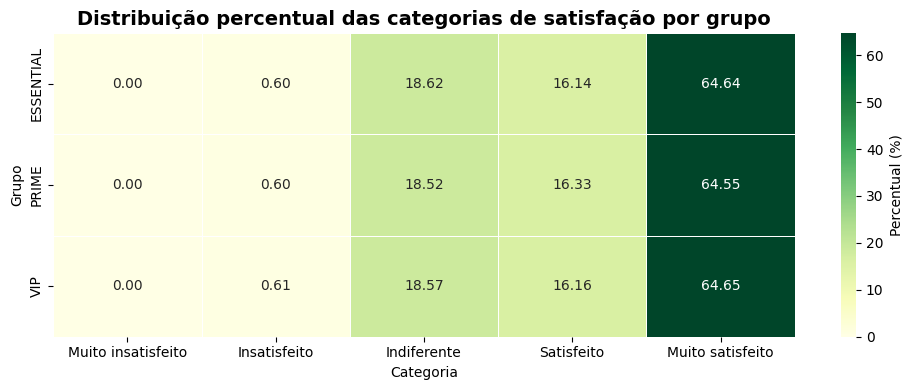

In [ ]:
heatmap_df = resultado["tabela_detalhada"].pivot(
    index="Grupo",
    columns="Categoria",
    values="Freq. (%)"
)[[
    "Muito insatisfeito",
    "Insatisfeito",
    "Indiferente",
    "Satisfeito",
    "Muito satisfeito"
]]

plt.figure(figsize=(10, 4))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="YlGn",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Percentual (%)"}
)

plt.title("Distribuição percentual das categorias de satisfação por grupo", fontsize=14, fontweight="bold")
plt.xlabel("Categoria")
plt.ylabel("Grupo")
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()


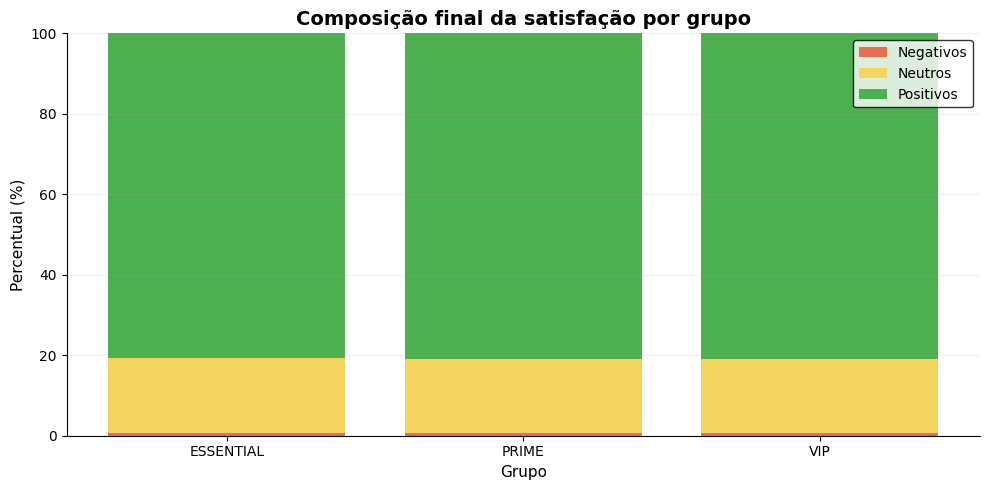

In [ ]:
plot_df = tabela_final.copy()

plt.figure(figsize=(10, 5))

plt.bar(plot_df["Grupo"], plot_df["Negativos (%)"], color="#E76F51", label="Negativos")
plt.bar(plot_df["Grupo"], plot_df["Neutros (%)"], bottom=plot_df["Negativos (%)"], color="#F4D35E", label="Neutros")
plt.bar(
    plot_df["Grupo"],
    plot_df["Positivos (%)"],
    bottom=plot_df["Negativos (%)"] + plot_df["Neutros (%)"],
    color="#4CAF50",
    label="Positivos"
)

plt.title("Composição final da satisfação por grupo", fontsize=14, fontweight="bold")
plt.xlabel("Grupo", fontsize=11)
plt.ylabel("Percentual (%)", fontsize=11)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.18)
plt.legend(frameon=True, edgecolor="black")
plt.tight_layout()
sns.despine()
plt.show()


/tmp/ipykernel_2450/2303619261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


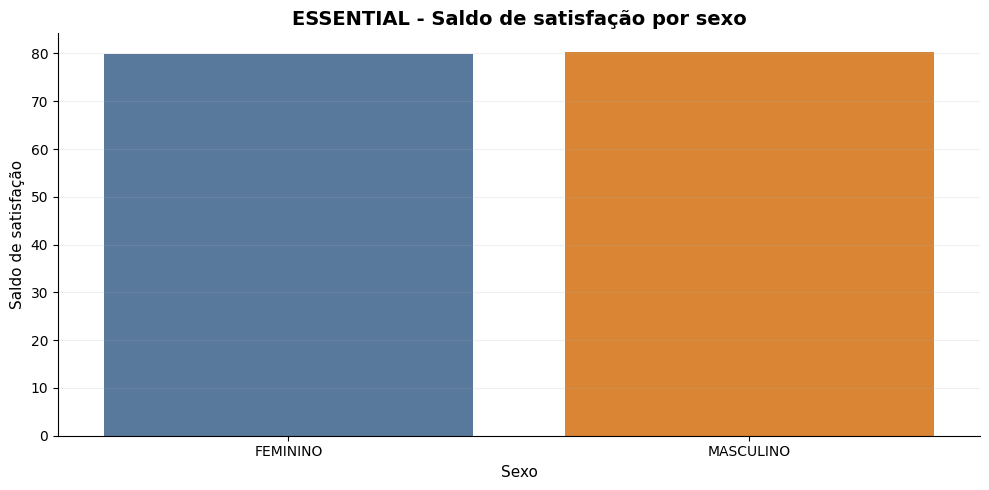

/tmp/ipykernel_2450/2303619261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


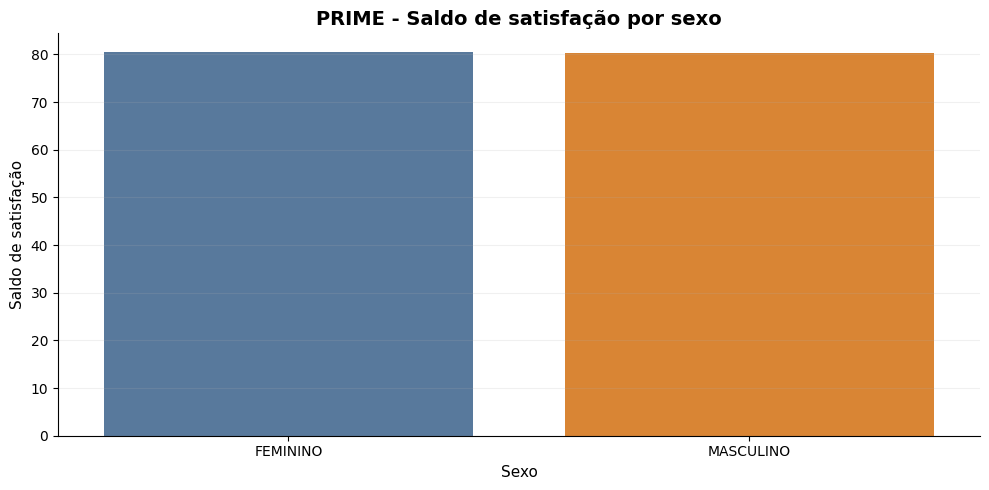

/tmp/ipykernel_2450/2303619261.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


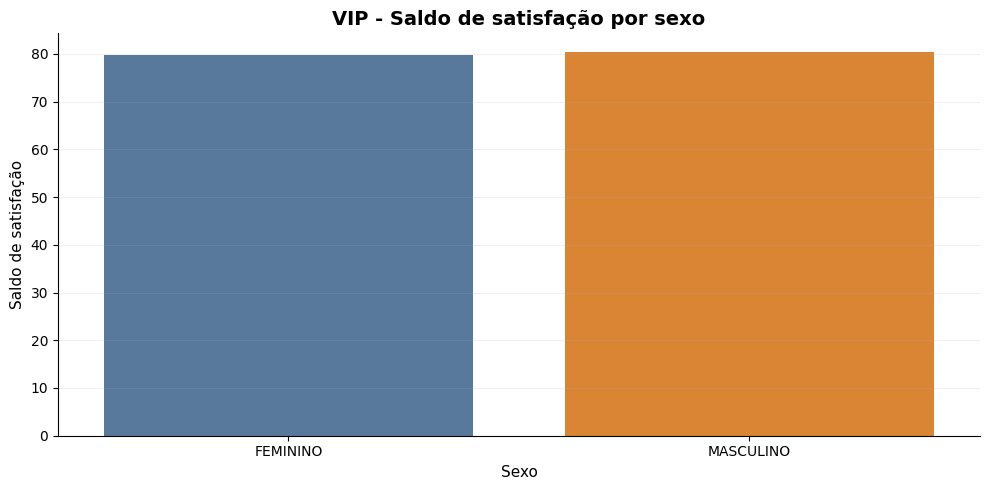

In [ ]:
for grupo in tabela_final_sexo["Grupo"].unique():
    df_plot = tabela_final_sexo[tabela_final_sexo["Grupo"] == grupo].copy()

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=df_plot,
        x="Sexo",
        y="Saldo satisfação",
        palette=["#4C78A8", "#F58518"]
    )

    plt.title(f"{grupo} - Saldo de satisfação por sexo", fontsize=14, fontweight="bold")
    plt.xlabel("Sexo", fontsize=11)
    plt.ylabel("Saldo de satisfação", fontsize=11)
    plt.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    sns.despine()
    plt.show()


In [ ]:
ranking = tabela_final[[
    "Grupo", "Positivos (%)", "Negativos (%)", "Saldo satisfação", "Categoria dominante"
]].sort_values("Saldo satisfação", ascending=False)

display(ranking.round(2))


,Grupo,Positivos (%),Negativos (%),Saldo satisfação,Categoria dominante
1,PRIME,80.88,0.60,80.28,Muito satisfeito
2,VIP,80.82,0.61,80.21,Muito satisfeito
0,ESSENTIAL,80.78,0.60,80.18,Muito satisfeito


In [ ]:
ranking_sexo = tabela_final_sexo[[
    "Grupo", "Sexo", "Positivos (%)", "Negativos (%)", "Saldo satisfação", "Categoria dominante"
]].sort_values(["Grupo", "Saldo satisfação"], ascending=[True, False])

display(ranking_sexo.round(2))


,Grupo,Sexo,Positivos (%),Negativos (%),Saldo satisfação,Categoria dominante
1,ESSENTIAL,MASCULINO,80.81,0.60,80.21,Muito satisfeito
0,ESSENTIAL,FEMININO,80.58,0.60,79.98,Muito satisfeito
2,PRIME,FEMININO,80.95,0.56,80.39,Muito satisfeito
3,PRIME,MASCULINO,80.87,0.61,80.26,Muito satisfeito
5,VIP,MASCULINO,80.88,0.60,80.28,Muito satisfeito
4,VIP,FEMININO,80.39,0.67,79.73,Muito satisfeito


Na consolidação final, as respostas positivas (Satisfeito e Muito satisfeito) somaram 80,78% em ESSENTIAL, 80,88% em PRIME e 80,82% em VIP, enquanto as respostas negativas ficaram em 0,60%, 0,60% e 0,61%, respectivamente. As respostas neutras (Indiferente) representaram cerca de 18,5% a 18,6%. O saldo de satisfação foi, portanto, amplamente favorável e praticamente igual entre os segmentos: 80,18 em ESSENTIAL, 80,28 em PRIME e 80,21 em VIP.

A leitura por sexo confirmou esse padrão. Em todos os grupos e em ambos os sexos, Muito satisfeito foi a categoria dominante, e os percentuais de respostas positivas variaram apenas de 80,39% a 80,95%. O menor saldo foi o de FEMININO em VIP (79,73) e o maior, o de FEMININO em PRIME (80,39), diferença inferior a 0,7 ponto.

A análise bootstrap confirmou a precisão dessas estimativas. O erro padrão médio foi de 0,03 em ESSENTIAL, 0,06 em PRIME e 0,05 em VIP, com amplitudes médias de intervalo de confiança de 0,12, 0,24 e 0,20 ponto percentual. Na segmentação por sexo, os intervalos de FEMININO foram mais largos (amplitude média de 0,35 a 0,67) que os de MASCULINO (0,13 a 0,26), mas ainda estreitos.

Conclui-se que a pesquisa de satisfação revela uma percepção amplamente positiva, homogênea entre ESSENTIAL, PRIME e VIP e estatisticamente estável também entre homens e mulheres dentro de cada grupo.

# RELATÓRIO FINAL - PARTE 1

# Análise Estatística da Base de Clientes — UWine

## 1. Introdução
O relatório reúne os resultados da Parte 1 do projeto UWine: estratificação amostral, testes de hipóteses, estatística descritiva e pesquisa de satisfação. A pergunta central é: **qual é o tamanho ideal da amostra para representar a população de clientes?** Como os grupos ESSENTIAL, PRIME e VIP se comportam de forma diferente, a análise foi feita por grupo, e não apenas de forma global.

## 2. Atividade A1 — Estratificação Amostral

### 2.1 Tamanho ideal da amostra

O tamanho ideal foi definido pela estabilização do erro-padrão da média de `TOTAL (R$)`, escolhendo o menor n cujo erro-padrão fica menor ou igual ao erro-padrão médio. Na base inteira, o resultado foi de 51.400 observações. Por grupo, foi de:

- ESSENTIAL: 50.900 observações
- PRIME: 47.500 observações
- VIP: 51.500 observações

### 2.2 Qualidade dos dados

Não houve valores negativos nas variáveis monetárias, e os extremos altos foram mantidos, pois podem representar clientes de maior valor. Já `NOTA DE SATISFAÇÃO (%)` se concentrou em 68,68 (92,575% da base, 100% em ESSENTIAL e 99,96% em VIP), e por isso a satisfação foi analisada pela variável `OPINIÃO DO CLIENTE`.

### 2.3 Testes de hipóteses e validação

Cada grupo gerou 20 rodadas válidas de reamostragem, com taxas de aceite de 39,22% em ESSENTIAL, 57,14% em PRIME e 29,85% em VIP. Os testes mostraram que:

- O Shapiro-Wilk rejeitou a normalidade de `TOTAL (R$)` nos três grupos.
- O Qui-Quadrado indicou que a permanência dentro do intervalo de confiança depende da partição (p entre 0,0001 e 0,0089), com TRAIN mais estável.
- O Levene não rejeitou a homogeneidade de variâncias entre as partições (p entre 0,0552 e 0,5173).
- O Friedman, com o pós-teste de Holm, não encontrou diferença de médias entre TRAIN, VALIDATION e TEST (p entre 0,3499 e 0,8607).
- O bootstrap da diferença entre média amostral e média populacional teve intervalo de confiança incluindo zero em todas as rodadas aceitas.

Assim, apesar da não normalidade, as amostras aceitas são estáveis e compatíveis com a população de cada grupo.

## 3. Atividade A2 — Estatística Descritiva

### 3.1 Variáveis quantitativas

ESSENTIAL tem os menores níveis (médias de 3.651,78 em `RENDA BRUTO (R$)` e 403,87 em `TOTAL (R$)`) e forte assimetria positiva (5,86 e 5,02). PRIME tem os maiores (19.912,56 e 2.192,33), com `TOTAL (R$)` mais regular (assimetria de 0,19) e renda com assimetria negativa (-1,60). VIP fica no meio (8.242,14 e 907,18) e tem mais extremos em renda (12,05%). A base é, portanto, heterogênea entre os grupos.

### 3.2 Variáveis qualitativas

Os três grupos têm perfis muito parecidos: SUDESTE em cerca de 67% dos registros, MASCULINO em cerca de 87%, CASADO em cerca de 55% e DEPENDENTES igual a 1 em cerca de 53%. `OPINIÃO DO CLIENTE` é a mais diversa, com 25 categorias e nenhuma acima de 15,6%.

## 4. Resultado da Pesquisa de Satisfação

A opinião foi classificada em cinco níveis, e o padrão é muito parecido entre os grupos:

- Muito satisfeito: 64,64% (ESSENTIAL), 64,55% (PRIME) e 64,65% (VIP)
- Indiferente: cerca de 18,6%
- Satisfeito: cerca de 16,2%
- Insatisfeito: cerca de 0,6%
- Muito insatisfeito: nenhuma ocorrência

As respostas positivas somam entre 80,78% e 80,88%, e o saldo de satisfação fica entre 80,18 e 80,28. Por sexo, o padrão se repete, com Muito satisfeito dominante em todos os casos. O bootstrap confirmou a precisão dos resultados, com erros padrão médios de até 0,06 ponto percentual por grupo.

## 5. Conclusão — Resposta à Pergunta Principal

**Qual é o tamanho ideal da amostra?**

Não há um único tamanho ideal para toda a população quando se respeita a estrutura da base. A resposta é dada por grupo: **50.900 observações em ESSENTIAL, 47.500 em PRIME e 51.500 em VIP**. O valor global, de 51.400, serve como referência. Os pontos que sustentam essa resposta são:

1. Os grupos têm comportamentos estatísticos distintos, o que impede tratar a base como homogênea.
2. A amostragem estratificada gerou 20 rodadas válidas em cada grupo.
3. As partições foram validadas com o intervalo de confiança de cada grupo e não diferem em média nem em variância.
4. O bootstrap mostrou compatibilidade entre médias amostrais e populacionais.
5. A estatística descritiva mostrou diferenças relevantes entre os grupos.
6. A satisfação é estável entre os grupos, o que reforça a coerência da segmentação.

## 6. Considerações Finais

A Parte 1 mostrou que a base da UWine é heterogênea, com assimetria e caudas longas nas variáveis monetárias, mas que uma abordagem estratificada permite representá-la de forma adequada. Essa estratégia sustenta as próximas etapas do projeto.

In [1]:
!jupyter nbconvert --to html --no-input --no-prompt "/content/ERICK_MACHADO_WORKFLOW_PARTE_1.ipynb"

[NbConvertApp] Converting notebook /content/ERICK_MACHADO_WORKFLOW_PARTE_1.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 71 image(s).
[NbConvertApp] Writing 6358376 bytes to /content/ERICK_MACHADO_WORKFLOW_PARTE_1.html
